# Vessel-Guided Curriculum Learning with Uncertainty Calibration
**Long-Tailed Multi-Disease Retinal Fundus Classification — RFMiD · v8**

| Stage | Module | Trainable |
|:--|:--|:--|
| 0 | Preprocessing — FOV crop, CLAHE, resize | — |
| 1a | Vessel prior — `hrm_unet_drive.pth` | frozen |
| 1b | Backbone — DenseNet-121 (ImageNet) **or RETFound ViT-L/16 (v8 trial)** | yes |
| 2 | Vessel-guided attention fusion (3 scales) | yes |
| 3 | Head — GAP → dropout → one sigmoid per retained class | yes |
| 4 | Calibration — chained: Temperature → class-wise scaling, **fit on out-of-fold predictions** | post-hoc |
| 5 | Recipe E/G — Asymmetric Loss, mixup, SWA (§15a/§15b) | training-time |

### What v8 changes (full rationale in §15c)

| # | Change | Why |
|:--|:--|:--|
| 1 | **5-fold CV on train+val** (2,560 images); calibration and F1 thresholds fit on **out-of-fold** predictions; paired bootstrap between recipes | v7's gains (+0.012 mAP) were inside the noise of 3 seeds on ~5 test positives per tail class |
| 2 | **Regularisation regime**: 20 epochs, layer-wise LR decay, real weight decay, more dropout, lesion-preserving augmentation (early stopping available, off by default) | v7 train loss reached 0.03 (BCE) / 0.008 (ASL) while val mAP plateaued at ~0.58–0.60 and test mAP was 0.54 — a large generalisation gap |
| 3 | **Higher input resolution** (224 → 320 / 384) and a **RETFound** ViT-L trial | 224 px loses microaneurysms/drusen; a fundus-pretrained backbone is the strongest lever on 2.5k images |
| 4 | **v7's "G" changes ablated one at a time** on top of recipe E | G changed seven things at once and lost 0.05 mAP — nobody knows which change hurt |

**Evaluation protocol.** The 25 classes are the same as v7. The official 640-image test split is used *only* for the final per-fold / ensemble scores. Model selection, early stopping, calibration and F1 thresholds only ever see the held-out CV fold or out-of-fold predictions.

**Before running, set:** `CFG.RFMID_ROOT`, `CFG.VESSEL_CKPT` in §2. Optional: `CFG.REUSE_VESSEL_DIR` (v7's `*_ves_256.npy`, saves ~19 min), and an `HF_TOKEN` secret for RETFound (§15c). Set `CFG.SMOKE_TEST = True` first for a ~15 min end-to-end check. Run cells top to bottom; every finished fold is cached on disk, so a restart resumes where it stopped.

**Rough T4 budget (all switches on):** cache 10–30 min · stage 1 (4 recipes × 5 folds) ~85 min · resolution sweep ~90 min · RETFound trial ~25 min · ablation (8 recipes × 5 folds) ~3.3 h · total ≈ 7 h (limit on Kaggle is 12 h). Turn off `RUN_LONG_VARIANTS` (−80 min), `RUN_V7_REGIME` (−30 min) or `RUN_RES_SWEEP` (−90 min) to shorten; estimates are for a T4 and unmeasured.

---
## 1. Environment

In [30]:
import subprocess, sys, importlib

def ensure(pkg, import_name=None):
    try:
        importlib.import_module(import_name or pkg)
    except ImportError:
        print(f"installing {pkg} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

for p, i in [("opencv-python-headless", "cv2"), ("scikit-learn", "sklearn"),
             ("pandas", "pandas"), ("matplotlib", "matplotlib"), ("tqdm", "tqdm"),
             ("timm", "timm"), ("huggingface_hub", "huggingface_hub")]:   # v8: timm + hf hub for RETFound
    ensure(p, i)

import torch
print("torch      :", torch.__version__)
print("CUDA avail :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU        :", torch.cuda.get_device_name(0))
    print("VRAM       : %.1f GB" % (torch.cuda.get_device_properties(0).total_memory / 1e9))
else:
    print("WARNING: no GPU. Runtime > Change runtime type > T4 GPU.")

torch      : 2.11.0+cu128
CUDA avail : True
GPU        : Tesla T4
VRAM       : 15.6 GB


In [31]:
import os, gc, json, math, time, random, warnings, hashlib
from pathlib import Path
from dataclasses import dataclass, field, asdict
from typing import Optional

import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.checkpoint
from torch.utils.data import Dataset, DataLoader, Sampler
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
cv2.setNumThreads(0)                      # avoid oversubscribing the notebook's few vCPUs
matplotlib.rcParams["figure.dpi"] = 110

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed: int = 42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True          # fixed input size per run -> autotune helps
    torch.backends.cudnn.deterministic = False     # determinism would cost ~25% speed

set_seed(42)
print("device:", DEVICE)

device: cuda


---
## 2. Configuration

All knobs in one place. Cache at 256, train at 224 — the margin absorbs random zoom/shift.
The segmenter runs at 512 because capillaries vanish at 224; its output is then downsampled.

In [32]:
class CFG:
    # ---- paths -------------------------------------------------------------
    RFMID_ROOT   = "/kaggle/input/datasets/dhirajskitchen/rfmid-dataset/A. RFMiD_All_Classes_Dataset"   # folder containing 1. Original Images/, 2. Groundtruths/
    VESSEL_CKPT  = "/kaggle/input/datasets/dhirajskitchen/vessel-weights/hrm_unet_drive.pth"
    WORK_DIR     = "/kaggle/working/work"    # caches, checkpoints, figures
    PRECOMPUTED_VESSEL_DIR = None
    # v8: skip the ~19 min vessel-segmentation pass by pointing this at a folder (searched
    # recursively) that holds v7's {train,val,test}_ves_256.npy. Leave None to recompute.
    REUSE_VESSEL_DIR = None

    # ---- v8 evaluation protocol (Section 3b) --------------------------------
    SMOKE_TEST = False     # True -> 2 epochs and fold 0 only: an end-to-end check in ~15 min
    N_FOLDS    = 5         # K-fold CV over train+val (2,560 images); the official test split stays untouched
    CV_SEED    = 42
    SEED       = 42
    N_BOOT     = 300       # paired-bootstrap resamples for recipe-vs-recipe comparisons

    # ---- image / cache -----------------------------------------------------
    # v8: images are cached ONCE at 448 so the resolution sweep (224/320/384) needs no
    # rebuild; vessel maps stay at 256 (they are smooth and are average-pooled down to
    # <=48x48 by the gates anyway) and are bilinearly resized on the GPU.
    CACHE_SIZE        = 448
    VESSEL_CACHE_SIZE = 256
    INPUT_SIZE        = 224     # default network input; per-recipe override in Recipe.input_size
    PRE_RATIO         = 256 / 224   # augmentation works on a (INPUT_SIZE * PRE_RATIO) canvas, as in v7
    # --- vessel segmenter: these MUST mirror HRM_UNet_DRIVE.ipynb ---------
    VESSEL_INFER_SIZE  = 512    # keeps vessel width in pixels close to DRIVE's
    VESSEL_PATCH       = 64     # training patch size
    VESSEL_STRIDE      = 32     # sliding-window stride (50% overlap, as in training)
    VESSEL_PATCH_BATCH = 512    # patches per forward; raise if VRAM allows
    VESSEL_USE_CLAHE   = False  # segmenter trained on raw grayscale, not CLAHE
    LOAD_CACHE_IN_RAM = True    # ~2.1 GB at 448; makes dataloading essentially free

    # ---- preprocessing -----------------------------------------------------
    CLAHE_CLIP = 2.0
    CLAHE_GRID = 8
    FOV_THRESH = 10             # intensity below this is treated as outside the FOV

    # ---- model -------------------------------------------------------------
    BACKBONE   = "densenet121"
    PRETRAINED = True
    HEAD_DROPOUT    = 0.3       # v8: was 0.2. Also the MC-dropout source.
    DENSE_DROP_RATE = 0.1       # v8: dropout inside every dense layer (torchvision drop_rate)
    FUSION_STAGES = (1, 2, 3)   # inject vessel attention after transition1/2/3

    # ---- optimisation (v8: anti-overfitting regime, Section 12) --------------
    EPOCHS        = 20          # v8: was 30. Val mAP plateaus by ~epoch 15-20 and keeps a small drift after.
    PATIENCE      = None        # early stopping is implemented (e.g. 6) but OFF by default: v7's val-mAP is noisy
                                # (+-0.015 epoch to epoch) and still gained ~0.02 while the cosine LR annealed,
                                # so a patience rule would stop runs too early. Ignored when SWA is on.
    BATCH_SIZE    = 32
    LR_BACKBONE   = 1e-4        # LR of the TOP backbone stage; lower stages get LAYER_DECAY^k of it
    LR_NEW        = 1e-3        # fusion gates + head learn faster than the backbone
    LAYER_DECAY   = 0.8         # v8: layer-wise LR decay (1.0 = off, as in v7)
    WEIGHT_DECAY  = 0.05        # v8: was 1e-4 (AdamW's decoupled decay is lr*wd per step, so 1e-4 did almost nothing)
    WARMUP_EPOCHS = 1
    GRAD_CLIP     = 5.0
    AMP           = True
    NUM_WORKERS   = 2
    AUG_STRONG    = True        # v8: + channel gain, saturation, mild blur, sensor noise (all lesion-preserving)
    LOG_EVERY     = 5           # print an epoch line every N epochs

    # ---- v8: resolution sweep (change 3a) ----------------------------------
    RES_SWEEP = (320, 384)      # DenseNet-121 input sizes tried on top of 224

    # ---- v8: RETFound trial (change 3b) --------------------------------------
    # RETFound = ViT-L/16 masked-autoencoder pretrained on ~900k colour fundus photographs.
    # The weights are GATED on Hugging Face: request access on the model page, then add an
    # HF_TOKEN secret (Kaggle: Add-ons > Secrets) or set the HF_TOKEN env var. Or download the
    # .pth yourself and point RETFOUND_LOCAL at it / attach it as a Kaggle dataset.
    RETFOUND_REPO   = "YukunZhou/RETFound_mae_natureCFP"
    RETFOUND_FILE   = "RETFound_mae_natureCFP.pth"
    RETFOUND_LOCAL  = None
    RETFOUND_FOLDS  = (0,)      # trial = fold 0 only (a ViT-L fold costs ~10 min on a T4)
    RETFOUND_EPOCHS = 12
    RETFOUND_BATCH  = 16
    RETFOUND_ACCUM  = 2         # effective batch 32
    RETFOUND_LR_BACKBONE = 1e-4
    RETFOUND_LR_NEW      = 1e-3
    RETFOUND_LAYER_DECAY = 0.75
    RETFOUND_DROP_PATH   = 0.2
    RETFOUND_STAGES      = (8, 16, 24)   # vessel gates after these transformer blocks

    # ---- experiment switches ------------------------------------------------
    RUN_V7_REGIME   = True      # re-run A under v7's old regime to measure what change 2 bought
    RUN_RES_SWEEP   = True
    RUN_RETFOUND    = True
    RUN_ABLATION    = True      # change 4: add G's changes to E one at a time
    RUN_LONG_VARIANTS = False   # the 45-epoch rows of the ablation (~80 extra minutes)
    ABLATION_FOLDS  = (0, 1, 2) # folds used for the ablation (None = all). Comparisons use the folds both recipes share.

    # ---- long-tail / curriculum -------------------------------------------
    CURR_STAGE1_FRAC = 0.25     # fraction of epochs spent in the warm-up stage
    CURR_START_PACE  = 0.60     # easiest 60% of samples visible at epoch 0
    CURR_ANNEAL_END  = 0.75     # pace reaches 1.0 by 75% of training
    DRW_START_FRAC   = 0.5      # deferred re-weighting kicks in at 50% of training
    POS_WEIGHT_CAP   = 20.0     # clamp inverse-frequency weights; uncapped -> tail blows up
    BALANCED_SAMPLING = True    # class-rarity loss weight applied continuously (not just a late stage)
    DIFF_W = dict(rarity=0.15, cardinality=0.15, loss=0.55, misalign=0.15)
    LOSS_EMA = 0.7

    # ---- calibration -------------------------------------------------------
    N_BINS       = 15
    MC_SAMPLES   = 20
    ECE_ADAPTIVE = True   # equal-mass bins; equal-width is degenerate here
    MIN_EVAL_POS = 5      # min positives for a class to enter mAP_tail_ok
    MIN_TRAIN_POS = 10    # classes below this many ORIGINAL-train positives are dropped (keeps v7's 25-class set)
    CURR_SOFT_FLOOR = 0.1  # soft curriculum: minimum loss weight for the hardest samples (never fully excluded)
    CURR_SOFT_TEMP  = 0.12 # sigmoid width of the pace transition, in difficulty-percentile units

    # ---- v6 recipe constants (Section 15a) ----------------------------------
    LOSS_TYPE     = "bce"   # "bce" or "asl"
    ASL_GAMMA_POS = 1.0     # Ridnik et al. 2021 defaults
    ASL_GAMMA_NEG = 4.0
    ASL_CLIP      = 0.05
    MIXUP_ALPHA   = 0.2     # Beta(alpha, alpha) mixing coefficient; 0 disables mixup
    MIXUP_PROB    = 0.5     # fraction of batches mixed, when enabled
    SWA_START_FRAC = 0.75   # start averaging weights over the last 25% of training

    # ---- v7 "G" constants (Section 15b) - v8 now ablates them ONE AT A TIME (Section 15d) ----
    G_EPOCHS         = 45
    G_LR_BACKBONE    = 8e-5
    G_LR_NEW         = 7e-4
    G_WARMUP_EPOCHS  = 3
    G_ASL_GAMMA_NEG  = 3.0
    G_ASL_CLIP       = 0.08
    G_ASL_WARMUP_FRAC = 0.15
    G_MIXUP_ALPHA    = 0.15
    G_MIXUP_PROB     = 0.4
    G_USE_OVERSAMPLE = True

    # ---- finer per-class F1 threshold grid (Section 15b) --------------------
    F1_THRESH_GRID = (0.02, 0.98, 49)   # (low, high, n_points) for np.linspace

CFG.WORK_DIR = Path(CFG.WORK_DIR)
for _d in ("cache", "ckpt", "figs", "results", "runs"):
    (CFG.WORK_DIR / _d).mkdir(parents=True, exist_ok=True)
print("work dir:", CFG.WORK_DIR)

work dir: /kaggle/working/work


---
## 3. Dataset and labels

RFMiD: 1920 / 640 / 640 images, columns `ID` + `Disease_Risk` + 45 diseases = **46 labels**
as shipped. Classes with fewer than `CFG.MIN_TRAIN_POS` positives **in the original training split**
are dropped right after loading — so v8 evaluates the same **25 classes** as v7 and results stay comparable.
`NUM_CLASSES` reflects the retained set from that point on.

**v8:** train and validation are then **pooled** (`DF["pool"]`, 2,560 images) for cross-validation (§3b).
The official test split stays untouched. Head/mid/tail groups are still defined from the *original* train
split's prevalence (≥5% / ≤1%), exactly as in v7.

Archive nesting varies between mirrors, so splits are discovered rather than hard-coded.

In [33]:
from itertools import permutations

KEYS = {"train": ("train",), "val": ("valid", "eval"), "test": ("test",)}
ANTI = {"train": ("valid", "eval", "test"),
        "val":   ("train", "test"),
        "test":  ("train", "valid", "eval")}

def _name_score(text, split):
    t = text.lower()
    return (3 if any(k in t for k in KEYS[split]) else 0) \
         - (3 if any(k in t for k in ANTI[split]) else 0)


def discover_rfmid(root):
    '''Map each split to (labels CSV, image directory).

    RFMiD numbers images 1..N independently per split, so ID matching alone is
    ambiguous (Evaluation/ and Test/ both hold '1.png'). Folder names are the
    primary signal; splits are assigned jointly so no two can collide.
    '''
    root = Path(root)
    if not root.exists():
        raise FileNotFoundError(f"RFMID_ROOT does not exist: {root}")

    csvs = list(root.rglob("*.csv"))
    if not csvs:
        raise FileNotFoundError(f"No CSV files found under {root}")

    split_csv = {}
    for split in ("train", "val", "test"):
        scored = sorted(csvs, key=lambda c: -_name_score(c.name, split))
        if _name_score(scored[0].name, split) <= 0:
            raise FileNotFoundError(
                f"No CSV matches split '{split}'. Found: {[c.name for c in csvs]}")
        split_csv[split] = scored[0]
    if len(set(split_csv.values())) != 3:
        raise FileNotFoundError(f"CSV names are ambiguous: "
                                f"{ {k: v.name for k, v in split_csv.items()} }")

    exts = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}
    by_dir = {}
    for p in root.rglob("*"):
        if p.suffix.lower() in exts:
            by_dir.setdefault(p.parent, {})[p.stem] = p
    if not by_dir:
        raise FileNotFoundError(f"No image files found under {root}")

    split_ids = {s: set(pd.read_csv(c)["ID"].astype(str)) for s, c in split_csv.items()}

    dirs = list(by_dir)
    score = {}   # (split, dir) -> combined score
    for s in split_ids:
        for d in dirs:
            cov = len(split_ids[s] & set(by_dir[d])) / max(1, len(split_ids[s]))
            rel = str(d.relative_to(root))
            score[(s, d)] = _name_score(rel, s) + cov      # name dominates, cov breaks ties

    # joint (injective) assignment - guarantees three distinct directories
    best_perm, best_total = None, -1e9
    for perm in permutations(dirs, 3):
        total = sum(score[(s, d)] for s, d in zip(("train", "val", "test"), perm))
        if total > best_total:
            best_total, best_perm = total, perm

    split_dir = {}
    for s, d in zip(("train", "val", "test"), best_perm):
        cov = len(split_ids[s] & set(by_dir[d])) / max(1, len(split_ids[s]))
        if cov < 0.9:
            raise FileNotFoundError(
                f"Image folder for '{s}' resolved to {d} but only covers "
                f"{cov:.0%} of its CSV IDs. Check RFMID_ROOT / the archive layout.")
        split_dir[s] = (d, by_dir[d])
        print(f"{s:5s}  csv={split_csv[s].name:32s}  imgs={cov:.0%}  dir={d}")

    assert len({d for d, _ in split_dir.values()}) == 3, "splits share an image folder"
    return split_csv, split_dir


SPLIT_CSV, SPLIT_DIR = discover_rfmid(CFG.RFMID_ROOT)

train  csv=a. RFMiD_Training_Labels.csv      imgs=100%  dir=/kaggle/input/datasets/dhirajskitchen/rfmid-dataset/A. RFMiD_All_Classes_Dataset/1. Original Images/a. Training Set
val    csv=b. RFMiD_Validation_Labels.csv    imgs=100%  dir=/kaggle/input/datasets/dhirajskitchen/rfmid-dataset/A. RFMiD_All_Classes_Dataset/1. Original Images/b. Validation Set
test   csv=c. RFMiD_Testing_Labels.csv       imgs=100%  dir=/kaggle/input/datasets/dhirajskitchen/rfmid-dataset/A. RFMiD_All_Classes_Dataset/1. Original Images/c. Testing Set


In [34]:
def load_split(split):
    df = pd.read_csv(SPLIT_CSV[split])
    df["ID"] = df["ID"].astype(str)
    _, stem2path = SPLIT_DIR[split]
    df["path"] = df["ID"].map(lambda s: stem2path.get(s))
    n_missing = df["path"].isna().sum()
    if n_missing:
        print(f"  [{split}] dropping {n_missing} rows with no image on disk")
        df = df.dropna(subset=["path"]).reset_index(drop=True)
    return df

DF = {s: load_split(s) for s in ("train", "val", "test")}

LABEL_COLS = [c for c in DF["train"].columns if c not in ("ID", "path")]
NUM_CLASSES = len(LABEL_COLS)

Y = {s: DF[s][LABEL_COLS].values.astype(np.float32) for s in DF}

print(f"\nlabels: {NUM_CLASSES}  ->  {LABEL_COLS[:6]} ... {LABEL_COLS[-3:]}")
for s in DF:
    print(f"  {s:5s} n={len(DF[s]):5d}   positives/img={Y[s].sum(1).mean():.2f}")
assert NUM_CLASSES >= 40, "Expected ~46 label columns; check the CSV."

# ---- drop classes with too few training positives to be learnable at all ---
# A handful of RFMiD classes have 0-9 training images (2 have exactly 0). No
# curriculum, loss weighting, or calibration scheme teaches a CNN a class it
# has never or almost never seen - keeping them in just pads the tail with
# permanent zeros and makes every tail-mAP number look worse than the model
# actually is. Threshold picked empirically: lowering it further (down to 5)
# does not add any class that also has enough TEST positives to be scored
# (CFG.MIN_EVAL_POS), so 10 is the largest cutoff that costs nothing on the
# evaluation side while removing genuinely unlearnable classes on the
# training side.
_train_pos_raw = Y["train"].sum(0)
_keep_idx = np.where(_train_pos_raw >= CFG.MIN_TRAIN_POS)[0]
_dropped_cols = [LABEL_COLS[i] for i in range(NUM_CLASSES) if i not in set(_keep_idx)]
print(f"\ndropping {len(_dropped_cols)}/{NUM_CLASSES} classes with "
      f"< {CFG.MIN_TRAIN_POS} training positives:")
print(f"  {_dropped_cols}")

LABEL_COLS = [LABEL_COLS[i] for i in _keep_idx]
Y = {s: Y[s][:, _keep_idx] for s in Y}
NUM_CLASSES = len(LABEL_COLS)
print(f"kept {NUM_CLASSES} classes for training and evaluation")

# ---- v8: pool train + val into ONE development set; the official test split is untouched ----
# Section 3b explains why: with ~5 test positives for most tail classes, a single train/val
# split cannot tell a real gain from noise. The class set above is still chosen from the
# ORIGINAL train split, so v8 evaluates exactly the same 25 classes as v7.
DF["pool"] = pd.concat([DF["train"].assign(orig_split="train"),
                        DF["val"].assign(orig_split="val")], ignore_index=True)
Y["pool"]  = np.concatenate([Y["train"], Y["val"]], 0)
print(f"\ndevelopment pool: {len(DF['pool'])} images  (train {len(DF['train'])} + val {len(DF['val'])});"
      f"  test: {len(DF['test'])} images, held out")
_pp = Y["pool"].sum(0); _tp = Y["test"].sum(0)
print("positives in pool for the 8 rarest kept classes:",
      {LABEL_COLS[i]: int(_pp[i]) for i in np.argsort(_pp)[:8]})


labels: 46  ->  ['Disease_Risk', 'DR', 'ARMD', 'MH', 'DN', 'MYA'] ... ['PLQ', 'HPED', 'CL']
  train n= 1920   positives/img=1.87
  val   n=  640   positives/img=1.87
  test  n=  640   positives/img=1.84

dropping 21/46 classes with < 10 training positives:
  ['TV', 'ST', 'RP', 'CWS', 'CB', 'ODPM', 'PRH', 'MNF', 'HR', 'CRAO', 'TD', 'CME', 'PTCR', 'CF', 'VH', 'MCA', 'VS', 'BRAO', 'PLQ', 'HPED', 'CL']
kept 25 classes for training and evaluation

development pool: 2560 images  (train 1920 + val 640);  test: 640 images, held out
positives in pool for the 8 rarest kept classes: {'PT': 13, 'MHL': 14, 'AH': 20, 'MS': 20, 'RT': 20, 'EDN': 20, 'ERM': 21, 'AION': 22}


### Label distribution

Log-scaled — on a linear axis the tail is invisible.

imbalance ratio (max:min non-zero) = 138 : 1
head classes (>=5% prevalence): 8   tail classes (<=1%): 8
classes with zero training positives: 0


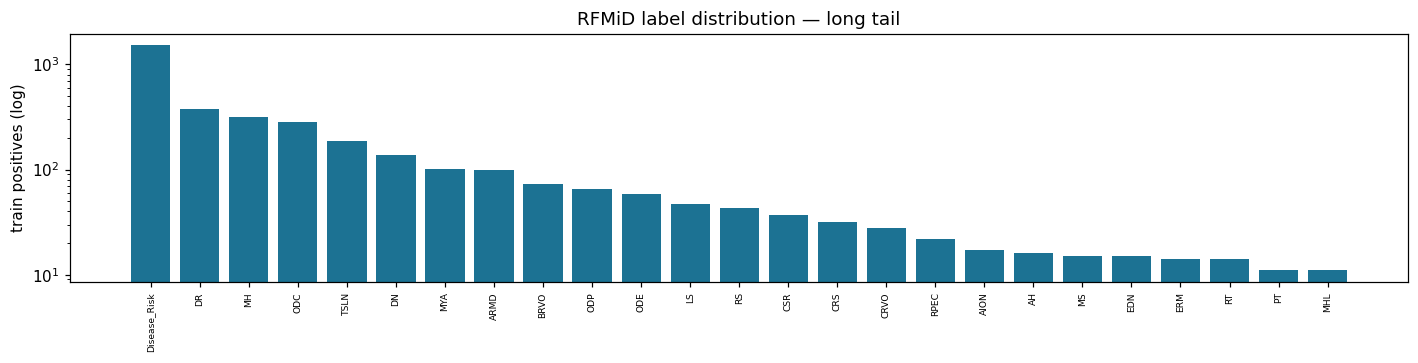

,label,train_pos,val_pos,test_pos,train_prev_%
0,Disease_Risk,1519,506,506,79.11
1,DR,376,132,124,19.58
2,MH,317,102,104,16.51
3,ODC,282,72,91,14.69
4,TSLN,186,65,53,9.69
5,DN,138,46,46,7.19
6,MYA,101,34,32,5.26
7,ARMD,100,38,31,5.21
8,BRVO,73,23,23,3.80
9,ODP,65,26,24,3.39


In [35]:
train_pos = Y["train"].sum(0)
order = np.argsort(-train_pos)

freq_df = pd.DataFrame({
    "label": [LABEL_COLS[i] for i in order],
    "train_pos": train_pos[order].astype(int),
    "val_pos":   Y["val"].sum(0)[order].astype(int),
    "test_pos":  Y["test"].sum(0)[order].astype(int),
})
freq_df["train_prev_%"] = (freq_df["train_pos"] / len(Y["train"]) * 100).round(2)

n_train = len(Y["train"])
head = int((train_pos >= 0.05 * n_train).sum())
tail = int((train_pos <= 0.01 * n_train).sum())
nonzero = train_pos[train_pos > 0]
print(f"imbalance ratio (max:min non-zero) = {nonzero.max() / nonzero.min():.0f} : 1")
print(f"head classes (>=5% prevalence): {head}   tail classes (<=1%): {tail}")
print(f"classes with zero training positives: {(train_pos == 0).sum()}")

fig, ax = plt.subplots(figsize=(13, 3.4))
ax.bar(range(NUM_CLASSES), freq_df["train_pos"], color="#1C7293")
ax.set_yscale("log")
ax.set_xticks(range(NUM_CLASSES))
ax.set_xticklabels(freq_df["label"], rotation=90, fontsize=6)
ax.set_ylabel("train positives (log)")
ax.set_title("RFMiD label distribution — long tail")
plt.tight_layout(); plt.savefig(CFG.WORK_DIR / "figs/label_distribution.png"); plt.show()

freq_df.head(12)

---
## 3b. Evaluation protocol — K-fold CV on train+val (v8 change 1)

**Problem.** v7 compared recipes on one validation split and 640 test images; most tail classes have ~4–5 test positives, and
the headline vessel gain (+0.012 mAP) was smaller than the seed-to-seed spread. Differences of that size could not be told apart from noise.

**Protocol.**
- Pool train + val → **2,560 images**; keep the 640-image test split strictly held out.
- **5-fold multilabel-stratified CV** (`make_folds`): every class is spread within ±1 positive across folds (asserted below).
- For each fold: train on 4/5, select the best epoch on the held-out fifth, predict it (→ **out-of-fold, OOF**) and the test split.
- **OOF metrics** use all 2,560 images, each predicted by a model that never saw it: ~4× more positives per tail class than v7's test split.
- **Paired bootstrap** (`paired_bootstrap`): resample OOF images, recompute mAP of both recipes on the *same* resample, report Δ with a 95% CI. A recipe is called better/worse only if the CI excludes 0.
- Calibration, F1 thresholds and the ensemble of the five fold-models are described in §13.

In [36]:
def make_folds(y, k, seed):
    '''Multilabel-stratified K-fold (a compact iterative stratification, Sechidis et al. 2011):
    visit samples rarest-label-first and give each to the fold that still "needs" most of that
    label, breaking ties by the sample's other labels, then by fold size. Label-free images
    just balance fold sizes. Deterministic given `seed`.'''
    rng = np.random.default_rng(seed)
    n, c = y.shape
    lab_tot = y.sum(0)
    need = np.tile(lab_tot / k, (k, 1))             # labels each fold still wants, (k, c)
    size_need = np.full(k, n / k)
    fsize = np.zeros(k)
    fold = np.full(n, -1, dtype=int)
    pos = [np.flatnonzero(row > 0) for row in y]
    rarest = np.array([lab_tot[p].min() if len(p) else np.inf for p in pos])
    order = rng.permutation(n)
    order = order[np.argsort(rarest[order], kind="stable")]
    for i in order:
        p = pos[i]
        if len(p) == 0:
            s = size_need - fsize
            cand = np.flatnonzero(s >= s.max() - 1e-9)
        else:
            r = p[np.argmin(lab_tot[p])]
            cand = np.flatnonzero(need[:, r] >= need[:, r].max() - 1e-9)
            if len(cand) > 1:
                s = need[cand][:, p].sum(1)
                cand = cand[s >= s.max() - 1e-9]
            if len(cand) > 1:
                s = (size_need - fsize)[cand]
                cand = cand[s >= s.max() - 1e-9]
        f = int(rng.choice(cand))
        fold[i] = f; fsize[f] += 1; need[f, p] -= 1
    return fold


FOLD_ID = make_folds(Y["pool"], CFG.N_FOLDS, CFG.CV_SEED)
FOLDS = [(np.flatnonzero(FOLD_ID != k), np.flatnonzero(FOLD_ID == k)) for k in range(CFG.N_FOLDS)]
ACTIVE_FOLDS = [0] if CFG.SMOKE_TEST else list(range(CFG.N_FOLDS))
pd.DataFrame({"ID": DF["pool"]["ID"], "orig_split": DF["pool"]["orig_split"], "fold": FOLD_ID}
             ).to_csv(CFG.WORK_DIR / "results/folds.csv", index=False)

# ---- verify the stratification: every class should be spread ~evenly ---------------
_pos = np.stack([Y["pool"][FOLD_ID == k].sum(0) for k in range(CFG.N_FOLDS)])        # (K, C)
_tab = pd.DataFrame(_pos.astype(int), columns=LABEL_COLS,
                    index=[f"fold{k}" for k in range(CFG.N_FOLDS)]).T
_tab["total"] = _tab.sum(1)
_tab["max-min"] = _tab.iloc[:, :CFG.N_FOLDS].max(1) - _tab.iloc[:, :CFG.N_FOLDS].min(1)
print("fold sizes:", [int((FOLD_ID == k).sum()) for k in range(CFG.N_FOLDS)])
print(f"largest per-class spread across folds (max-min positives): {int(_tab['max-min'].max())}")
assert _tab["max-min"].max() <= 2, "stratification is uneven - a class is concentrated in some folds"
assert all(_pos[:, c].min() >= 1 for c in range(NUM_CLASSES)), "a class is missing from a fold"
print(f"OK: every one of the {NUM_CLASSES} classes appears in every fold")
display(_tab.sort_values("total").head(10))

fold sizes: [512, 512, 512, 512, 512]
largest per-class spread across folds (max-min positives): 1
OK: every one of the 25 classes appears in every fold


,fold0,fold1,fold2,fold3,fold4,total,max-min
PT,2,3,2,3,3,13,1
MHL,3,3,3,3,2,14,1
AH,4,4,4,4,4,20,0
MS,4,4,4,4,4,20,0
RT,4,4,4,4,4,20,0
EDN,4,4,4,4,4,20,0
ERM,5,4,4,4,4,21,1
AION,4,4,5,4,5,22,1
RPEC,6,6,5,5,6,28,1
CRVO,7,7,7,8,7,36,1


---
## 4. Module 1 — Preprocessing

`preprocess_pair` decodes and FOV-crops once, then returns two aligned views:

- **classifier** — CLAHE on LAB luminance, 256×256 RGB. Contrast without hue shift; colour
  matters for haemorrhage and exudate classes (ref [14]).
- **segmenter** — plain grayscale at 512×512, matching DRIVE training exactly.

Both derive from the same crop, so the vessel map stays pixel-aligned with the features it
modulates. The FOV crop matters on its own: ~30% of raw pixels are background, so cropping
first means the retina fills the frame instead of ~70% of it.

In [37]:
import threading
_tls = threading.local()

def _get_clahe():
    # cv2 CLAHE objects are not thread-safe; the cache builder decodes in a pool.
    if not hasattr(_tls, "clahe"):
        _tls.clahe = cv2.createCLAHE(clipLimit=CFG.CLAHE_CLIP,
                                     tileGridSize=(CFG.CLAHE_GRID, CFG.CLAHE_GRID))
    return _tls.clahe

def circular_fov_crop(img, thresh=CFG.FOV_THRESH):
    '''Crop to the bounding box of the illuminated retinal disc.'''
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    mask = gray > thresh
    if mask.sum() < 0.05 * mask.size:      # degenerate / very dark image: leave it alone
        return img
    rows, cols = np.where(mask)
    y0, y1 = rows.min(), rows.max() + 1
    x0, x1 = cols.min(), cols.max() + 1
    if (y1 - y0) < 32 or (x1 - x0) < 32:
        return img
    return img[y0:y1, x0:x1]

def apply_clahe(img):
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    lab[:, :, 0] = _get_clahe().apply(lab[:, :, 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def preprocess_pair(path):
    '''One decode + one FOV crop -> two aligned views.  [Stage 0]

    cls : uint8 RGB (CACHE_SIZE, CACHE_SIZE, 3), CLAHE-enhanced -> classifier
    seg : uint8 gray (VESSEL_INFER_SIZE, VESSEL_INFER_SIZE)     -> segmenter

    Both come from the same crop, so the vessel map stays pixel-aligned with the
    features it modulates. The segmenter view is plain grayscale/255 because that
    is exactly what HRM_UNet_DRIVE.ipynb trained on (load_gray_image -> /255.0).
    '''
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise IOError(f"unreadable image: {path}")
    img = circular_fov_crop(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

    cls = cv2.resize(apply_clahe(img), (CFG.CACHE_SIZE, CFG.CACHE_SIZE),
                     interpolation=cv2.INTER_AREA)

    src = apply_clahe(img) if CFG.VESSEL_USE_CLAHE else img
    seg = cv2.resize(src, (CFG.VESSEL_INFER_SIZE, CFG.VESSEL_INFER_SIZE),
                     interpolation=cv2.INTER_AREA)
    seg = cv2.cvtColor(seg, cv2.COLOR_RGB2GRAY)
    return cls, seg

def preprocess(path, size=CFG.CACHE_SIZE):
    '''Classifier view only.'''
    return preprocess_pair(path)[0]

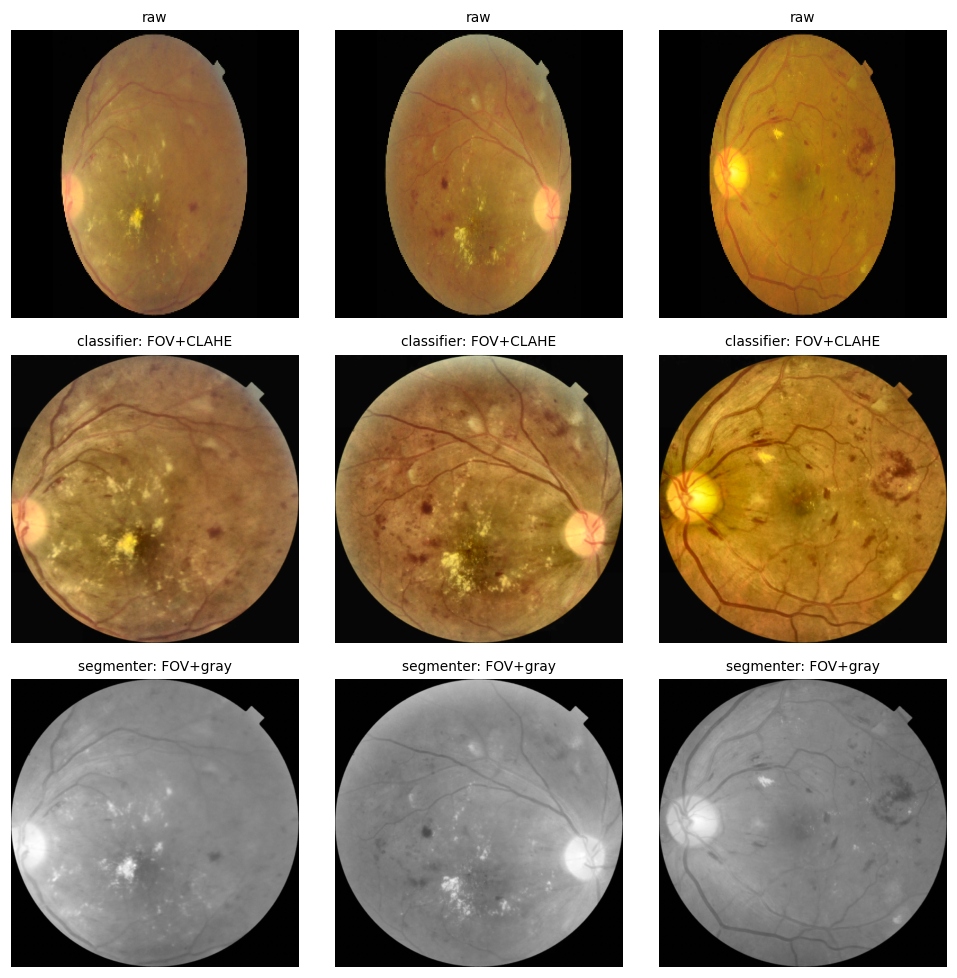

In [38]:
# visual sanity check
sample = DF["train"]["path"].iloc[:3]
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for j, p in enumerate(sample):
    raw = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    cls, seg = preprocess_pair(p)
    axes[0, j].imshow(cv2.resize(raw, (256, 256))); axes[0, j].set_title("raw", fontsize=9)
    axes[1, j].imshow(cls);                         axes[1, j].set_title("classifier: FOV+CLAHE", fontsize=9)
    axes[2, j].imshow(seg, cmap="gray");            axes[2, j].set_title("segmenter: FOV+gray", fontsize=9)
    for r in range(3): axes[r, j].axis("off")
plt.tight_layout(); plt.show()

---
## 5. Module 2 — Frozen vessel prior

`hrm_unet_drive.pth` is an **HRM-UNet**: patch embed → 4 VSS (Mamba SS2D) stages with Haar
wavelet downsampling, residual-path skips, patch-expand decoder. The classes below are
verbatim from `HRM_UNet_DRIVE.ipynb`; hyperparameters are read back out of the checkpoint,
and loading is `strict` — a mismatch raises rather than silently leaving layers random.

Three settings are inherited from how it was trained, not chosen here:

| | Training | Therefore |
|:--|:--|:--|
| Input | `load_gray_image` → `/255.0` | grayscale, `[0,1]`, **no** mean/std |
| Enhancement | none | `VESSEL_USE_CLAHE = False` |
| Geometry | 64×64 patches, sliding window stride 32 | tiled inference, not full-image |

In [39]:
ckpt_raw = torch.load(CFG.VESSEL_CKPT, map_location="cpu", weights_only=False)

def extract_state_dict(obj):
    if isinstance(obj, nn.Module):
        return obj.state_dict(), obj
    if isinstance(obj, dict):
        for k in ("state_dict", "model_state_dict", "model", "net", "weights"):
            if k in obj and isinstance(obj[k], dict):
                return obj[k], None
        if all(isinstance(v, torch.Tensor) for v in obj.values()):
            return obj, None
    raise TypeError(f"Unrecognised checkpoint format: {type(obj)}")

sd_raw, maybe_module = extract_state_dict(ckpt_raw)
sd = { (k[7:] if k.startswith("module.") else k): v for k, v in sd_raw.items() }

print(f"{len(sd)} tensors, {sum(v.numel() for v in sd.values())/1e6:.2f} M params\n")
print("first 12 keys:")
for k in list(sd)[:12]:
    print(f"  {k:52s} {tuple(sd[k].shape)}")
print("\nlast 6 keys:")
for k in list(sd)[-6:]:
    print(f"  {k:52s} {tuple(sd[k].shape)}")

first_conv = next((v for v in sd.values() if v.ndim == 4), None)
last_conv  = next((v for k, v in reversed(list(sd.items())) if v.ndim == 4), None)
if first_conv is not None:
    print(f"\ninferred in_channels  = {first_conv.shape[1]}  "
          f"(first conv {tuple(first_conv.shape)})")
if last_conv is not None:
    print(f"inferred out_channels = {last_conv.shape[0]}  "
          f"(last conv {tuple(last_conv.shape)})")

444 tensors, 3.71 M params

first 12 keys:
  patch_embed.weight                                   (24, 1, 4, 4)
  patch_embed.bias                                     (24,)
  enc_stages.0.blocks.0.norm1.weight                   (24,)
  enc_stages.0.blocks.0.norm1.bias                     (24,)
  enc_stages.0.blocks.0.ss2d.in_proj.weight            (96, 24)
  enc_stages.0.blocks.0.ss2d.in_proj.bias              (96,)
  enc_stages.0.blocks.0.ss2d.dwconv.weight             (48, 1, 3, 3)
  enc_stages.0.blocks.0.ss2d.dwconv.bias               (48,)
  enc_stages.0.blocks.0.ss2d.core.A_log                (48, 8)
  enc_stages.0.blocks.0.ss2d.core.D                    (48,)
  enc_stages.0.blocks.0.ss2d.core.x_proj.weight        (17, 48)
  enc_stages.0.blocks.0.ss2d.core.dt_proj.weight       (48, 1)

last 6 keys:
  dec_up.2.norm.weight                                 (24,)
  dec_up.2.norm.bias                                   (24,)
  final_expand.weight                                  (24, 24,

### HRM-UNet architecture

In [40]:
# ===================== HRM-UNet (from HRM_UNet_DRIVE.ipynb) ==================
# Verbatim from the training notebook. Do not "improve" these: the weights in
# hrm_unet_drive.pth were fitted to exactly this computation.

class HaarWaveletDownsampling(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        ll = torch.tensor([[1., 1.], [1., 1.]]) / 2
        lh = torch.tensor([[1., 1.], [-1., -1.]]) / 2
        hl = torch.tensor([[1., -1.], [1., -1.]]) / 2
        hh = torch.tensor([[1., -1.], [-1., 1.]]) / 2
        filters = torch.stack([ll, lh, hl, hh], dim=0).unsqueeze(1)
        self.register_buffer("weight", filters.repeat(in_ch, 1, 1, 1))
        self.proj = nn.Sequential(
            nn.Conv2d(in_ch * 4, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))

    def forward(self, x):
        B, C, H, W = x.shape
        return self.proj(F.conv2d(x, self.weight, stride=2, groups=C))


class ResBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv3 = nn.Conv2d(ch, ch, 3, padding=1)
        self.bn = nn.BatchNorm2d(ch)
        self.conv1 = nn.Conv2d(ch, ch, 1)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        res = self.conv1(x)
        out = self.relu(self.bn(self.conv3(x)))
        return self.relu(out + res)


class ResPath(nn.Module):
    def __init__(self, ch, n_blocks):
        super().__init__()
        self.blocks = nn.Sequential(*[ResBlock(ch) for _ in range(max(n_blocks, 1))])

    def forward(self, x):
        return self.blocks(x)


class SimpleSSMCore(nn.Module):
    '''Pure-PyTorch S6 selective scan. The loop over L is sequential, which is
    why inference is tiled into 64x64 patches rather than run full-image.'''
    def __init__(self, d_inner, d_state=16):
        super().__init__()
        self.d_inner, self.d_state = d_inner, d_state
        self.x_proj = nn.Linear(d_inner, d_state * 2 + 1, bias=False)
        self.dt_proj = nn.Linear(1, d_inner)
        A = torch.arange(1, d_state + 1, dtype=torch.float32).repeat(d_inner, 1)
        self.A_log = nn.Parameter(torch.log(A))
        self.D = nn.Parameter(torch.ones(d_inner))

    def forward(self, x):                      # (B, L, d_inner)
        B, L, d = x.shape
        A = -torch.exp(self.A_log)
        delta, Bm, Cm = torch.split(self.x_proj(x), [1, self.d_state, self.d_state], dim=-1)
        delta = F.softplus(self.dt_proj(delta))
        deltaA = torch.exp(delta.unsqueeze(-1) * A)
        deltaB_u = delta.unsqueeze(-1) * Bm.unsqueeze(2) * x.unsqueeze(-1)
        h = x.new_zeros(B, d, self.d_state)
        ys = []
        for t in range(L):
            h = deltaA[:, t] * h + deltaB_u[:, t]
            ys.append((h * Cm[:, t].unsqueeze(1)).sum(-1))
        return torch.stack(ys, dim=1) + x * self.D


class SS2D(nn.Module):
    def __init__(self, d_model, d_state=16, expand=2):
        super().__init__()
        d_inner = expand * d_model
        self.d_inner = d_inner
        self.in_proj = nn.Linear(d_model, 2 * d_inner)
        self.dwconv = nn.Conv2d(d_inner, d_inner, 3, padding=1, groups=d_inner)
        self.act = nn.SiLU()
        self.core = SimpleSSMCore(d_inner, d_state)
        self.out_norm = nn.LayerNorm(d_inner)
        self.out_proj = nn.Linear(d_inner, d_model)

    def forward(self, x):                      # (B,H,W,C)
        B, H, W, C = x.shape
        x_in, z = self.in_proj(x).chunk(2, dim=-1)
        x_in = self.act(self.dwconv(x_in.permute(0, 3, 1, 2))).permute(0, 2, 3, 1)

        seq_rm = x_in.reshape(B, H * W, self.d_inner)
        seq_rm_r = torch.flip(seq_rm, dims=[1])
        seq_cm = x_in.permute(0, 2, 1, 3).reshape(B, H * W, self.d_inner)
        seq_cm_r = torch.flip(seq_cm, dims=[1])

        y1 = self.core(seq_rm)
        y2 = torch.flip(self.core(seq_rm_r), dims=[1])
        y3 = self.core(seq_cm)
        y4 = torch.flip(self.core(seq_cm_r), dims=[1])

        y3 = y3.reshape(B, W, H, self.d_inner).permute(0, 2, 1, 3).reshape(B, H * W, self.d_inner)
        y4 = y4.reshape(B, W, H, self.d_inner).permute(0, 2, 1, 3).reshape(B, H * W, self.d_inner)

        y = ((y1 + y2 + y3 + y4) / 4).reshape(B, H, W, self.d_inner)
        return self.out_proj(self.out_norm(y) * self.act(z))


class VSSBlock(nn.Module):
    def __init__(self, dim, d_state=16, expand=2):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.ss2d = SS2D(dim, d_state=d_state, expand=expand)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, dim * 2), nn.GELU(), nn.Linear(dim * 2, dim))

    def forward(self, x):
        x = x + self.ss2d(self.norm1(x))
        return x + self.mlp(self.norm2(x))


class VSSStage(nn.Module):
    def __init__(self, dim, depth, d_state=16):
        super().__init__()
        self.blocks = nn.ModuleList([VSSBlock(dim, d_state) for _ in range(depth)])

    def forward(self, x):
        for blk in self.blocks:
            x = blk(x)
        return x


class PatchExpand(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.expand = nn.Linear(dim, 2 * dim, bias=False)
        self.out_dim = dim // 2
        self.norm = nn.LayerNorm(self.out_dim)

    def forward(self, x):
        B, H, W, C = x.shape
        x = self.expand(x).view(B, H, W, 2, 2, C // 2)
        x = x.permute(0, 1, 3, 2, 4, 5).reshape(B, H * 2, W * 2, C // 2)
        return self.norm(x)


class HRMUNet(nn.Module):
    def __init__(self, in_ch=1, num_classes=1, C=24, patch_size=4,
                 depths_enc=(2, 2, 2, 2), depths_dec=(2, 2, 2, 1),
                 res_path_blocks=(4, 3, 2, 1), d_state=16):
        super().__init__()
        self.patch_embed = nn.Conv2d(in_ch, C, kernel_size=patch_size, stride=patch_size)
        dims = [C, C * 2, C * 4, C * 8]
        self.enc_stages = nn.ModuleList([VSSStage(dims[i], depths_enc[i], d_state) for i in range(4)])
        self.enc_down = nn.ModuleList([HaarWaveletDownsampling(dims[i], dims[i + 1]) for i in range(3)])
        self.res_paths = nn.ModuleList([ResPath(dims[i], res_path_blocks[i]) for i in range(4)])
        dec_dims = [dims[3], dims[2], dims[1], dims[0]]
        self.dec_stages = nn.ModuleList([VSSStage(dec_dims[i], depths_dec[i], d_state) for i in range(4)])
        self.dec_up = nn.ModuleList([PatchExpand(dec_dims[i]) for i in range(3)])
        self.final_expand = nn.ConvTranspose2d(C, C, kernel_size=patch_size, stride=patch_size)
        self.final_proj = nn.Conv2d(C, num_classes, kernel_size=1)

    def forward(self, x):
        x = self.patch_embed(x).permute(0, 2, 3, 1)
        skips = []
        for i in range(4):
            x = self.enc_stages[i](x)
            skips.append(x)
            if i < 3:
                x = self.enc_down[i](x.permute(0, 3, 1, 2)).permute(0, 2, 3, 1)
        rs = [self.res_paths[i](skips[i].permute(0, 3, 1, 2)).permute(0, 2, 3, 1) for i in range(4)]
        d = self.dec_stages[0](skips[3] + rs[3])
        d = self.dec_stages[1](self.dec_up[0](d) + rs[2])
        d = self.dec_stages[2](self.dec_up[1](d) + rs[1])
        d = self.dec_stages[3](self.dec_up[2](d) + rs[0])
        return self.final_proj(self.final_expand(d.permute(0, 3, 1, 2)))


# ---- build the instance from the checkpoint's own shapes -------------------
_pe = sd["patch_embed.weight"]                                  # (C, in_ch, p, p)
_hp = dict(
    in_ch       = int(_pe.shape[1]),
    C           = int(_pe.shape[0]),
    patch_size  = int(_pe.shape[-1]),
    d_state     = int(sd["enc_stages.0.blocks.0.ss2d.core.A_log"].shape[1]),
    num_classes = int(sd["final_proj.weight"].shape[0]),
)
def _depths(prefix):
    return tuple(1 + max(int(k.split(".")[3]) for k in sd if k.startswith(f"{prefix}.{s}.blocks."))
                 for s in range(4))
_hp["depths_enc"] = _depths("enc_stages")
_hp["depths_dec"] = _depths("dec_stages")
_hp["res_path_blocks"] = tuple(
    1 + max(int(k.split(".")[3]) for k in sd if k.startswith(f"res_paths.{s}.blocks."))
    for s in range(4))

print("HRM-UNet hyperparameters recovered from the checkpoint:")
for k, v in _hp.items():
    print(f"  {k:16s} = {v}")

CUSTOM_VESSEL_MODEL = HRMUNet(**_hp)

HRM-UNet hyperparameters recovered from the checkpoint:
  in_ch            = 1
  C                = 24
  patch_size       = 4
  d_state          = 8
  num_classes      = 1
  depths_enc       = (2, 2, 2, 2)
  depths_dec       = (2, 2, 2, 1)
  res_path_blocks  = (4, 3, 2, 1)


In [41]:
def build_vessel_model(sd, model):
    '''Frozen, eval-mode segmenter whose weights exactly match the checkpoint.'''
    missing, unexpected = model.load_state_dict(sd, strict=False)
    if missing or unexpected:
        print("\n*** STATE DICT MISMATCH ***")
        print(f"missing    ({len(missing)}):", missing[:10])
        print(f"unexpected ({len(unexpected)}):", unexpected[:10])
        raise RuntimeError(
            "Checkpoint does not match the model class. strict=False would leave "
            "layers randomly initialised, so refusing to continue.")
    print("state_dict loaded strictly - all keys matched")

    model.eval().to(DEVICE)
    for p in model.parameters():
        p.requires_grad_(False)            # FROZEN: never fine-tuned on disease labels
    print(f"vessel segmenter: {sum(p.numel() for p in model.parameters())/1e6:.2f} M "
          f"frozen parameters")
    return model


VESSEL_MODEL = None
if CFG.PRECOMPUTED_VESSEL_DIR is None and CFG.REUSE_VESSEL_DIR is None:
    VESSEL_MODEL = build_vessel_model(sd, CUSTOM_VESSEL_MODEL)
else:
    print('vessel segmenter not loaded: reusing precomputed / v7 vessel maps')

state_dict loaded strictly - all keys matched
vessel segmenter: 3.71 M frozen parameters


### Tiled inference

`SimpleSSMCore` scans sequentially in a Python loop, so cost scales with sequence length:
**4,416 steps** per forward on a 64×64 patch versus **282,624** on a 512×512 image. Tiling
is therefore both the faithful choice (it matches training) and the fast one.

Batch size doesn't change the step count, so `VESSEL_PATCH_BATCH` is the lever — all patches
from several images go through in one call.

Inference runs at 512 so vessel width in pixels stays close to DRIVE's ~565px images; the
probability map is then downsampled to 256 for the cache.

In [42]:
@torch.no_grad()
def segment_vessels(gray_u8, out_size=CFG.VESSEL_CACHE_SIZE):
    '''Sliding-window vessel segmentation -> (B, out_size, out_size) uint8.

    Mirrors sliding_window_predict() from the training notebook: 64x64 patches at
    stride 32, sigmoid, averaged over the overlap. unfold/fold does the whole
    batch of images at once instead of looping.

    Two reasons not to feed the model a full 512x512 image:
      * it was trained on 64x64 patches, so full-image input is a domain shift;
      * SimpleSSMCore scans sequentially in Python, so cost grows with sequence
        length - 4,416 steps per forward at 64px vs 282,624 at 512px.
    Batch size does not change the step count, so large VESSEL_PATCH_BATCH is the
    lever that makes this fast.
    '''
    P, S = CFG.VESSEL_PATCH, CFG.VESSEL_STRIDE
    x = torch.from_numpy(gray_u8).to(DEVICE).float().div_(255).unsqueeze(1)
    B, _, H, W = x.shape                      # plain [0,1] gray: matches training

    ph, pw = (-(H - P)) % S, (-(W - P)) % S
    if ph or pw:
        x = F.pad(x, (0, pw, 0, ph), mode="reflect")
    Hp, Wp = x.shape[-2:]

    patches = F.unfold(x, kernel_size=P, stride=S)          # (B, P*P, L)
    L = patches.shape[-1]
    patches = patches.permute(0, 2, 1).reshape(B * L, 1, P, P)

    outs = []
    for k in range(0, patches.shape[0], CFG.VESSEL_PATCH_BATCH):
        logits = VESSEL_MODEL(patches[k:k + CFG.VESSEL_PATCH_BATCH])
        outs.append(torch.sigmoid(logits.float()))
    probs = torch.cat(outs).reshape(B, L, P * P).permute(0, 2, 1)

    num = F.fold(probs, (Hp, Wp), kernel_size=P, stride=S)
    den = F.fold(torch.ones_like(probs), (Hp, Wp), kernel_size=P, stride=S)
    prob = (num / den.clamp_min(1e-6))[:, :, :H, :W]        # average the overlap

    prob = F.interpolate(prob, size=(out_size, out_size),
                         mode="bilinear", align_corners=False)
    return (prob.clamp(0, 1) * 255).round().to(torch.uint8).squeeze(1).cpu().numpy()

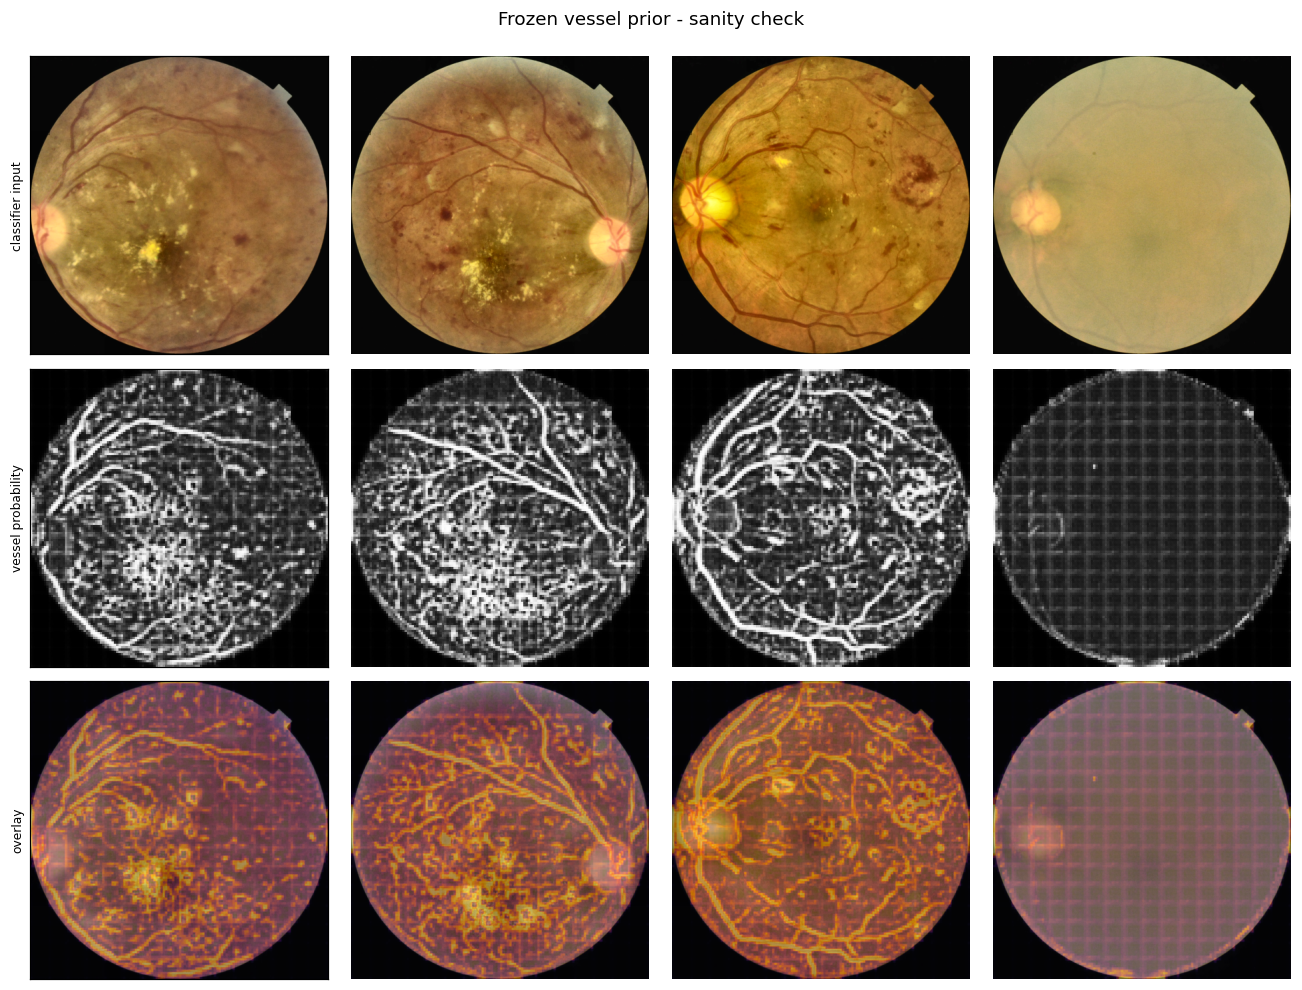

mean vessel prob: 0.270   frac(p>0.5): 0.176
1.6s for 4 images  ->  ~22 min for all 3200
Expect a thin branching tree over roughly 8-15% of the disc. If it looks like noise, stop here - do not build the cache.


In [43]:
# ---- verify before caching: does it attend to real vasculature? (ref [5]) ----
if VESSEL_MODEL is not None:
    t0 = time.time()
    pairs = [preprocess_pair(p) for p in DF["train"]["path"].iloc[:4]]
    cls_b = np.stack([c for c, _ in pairs])
    seg_b = np.stack([s for _, s in pairs])
    vmaps = segment_vessels(seg_b)
    dt = time.time() - t0

    fig, axes = plt.subplots(3, 4, figsize=(12, 9))
    for j in range(4):
        axes[0, j].imshow(cls_b[j])
        axes[1, j].imshow(vmaps[j], cmap="gray")
        axes[2, j].imshow(cls_b[j]); axes[2, j].imshow(cv2.resize(vmaps[j], cls_b[j].shape[1::-1]), cmap="inferno", alpha=0.45)
        for r in range(3): axes[r, j].axis("off")
    for r, t in enumerate(["classifier input", "vessel probability", "overlay"]):
        axes[r, 0].axis("on"); axes[r, 0].set_ylabel(t, fontsize=8)
        axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
    plt.suptitle("Frozen vessel prior - sanity check", y=0.995)
    plt.tight_layout(); plt.savefig(CFG.WORK_DIR / "figs/vessel_check.png"); plt.show()

    print("mean vessel prob: %.3f   frac(p>0.5): %.3f"
          % (vmaps.mean() / 255, (vmaps > 127).mean()))
    n_all = len(DF["train"]) + len(DF["val"]) + len(DF["test"])
    print(f"{dt:.1f}s for 4 images  ->  ~{dt / 4 * n_all / 60:.0f} min for all {n_all}")
    print("Expect a thin branching tree over roughly 8-15% of the disc. If it looks "
          "like noise, stop here - do not build the cache.")

---
## 6. One-time cache build

| Array | Shape | Size |
|:--|:--|:--|
| pool images | `(2560, 448, 448, 3)` uint8 | ~1.5 GB |
| pool vessels | `(2560, 256, 256)` uint8 | ~170 MB |
| test images / vessels | `(640, …)` | ~0.4 GB |

**v8:** images are cached once at **448 px** so the resolution sweep (224 / 320 / 384) needs no rebuild. Vessel maps
stay at **256 px** — they are smooth probability maps that the gates average-pool to ≤48×48 anyway — and are resized on
the GPU. If you kept v7's `*_ves_256.npy`, set `CFG.REUSE_VESSEL_DIR` and the 19-minute segmentation pass is skipped
(shapes are checked; images still have to be decoded once, ~5–10 min).

The segmenter is frozen, so caching is exactly equivalent to recomputing every epoch. Idempotent and resumable.

In [44]:
from concurrent.futures import ThreadPoolExecutor

def _reuse_vessels(split):
    '''v7's vessel maps (n, VESSEL_CACHE_SIZE, VESSEL_CACHE_SIZE) uint8 aligned to DF[split],
    or None. The pool is train followed by val, exactly the order DF["pool"] was built in.'''
    if CFG.REUSE_VESSEL_DIR is None:
        return None
    root, VS = Path(CFG.REUSE_VESSEL_DIR), CFG.VESSEL_CACHE_SIZE
    def _one(s):
        hits = sorted(root.rglob(f"{s}_ves_{VS}.npy"))
        if not hits:
            raise FileNotFoundError(f"REUSE_VESSEL_DIR={root}: no {s}_ves_{VS}.npy found")
        a = np.load(hits[0], mmap_mode="r")
        if a.shape[0] != len(DF[s]) or a.shape[1:] != (VS, VS):
            raise ValueError(f"{hits[0]} has shape {a.shape}, expected ({len(DF[s])}, {VS}, {VS}) - "
                             "was it built from a different RFMiD folder or cache size?")
        return a
    if split == "pool":
        return np.concatenate([np.asarray(_one("train")), np.asarray(_one("val"))], 0)
    return np.asarray(_one(split))


def build_cache(split, force=False):
    cdir  = CFG.WORK_DIR / "cache"
    S, VS = CFG.CACHE_SIZE, CFG.VESSEL_CACHE_SIZE
    img_p = cdir / f"{split}_img_{S}.npy"
    ves_p = cdir / f"{split}_ves_{VS}.npy"
    meta_p = cdir / f"{split}_meta_{S}_{VS}.json"
    n = len(DF[split])
    reuse = _reuse_vessels(split)
    src = ("precomputed" if CFG.PRECOMPUTED_VESSEL_DIR is not None
           else "reuse" if reuse is not None else "model")

    # ---- decide where to start ---------------------------------------------
    start = 0
    if force:
        for p in (img_p, ves_p, meta_p):
            p.unlink(missing_ok=True)
    elif img_p.exists() and ves_p.exists() and meta_p.exists():
        meta = json.loads(meta_p.read_text())
        ok = (meta.get("n") == n and meta.get("cache_size") == S
              and meta.get("vessel_cache_size") == VS
              and meta.get("vessel_source") == src
              and np.load(img_p, mmap_mode="r").shape[0] == n)
        if ok:
            start = int(meta.get("done", 0))
            if start >= n:
                print(f"[{split}] cache complete ({n} imgs) - skipping")
                return img_p, ves_p
            print(f"[{split}] resuming at {start}/{n} ({start/n:.0%} done)")
        else:
            print(f"[{split}] cache metadata mismatch - rebuilding from scratch")
            for p in (img_p, ves_p, meta_p):
                p.unlink(missing_ok=True)

    # 'r+' preserves finished rows; 'w+' would truncate the file to zeros
    mode = "r+" if start > 0 else "w+"
    imgs = np.lib.format.open_memmap(img_p, mode=mode, dtype=np.uint8, shape=(n, S, S, 3))
    vess = np.lib.format.open_memmap(ves_p, mode=mode, dtype=np.uint8, shape=(n, VS, VS))

    paths = DF[split]["path"].tolist()
    ids   = DF[split]["ID"].tolist()
    CH = 8            # images per chunk; segment_vessels batches their patches

    def save_progress(done):
        meta_p.write_text(json.dumps(
            {"n": n, "done": int(done), "cache_size": S, "vessel_cache_size": VS,
             "vessel_source": src}))

    try:
        with ThreadPoolExecutor(max_workers=4) as pool:
            bar = tqdm(range(start, n, CH), desc=f"cache[{split}]",
                       initial=start // CH, total=(n + CH - 1) // CH)
            for s in bar:
                e = min(s + CH, n)
                pairs = list(pool.map(preprocess_pair, paths[s:e]))
                imgs[s:e] = np.stack([c for c, _ in pairs])

                if CFG.PRECOMPUTED_VESSEL_DIR is not None:
                    vd = Path(CFG.PRECOMPUTED_VESSEL_DIR)
                    vb = []
                    for i in ids[s:e]:
                        m = cv2.imread(str(vd / f"{i}.png"), cv2.IMREAD_GRAYSCALE)
                        if m is None:
                            raise FileNotFoundError(f"missing vessel mask: {vd / f'{i}.png'}")
                        vb.append(cv2.resize(m, (VS, VS), interpolation=cv2.INTER_AREA))
                    vess[s:e] = np.stack(vb)
                elif reuse is not None:
                    vess[s:e] = reuse[s:e]
                else:
                    vess[s:e] = segment_vessels(np.stack([g for _, g in pairs]), out_size=VS)

                # commit this chunk before advancing the marker, so 'done' can
                # never point past data that actually reached disk
                imgs.flush(); vess.flush()
                save_progress(e)
    finally:
        imgs.flush(); vess.flush()
        del imgs, vess; gc.collect()

    print(f"[{split}] wrote {img_p.name} + {ves_p.name}   (vessel source: {src})")
    return img_p, ves_p


t0 = time.time()
CACHE = {s: build_cache(s) for s in ("pool", "test")}
print(f"\ntotal cache time: {time.time() - t0:.0f}s")

if VESSEL_MODEL is not None:                # free VRAM; never needed again
    VESSEL_MODEL = VESSEL_MODEL.cpu()
    torch.cuda.empty_cache()

[pool] cache complete (2560 imgs) - skipping
[test] cache complete (640 imgs) - skipping

total cache time: 0s


In [45]:
def load_arrays(split):
    ip, vp = CACHE[split]
    mode = None if CFG.LOAD_CACHE_IN_RAM else "r"
    return np.load(ip, mmap_mode=mode), np.load(vp, mmap_mode=mode)

ARR = {s: load_arrays(s) for s in ("pool", "test")}
tot = sum(a.nbytes + b.nbytes for a, b in ARR.values()) / 1e9
print(f"cache resident: {tot:.2f} GB  (in RAM = {CFG.LOAD_CACHE_IN_RAM})")
for s, (a, b) in ARR.items():
    print(f"  {s:5s} images {a.shape}   vessels {b.shape}")

cache resident: 2.14 GB  (in RAM = True)
  pool  images (2560, 448, 448, 3)   vessels (2560, 256, 256)
  test  images (640, 448, 448, 3)   vessels (640, 256, 256)


---
## 7. Dataset and GPU augmentation

`RFMiDCached(split, indices)` is a view onto the cached arrays; it returns the **position inside the subset**, so
per-sample state (curriculum losses, vessel confidence) stays aligned for any fold.

One `affine_grid` + `grid_sample` applies per-sample rotation (±15°), zoom, shift and h-flip to image and vessel map
**stacked as one 4-channel tensor** — joint geometry is a correctness requirement, since fusion multiplies the vessel map
into features at matching positions. The two caches differ in size (448 vs 256), so both are first brought to a canvas of
`input_size × 256/224`: area-resize for the image (anti-aliased), bilinear for the vessel map.

**v8 augmentation additions** (`CFG.AUG_STRONG`; RGB only, the vessel map is never perturbed): per-channel gain ±6%,
saturation ±15%, mild blur on 20% of samples, sensor noise up to σ=0.02. Cutout / random erasing is deliberately **not**
used — it can erase the single lesion that defines a rare class. No vertical flip: fundus orientation is consistent.

In [46]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

# The network input size is a per-RECIPE property in v8 (resolution sweep), but predict(),
# Grad-CAM, etc. call gpu_augment(...) without it - so the active size lives here.
_CUR = {"size": CFG.INPUT_SIZE}
def set_input_size(s): _CUR["size"] = int(s)


class RFMiDCached(Dataset):
    '''A view onto the cached arrays. `indices` selects a subset (a CV fold); __getitem__ returns
    the POSITION within that subset, so per-sample state (curriculum losses, vessel confidence)
    is indexed 0..len(subset)-1 regardless of which images the subset holds.'''
    def __init__(self, split, indices=None):
        self.img, self.ves = ARR[split]
        y_all = Y[split]
        self.idx = np.arange(len(y_all)) if indices is None else np.asarray(indices, dtype=np.int64)
        self.y = y_all[self.idx]
    def __len__(self): return len(self.idx)
    def __getitem__(self, j):
        g = int(self.idx[j])
        return (torch.from_numpy(np.ascontiguousarray(self.img[g])),
                torch.from_numpy(np.ascontiguousarray(self.ves[g])),
                torch.from_numpy(self.y[j]), j)


def _affine_theta(B, train, device):
    if not train:
        th = torch.zeros(B, 2, 3, device=device)
        th[:, 0, 0] = 1.0; th[:, 1, 1] = 1.0
        return th
    ang   = (torch.rand(B, device=device) * 2 - 1) * (15 * math.pi / 180)
    scale = 1.0 + (torch.rand(B, device=device) * 2 - 1) * 0.15
    tx    = (torch.rand(B, device=device) * 2 - 1) * 0.05
    ty    = (torch.rand(B, device=device) * 2 - 1) * 0.05
    flip  = torch.where(torch.rand(B, device=device) < 0.5, -1.0, 1.0)
    cos, sin = torch.cos(ang) * scale, torch.sin(ang) * scale
    th = torch.zeros(B, 2, 3, device=device)
    th[:, 0, 0] =  cos * flip; th[:, 0, 1] = -sin; th[:, 0, 2] = tx
    th[:, 1, 0] =  sin * flip; th[:, 1, 1] =  cos; th[:, 1, 2] = ty
    return th


def gpu_augment(img_u8, ves_u8, train=True, size=None, strong=None):
    '''uint8 batches -> (normalised RGB (B,3,S,S), vessel (B,1,S,S)) float.

    v8: the image cache (448) and the vessel cache (256) differ in size, so both are first
    brought to a canvas of size*PRE_RATIO (area-resize for the image = anti-aliased, bilinear
    for the vessel map); one affine_grid/grid_sample then applies the SAME geometry to both,
    exactly as in v7. At size=224 the canvas is 256 - v7's cache size.'''
    size   = _CUR["size"] if size is None else int(size)
    strong = CFG.AUG_STRONG if strong is None else strong

    img = img_u8.to(DEVICE, non_blocking=True).permute(0, 3, 1, 2).float().div_(255)
    ves = ves_u8.to(DEVICE, non_blocking=True).unsqueeze(1).float().div_(255)

    pre = min(img.shape[-1], int(round(size * CFG.PRE_RATIO)))
    if img.shape[-1] != pre:
        img = F.interpolate(img, size=(pre, pre), mode="area")
    if ves.shape[-1] != pre:
        ves = F.interpolate(ves, size=(pre, pre), mode="bilinear", align_corners=False)
    x = torch.cat([img, ves], 1)                                   # joint geometry

    theta = _affine_theta(x.shape[0], train, DEVICE)
    grid  = F.affine_grid(theta, (x.shape[0], 4, size, size), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)

    img, ves = x[:, :3], x[:, 3:4]

    if train:                                                      # photometric: RGB only
        B = img.shape[0]
        if strong:
            # v8 - lesion-preserving regularisers (no cutout: it can erase the one lesion
            # that defines a rare class). The vessel map is never touched.
            img = img * (1.0 + (torch.rand(B, 3, 1, 1, device=DEVICE) * 2 - 1) * 0.06)   # per-channel gain
            gray = img.mean(1, keepdim=True)
            sat = 1.0 + (torch.rand(B, 1, 1, 1, device=DEVICE) * 2 - 1) * 0.15            # saturation
            img = gray + (img - gray) * sat
            blur = (torch.rand(B, 1, 1, 1, device=DEVICE) < 0.2).float()                  # mild blur, p=0.2
            img = blur * F.avg_pool2d(img, 3, 1, 1, count_include_pad=False) + (1 - blur) * img
            img = img + torch.randn_like(img) * (torch.rand(B, 1, 1, 1, device=DEVICE) * 0.02)  # sensor noise
        b = 1.0 + (torch.rand(B, 1, 1, 1, device=DEVICE) * 2 - 1) * 0.20   # brightness
        c = 1.0 + (torch.rand(B, 1, 1, 1, device=DEVICE) * 2 - 1) * 0.20   # contrast
        g = 1.0 + (torch.rand(B, 1, 1, 1, device=DEVICE) * 2 - 1) * 0.15   # gamma
        mean = img.mean(dim=(1, 2, 3), keepdim=True)
        img = ((img * b - mean) * c + mean).clamp_(1e-4, 1).pow(g)

    img = (img - IMAGENET_MEAN) / IMAGENET_STD
    return img.contiguous(memory_format=torch.channels_last), ves.clamp_(0, 1)

---
## 8. Modules 2–3 — Fusion and classifier

Injection points in DenseNet-121 at 224×224 input (feature maps scale with `input_size`):

| After | Channels | Spatial @224 | @384 |
|:--|:--|:--|:--|
| `transition1` | 128 | 28×28 | 48×48 |
| `transition2` | 256 | 14×14 | 24×24 |
| `transition3` | 512 | 7×7 | 12×12 |

Gate:

```
A     = sigmoid( MLP_1x1( avgpool(vessel_map) ) )
f_out = f * (1 + gamma * A)          # gamma learnable, init 0
```

- **`gamma` starts at 0**, so step 0 is exactly the pretrained backbone — fusion is learned as a departure from a known-good baseline.
- **The residual form lets the network down-weight vessels** (~half of RFMiD is non-vascular).

**v8 additions**
- **Layer-wise LR decay** (`param_groups`): the top stage trains at `lr_backbone`; each stage below at `layer_decay`× less. Biases / norm scales get no weight decay.
- **Dense-layer dropout** (`CFG.DENSE_DROP_RATE`) and head dropout 0.3.
- **`VGViT`** — RETFound (ViT-L/16, MAE-pretrained on colour fundus photographs, 224 px) with the *same* `VesselGate` applied to the 14×14 patch-token grid after blocks 8 / 16 / 24. Same interface as `VGDenseNet`, so training, calibration and evaluation code is shared. Gradient checkpointing keeps ViT-L inside a T4's memory.

In [47]:
import torchvision
from urllib.error import URLError

# Kaggle: no Google Drive, and /kaggle/input is read-only, so cache under
# /kaggle/working instead (persists for the life of this session/commit,
# unlike Colab's Drive it does NOT survive to a brand new session unless
# saved as a dataset - good enough to avoid re-downloading across cell
# re-runs within one run).
if Path("/kaggle/working").exists():
    _TORCH_HOME = Path("/kaggle/working") / "torch_cache"
else:
    _TORCH_HOME = CFG.WORK_DIR / "torch_cache"
_TORCH_HOME.mkdir(parents=True, exist_ok=True)
torch.hub.set_dir(str(_TORCH_HOME))
print(f"torch.hub cache dir: {_TORCH_HOME}")


def build_backbone(name="densenet121", pretrained=True, max_retries=5, retry_wait=10, drop_rate=0.0):
    '''Downloads (once) + retries on transient network failure. If every retry
    fails, raises a clear error explaining it is a network problem, not a code
    problem, rather than the raw urllib traceback.'''

    def _download_with_retries(load_fn):
        last_err = None
        for attempt in range(1, max_retries + 1):
            try:
                return load_fn()
            except (URLError, OSError) as e:      # covers socket.gaierror, ConnectionError, etc.
                last_err = e
                if attempt < max_retries:
                    print(f"[build_backbone] weight download attempt {attempt}/{max_retries} "
                          f"failed ({e.__class__.__name__}: {e}) - retrying in {retry_wait}s...")
                    time.sleep(retry_wait)
        raise RuntimeError(
            f"Could not download pretrained '{name}' weights after {max_retries} attempts - "
            "this is a network problem (DNS/outbound access from the runtime), not a bug in "
            "this notebook. On Kaggle, the #1 cause of 'Temporary failure in name resolution' "
            "is that Internet is switched OFF for this notebook: open the right-hand Settings "
            "panel -> Internet -> toggle On (you may need to verify your account by phone "
            "first), then Save and re-run this cell - no amount of retrying fixes a disabled "
            "network. If Internet is already on, it's a transient DNS blip - re-running this "
            "cell alone (without restarting the whole notebook) is usually enough. If outbound "
            "network is unavailable entirely, you can call build_backbone(..., "
            "pretrained=False) to train from random init as a code smoke test - but note this "
            "will substantially hurt every reported metric, so it is not a substitute for the "
            "real pretrained run."
        ) from last_err

    try:
        from torchvision.models import DenseNet121_Weights, ResNet50_Weights
        if name == "densenet121":
            w = DenseNet121_Weights.IMAGENET1K_V1 if pretrained else None
            build = lambda: torchvision.models.densenet121(weights=w, drop_rate=drop_rate)
        else:
            w = ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
            build = lambda: torchvision.models.resnet50(weights=w)
    except ImportError:                                   # older torchvision
        build = lambda: getattr(torchvision.models, name)(pretrained=pretrained)   # (drop_rate only wired for densenet121)

    if not pretrained:
        return build()                        # no network call at all - nothing to retry
    return _download_with_retries(build)


class VesselGate(nn.Module):
    '''1x1 conv + sigmoid on the vessel map, multiplied in with learnable gamma.'''
    def __init__(self, feat_ch, hidden=16):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Conv2d(1, hidden, 1, bias=False),
            nn.BatchNorm2d(hidden), nn.ReLU(inplace=True),
            nn.Conv2d(hidden, feat_ch, 1, bias=True))
        nn.init.zeros_(self.mlp[-1].bias)
        self.gamma = nn.Parameter(torch.zeros(1))     # identity at initialisation
        self.attn = None                              # cached for the curriculum

    def forward(self, f, v):
        v = F.adaptive_avg_pool2d(v, f.shape[-2:])
        a = torch.sigmoid(self.mlp(v.to(f.dtype)))
        if not self.training:
            self.attn = a.detach()
        return f * (1.0 + self.gamma * a)


class VGDenseNet(nn.Module):
    '''DenseNet-121 + multi-scale vessel attention + multi-label sigmoid head.'''
    STAGE_CH = {1: 128, 2: 256, 3: 512}

    def __init__(self, num_classes, use_vessel=True, pretrained=True,
                 dropout=CFG.HEAD_DROPOUT, stages=CFG.FUSION_STAGES, drop_rate=CFG.DENSE_DROP_RATE):
        super().__init__()
        f = build_backbone("densenet121", pretrained, drop_rate=drop_rate).features
        self.stem   = nn.Sequential(f.conv0, f.norm0, f.relu0, f.pool0)
        self.block1, self.trans1 = f.denseblock1, f.transition1
        self.block2, self.trans2 = f.denseblock2, f.transition2
        self.block3, self.trans3 = f.denseblock3, f.transition3
        self.block4, self.norm5  = f.denseblock4, f.norm5

        self.use_vessel = use_vessel
        self.stages = tuple(stages) if use_vessel else ()
        self.gates = nn.ModuleDict(
            {str(s): VesselGate(self.STAGE_CH[s]) for s in self.stages})

        self.dropout = nn.Dropout(dropout)            # the MC-dropout source
        self.classifier = nn.Linear(1024, num_classes)
        nn.init.zeros_(self.classifier.bias)

    def _gate(self, s, x, v):
        return self.gates[str(s)](x, v) if str(s) in self.gates else x

    def forward(self, x, v=None, return_features=False):
        x = self.stem(x)
        x = self._gate(1, self.trans1(self.block1(x)), v)
        x = self._gate(2, self.trans2(self.block2(x)), v)
        x = self._gate(3, self.trans3(self.block3(x)), v)
        x = F.relu(self.norm5(self.block4(x)))   # not inplace: Grad-CAM hooks here
        feat = x
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)
        logits = self.classifier(self.dropout(x))
        return (logits, feat) if return_features else logits

    def param_groups(self, lr_backbone, lr_new, wd, layer_decay=1.0):
        '''v8: layer-wise LR decay. lr_backbone is the LR of the TOP stage (block4); every stage
        below it gets layer_decay x less. Biases / norm scales get no weight decay.'''
        stages = [(0, [self.stem]), (1, [self.block1, self.trans1]), (2, [self.block2, self.trans2]),
                  (3, [self.block3, self.trans3]), (4, [self.block4, self.norm5])]
        groups, seen = [], set()
        for lid, mods in stages:
            lr = lr_backbone * (layer_decay ** (4 - lid))
            dec  = [p for m in mods for p in m.parameters() if p.requires_grad and p.ndim > 1]
            nodc = [p for m in mods for p in m.parameters() if p.requires_grad and p.ndim <= 1]
            for ps, w in ((dec, wd), (nodc, 0.0)):
                if ps:
                    groups.append({"params": ps, "lr": lr, "weight_decay": w}); seen |= {id(p) for p in ps}
        new = [p for m in (self.gates, self.classifier) for p in m.parameters() if p.requires_grad]
        seen |= {id(p) for p in new}
        groups.append({"params": new, "lr": lr_new, "weight_decay": wd})
        assert seen == {id(p) for p in self.parameters() if p.requires_grad}, "param_groups missed a parameter"
        return groups


class VGViT(nn.Module):
    '''RETFound (ViT-L/16, MAE-pretrained on colour fundus photographs) + the same multi-scale
    vessel gates, applied to the 14x14 patch-token grid after the blocks in `stages`.
    Same interface as VGDenseNet (gates / stages / use_vessel / dropout / param_groups).'''
    def __init__(self, num_classes, use_vessel=True, weights_path=None, dropout=CFG.HEAD_DROPOUT,
                 stages=CFG.RETFOUND_STAGES, drop_path=CFG.RETFOUND_DROP_PATH,
                 grad_ckpt=True, img_size=224):
        super().__init__()
        import timm
        self.vit = timm.create_model("vit_large_patch16_224", pretrained=False, num_classes=0,
                                     global_pool="avg", drop_path_rate=drop_path, img_size=img_size)
        self.embed_dim = self.vit.embed_dim
        self.n_blocks  = len(self.vit.blocks)
        if weights_path is not None:
            self._load_retfound(weights_path)
        self.grad_ckpt = grad_ckpt
        self.use_vessel = use_vessel
        self.stages = tuple(stages) if use_vessel else ()
        self.gates = nn.ModuleDict({str(s): VesselGate(self.embed_dim) for s in self.stages})
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(self.embed_dim, num_classes)
        nn.init.zeros_(self.classifier.bias)

    def _load_retfound(self, path):
        ck = torch.load(path, map_location="cpu", weights_only=False)
        sd = ck["model"] if isinstance(ck, dict) and "model" in ck else ck
        sd = {(k[7:] if k.startswith("module.") else k): v for k, v in sd.items()}
        sd = {k: v for k, v in sd.items() if not k.startswith(("decoder", "mask_token", "head."))}
        own = self.vit.state_dict()
        bad = [k for k, v in sd.items() if k in own and own[k].shape != v.shape]
        if bad:
            raise RuntimeError(f"RETFound checkpoint shape mismatch on {bad[:3]} - it is a 224px "
                               "ViT-L/16; use input_size=224.")
        missing, unexpected = self.vit.load_state_dict(sd, strict=False)
        real_missing = [k for k in missing if not k.startswith("fc_norm")]
        if real_missing:
            raise RuntimeError(f"RETFound weights did not load: {len(real_missing)} tensors missing, "
                               f"e.g. {real_missing[:3]}. Is this the MAE (natureCFP) checkpoint?")
        # global-pool ViTs normalise AFTER pooling (fc_norm); the MAE encoder's final `norm` is the
        # natural initialisation for it (RETFound's own fine-tune code leaves it at identity).
        if "norm.weight" in sd and "fc_norm.weight" in own:
            self.vit.fc_norm.weight.data.copy_(sd["norm.weight"])
            self.vit.fc_norm.bias.data.copy_(sd["norm.bias"])
        print(f"[RETFound] loaded {len(sd) - len(unexpected)}/{len(own)} tensors from {Path(path).name}  "
              f"(unexpected: {unexpected[:3]}, fc_norm initialised from encoder norm)")

    def forward(self, x, v=None, return_features=False):
        vt = self.vit
        x = vt.patch_embed(x)
        x = vt._pos_embed(x)
        if hasattr(vt, "patch_drop"): x = vt.patch_drop(x)
        if hasattr(vt, "norm_pre"):   x = vt.norm_pre(x)
        B = x.shape[0]
        for i, blk in enumerate(vt.blocks, start=1):
            if self.grad_ckpt and self.training:
                x = torch.utils.checkpoint.checkpoint(blk, x, use_reentrant=False)
            else:
                x = blk(x)
            if str(i) in self.gates:
                cls_tok, pt = x[:, :1], x[:, 1:]
                h = w = int(round(pt.shape[1] ** 0.5))
                grid = pt.transpose(1, 2).reshape(B, -1, h, w)
                grid = self.gates[str(i)](grid, v)
                x = torch.cat([cls_tok, grid.flatten(2).transpose(1, 2)], 1)
        pooled = vt.fc_norm(x[:, 1:].mean(1))
        logits = self.classifier(self.dropout(pooled))
        return (logits, pooled) if return_features else logits

    def param_groups(self, lr_backbone, lr_new, wd, layer_decay=1.0):
        '''Standard ViT layer-wise LR decay: embeddings get layer_decay^(L), block i gets
        layer_decay^(L-i), the final norm gets lr_backbone.'''
        L = self.n_blocks + 1
        groups = {}
        for n, p in self.vit.named_parameters():
            if not p.requires_grad: continue
            if n.startswith("blocks."):                                lid = int(n.split(".")[1]) + 1
            elif n.startswith(("cls_token", "pos_embed", "patch_embed", "reg_token")): lid = 0
            else:                                                      lid = L
            no_decay = p.ndim <= 1 or n.endswith(("cls_token", "pos_embed"))
            g = groups.setdefault((lid, no_decay), {
                "params": [], "lr": lr_backbone * (layer_decay ** (L - lid)),
                "weight_decay": 0.0 if no_decay else wd})
            g["params"].append(p)
        new = [p for m in (self.gates, self.classifier) for p in m.parameters() if p.requires_grad]
        out = list(groups.values()) + [{"params": new, "lr": lr_new, "weight_decay": wd}]
        assert sum(len(g["params"]) for g in out) == sum(1 for p in self.parameters() if p.requires_grad)
        return out


RETFOUND_PATH = None      # set by the RETFound cell in Section 15c; build_model refuses to run without it

# shape check
_m = VGDenseNet(NUM_CLASSES, use_vessel=True, pretrained=False).to(DEVICE).eval()
with torch.no_grad():
    _x = torch.randn(2, 3, CFG.INPUT_SIZE, CFG.INPUT_SIZE, device=DEVICE)
    _v = torch.rand(2, 1, CFG.INPUT_SIZE, CFG.INPUT_SIZE, device=DEVICE)
    _o, _f = _m(_x, _v, return_features=True)
print("logits", tuple(_o.shape), " final feature map", tuple(_f.shape))
print("trainable params: %.2f M" % (sum(p.numel() for p in _m.parameters()) / 1e6))
for s, g in _m.gates.items():
    print(f"  gate stage {s}: attn {tuple(g.attn.shape)}, gamma={g.gamma.item():.3f}")
del _m, _x, _v, _o, _f; torch.cuda.empty_cache()

# ViT-L shape check (random init - weights are loaded per run), eval mode, tiny batch
_m = VGViT(NUM_CLASSES, use_vessel=True, weights_path=None).to(DEVICE).eval()
with torch.no_grad():
    _x = torch.randn(2, 3, 224, 224, device=DEVICE)
    _v = torch.rand(2, 1, 224, 224, device=DEVICE)
    _o, _f = _m(_x, _v, return_features=True)
print("\nVGViT (RETFound arch) logits", tuple(_o.shape), " pooled", tuple(_f.shape),
      " params %.1f M" % (sum(p.numel() for p in _m.parameters()) / 1e6))
for s, g in _m.gates.items():
    print(f"  gate after block {s}: attn {tuple(g.attn.shape)}")
_ = _m.param_groups(1e-4, 1e-3, 0.05, 0.75)       # exercises the param-group assertion
del _m, _x, _v, _o, _f; torch.cuda.empty_cache()

torch.hub cache dir: /kaggle/working/torch_cache
logits (2, 25)  final feature map (2, 1024, 7, 7)
trainable params: 6.99 M
  gate stage 1: attn (2, 128, 28, 28), gamma=0.000
  gate stage 2: attn (2, 256, 14, 14), gamma=0.000
  gate stage 3: attn (2, 512, 7, 7), gamma=0.000

VGViT (RETFound arch) logits (2, 25)  pooled (2, 1024)  params 303.4 M
  gate after block 8: attn (2, 1024, 14, 14)
  gate after block 16: attn (2, 1024, 14, 14)
  gate after block 24: attn (2, 1024, 14, 14)


---
## 9. Loss and long-tail handling

Per-label `BCEWithLogits` (multi-label, not softmax). Two mechanisms:

- **Capped inverse-frequency `pos_weight`** (cap 20), now computed **per fold from that fold's training labels** (`pos_weight_for`).
- **Deferred re-weighting.** Weights are 1 for the first half of training, then ramp.

`reduction='none'` keeps the per-sample loss, which is what makes the curriculum's difficulty signal free.

In [48]:
def pos_weight_for(y_train):
    '''Capped inverse-frequency pos_weight from THIS fold's training labels (v8: one per fold,
    so the validation fold never leaks into the loss weighting).'''
    pos = y_train.sum(0)
    neg = len(y_train) - pos
    raw = np.where(pos > 0, neg / np.maximum(pos, 1), 1.0)
    return torch.tensor(np.clip(raw, 1.0, CFG.POS_WEIGHT_CAP), dtype=torch.float32, device=DEVICE), raw


def drw_pos_weight(epoch, total_epochs, pw_full):
    '''1.0 -> pw_full, ramped after DRW_START_FRAC of training.'''
    start = CFG.DRW_START_FRAC * total_epochs
    if epoch < start:
        return torch.ones_like(pw_full)
    t = min(1.0, (epoch - start) / max(1e-6, (total_epochs - start)))
    return 1.0 + t * (pw_full - 1.0)


_pw, _raw = pos_weight_for(Y["pool"])
print(f"pos_weight (whole pool, for reference)  min={_pw.min():.2f}  max={_pw.max():.2f}  "
      f"capped classes={(_raw > CFG.POS_WEIGHT_CAP).sum()}/{NUM_CLASSES}")
del _pw, _raw


class MultiLabelBCE(nn.Module):
    '''-> (scalar loss for backward, detached per-sample loss for the curriculum).'''
    def __init__(self, pos_weight=None):
        super().__init__()
        self.pos_weight = pos_weight

    def forward(self, logits, targets, sample_w=None):
        per_elem = F.binary_cross_entropy_with_logits(
            logits.float(), targets, pos_weight=self.pos_weight, reduction="none")
        per_sample = per_elem.mean(1)
        if sample_w is not None:
            loss = (per_sample * sample_w).sum() / sample_w.sum().clamp_min(1e-8)
        else:
            loss = per_sample.mean()
        return loss, per_sample.detach()


class AsymmetricLoss(nn.Module):
    '''Ridnik et al. 2021 (arXiv:2009.14119). Same (loss, per_sample) interface as
    MultiLabelBCE - drop-in replacement, used for condition E (Section 15a).

    Multi-label BCE with a single pos_weight treats every negative the same way, but
    in a 25-class sigmoid head with ~2 positives/image, the ~23 negatives per image
    are overwhelmingly "easy" (already confidently predicted negative) and their
    gradient still dominates the update, suppressing the rare positive signal
    pos_weight is meant to protect (see Section 15a for the literature this is
    based on). ASL decouples the focusing exponent for positives (gamma_pos, mild)
    from negatives (gamma_neg, aggressive) and additionally hard-clips very easy
    negatives out of the loss entirely (the `clip` margin) - so the negative
    majority stops drowning out the positive gradient without needing a single
    global pos_weight to do all the work.
    '''
    def __init__(self, gamma_pos=CFG.ASL_GAMMA_POS, gamma_neg=CFG.ASL_GAMMA_NEG,
                 clip=CFG.ASL_CLIP, eps=1e-8):
        super().__init__()
        self.gamma_pos, self.gamma_neg, self.clip, self.eps = gamma_pos, gamma_neg, clip, eps

    def forward(self, logits, targets, sample_w=None):
        p = torch.sigmoid(logits.float())
        xs_pos, xs_neg = p, 1 - p
        if self.clip is not None and self.clip > 0:
            xs_neg = (xs_neg + self.clip).clamp(max=1)      # hard-discard very easy negatives

        los_pos = targets * torch.log(xs_pos.clamp(min=self.eps))
        los_neg = (1 - targets) * torch.log(xs_neg.clamp(min=self.eps))
        loss_elem = los_pos + los_neg

        pt = xs_pos * targets + xs_neg * (1 - targets)            # "how easy" per element
        gamma = self.gamma_pos * targets + self.gamma_neg * (1 - targets)
        loss_elem = loss_elem * (1 - pt).pow(gamma)               # asymmetric focusing

        per_sample = -loss_elem.mean(1)
        if sample_w is not None:
            loss = (per_sample * sample_w).sum() / sample_w.sum().clamp_min(1e-8)
        else:
            loss = per_sample.mean()
        return loss, per_sample.detach()


def make_criterion(loss_type, pos_weight, asl_gamma_neg=CFG.ASL_GAMMA_NEG,
                   asl_clip=CFG.ASL_CLIP):
    '''Factory so fit() can select A-D\'s BCE, E/F\'s ASL, or G\'s retuned ASL by
    name. asl_gamma_neg/asl_clip default to the original E/F constants, so
    existing conditions are unaffected unless a caller (G) overrides them -
    see CFG.G_ASL_GAMMA_NEG / CFG.G_ASL_CLIP and Section 15b.'''
    if loss_type == "asl":
        return AsymmetricLoss(gamma_neg=asl_gamma_neg, clip=asl_clip)
                                          # ASL does its own positive/negative
                                          # balancing; no separate pos_weight needed
    return MultiLabelBCE(pos_weight)

pos_weight (whole pool, for reference)  min=1.00  max=20.00  capped classes=17/25


---
## 10. Module 4 — Two-level curriculum scheduler

Matches the architecture diagram's **Two-level Curriculum** step: difficulty is computed as
two separate levels, then combined - not one flat weighted sum of four unrelated signals.

| Level | Signal | Weight | Cost |
|:--|:--|:--|:--|
| **Class difficulty** | Rarity of the sample's rarest positive label | 0.15 | free (static) |
| **Class difficulty** | Label cardinality | 0.15 | free (static) |
| **Sample difficulty** | EMA of per-sample BCE | 0.55 | free (from the loss) |
| **Sample difficulty** | Vessel misalignment, `1 − Vessel confidence` | 0.15 | one pass |

`class_difficulty` and `sample_difficulty` are exposed as separate properties on
`CurriculumScheduler` (each an internally-weighted combination of its two signals, in
percentile-rank units so incomparable raw scales don't dominate the ordering), and `difficulty`
combines the two levels, weighted by how much total weight `CFG.DIFF_W` assigns to each:

```
class_difficulty  = (rarity·w_rarity + cardinality·w_cardinality) / (w_rarity + w_cardinality)
sample_difficulty = (loss·w_loss + misalign·w_misalign) / (w_loss + w_misalign)
difficulty        = (class_w · class_difficulty + sample_w · sample_difficulty) / (class_w + sample_w)
```

Weight sits mostly on the dynamic per-sample loss (`sample_difficulty` carries 0.70 of the
total, `class_difficulty` 0.30) — an earlier version put more weight on the static `rarity`
signal alone and let it dominate, and "easy" degenerated into "belongs to a common class."

**Vessel confidence feeds Sample difficulty** (the diagram's explicit "feeds into Sample
difficulty" arrow). `compute_vessel_confidence()` measures `corr(attention map, vessel prior)`
per training sample — high confidence means the model's spatial attention agrees with the
actual vasculature, which makes the sample easier. `update_vessel_confidence()` stores this
and derives `s_mis = rank(1 − confidence)`, which is the "vessel misalignment" input to
`sample_difficulty` above. The same vessel-confidence signal is also reported as a diagnostic
at evaluation time (Section 16) — see the note there on why it stays a diagnostic rather than
altering the classifier's numerical output.

**Label-free images get median rarity, not zero.** RFMiD is ~21% normal (Disease_Risk = 0).
Scoring those 0.0 puts them at the front of the easy queue on both static signals, which
filled the warm-up pool with 52% empty images and collapsed the model to all-negative
output. Median keeps them near their natural rate (~26%).

**Pacing is a soft, per-sample loss weight — not a hard-excluded pool.** Two earlier designs
were tried and both failed the same way, just at different points:

1. *Global easiest-`k`.* Since `rarity` dominated the score, "easiest" collapsed to "most
   common class" — tail classes weren't hard during warm-up, they were **absent** (measured:
   4/46 classes present at epoch 0, 16/46 by epoch 14, and the curriculum arm never caught up
   to the baseline's halfway point).
2. *Per-class stratified pool.* Fixed #1 by taking the easiest `pace(t)` fraction of *each
   class's own positives*, unioned — every class had SOME samples in the pool from epoch 0.
   But it was still a hard include/exclude cutoff, and on a dataset this small (1920 training
   images, several classes under 20 positives) even a temporarily excluded slice of an
   already-tiny class starves it of practice at exactly the epochs that matter most.

**The current version replaces exclusion with a continuous weight.** `_soft_pace_weight()`
computes the same per-class difficulty percentile (from the combined two-level `difficulty`
above) as the stratified-pool version, but instead of a hard cutoff at `pace(t)`, maps
percentile-vs-pace through a sigmoid centred on the pace threshold: samples easier than the
pace get weight ≈1, harder samples get a weight that decays smoothly toward
`CFG.CURR_SOFT_FLOOR` (0.1) — never to zero. Every sample in every class receives *some*
gradient signal every single epoch; the curriculum only ever changes *how much*, never
*whether*. `set_epoch_weights()` multiplies this pacing weight by the existing static
class-rarity weight (previously only applied in stage 2) and feeds the product to
`MultiLabelBCE` as a per-sample loss weight — the same `sample_w` mechanism the loss already
supported. The cell-end diagnostics check that every class's mean weight stays above the floor
at epoch 0, i.e. that the "soft" curriculum hasn't quietly re-degenerated into hard exclusion.

**Epoch size is constant and simpler than before.** Since nothing is excluded, every epoch
already sees all `N` training samples exactly once — no resampling-to-a-fixed-budget trick is
needed to keep the curriculum and non-curriculum arms step-matched; both just permute the full
dataset.

**Training-time only.** The curriculum reweights the training loss; it has no role at
inference. A trained model's forward pass is backbone -> vessel gates -> classifier, exactly
the same whether or not curriculum was used to train it - "Two-level Curriculum" in the
architecture diagram describes how *training* proceeds, not a step in the prediction pipeline.

Stage 1 runs for 25% of training, pace anneals from 0.60 to 1.0 by 75% of training. "Stage 2"
now mainly gates when the vessel-confidence signal refreshes; the balanced class weighting
that used to switch on only in stage 2 is applied continuously from epoch 0 (see
`CFG.BALANCED_SAMPLING`).

In [49]:
def rank_normalise(x):
    """Values -> percentile ranks in [0, 1]."""
    x = np.asarray(x, dtype=np.float64)
    if x.size == 0: return x
    order = np.argsort(x, kind="stable")
    r = np.empty_like(order, dtype=np.float64)
    r[order] = np.arange(x.size)
    return r / max(1, x.size - 1)


class CurriculumScheduler:
    def __init__(self, y_train, total_epochs, cfg=CFG):
        self.cfg, self.total = cfg, total_epochs
        self.n = len(y_train)
        self.y = y_train

        freq = np.maximum(y_train.sum(0) / max(1, len(y_train)), 1e-6)
        has_pos = y_train.sum(1) > 0

        # Rarity = -log(frequency of the sample's RAREST positive label).
        #
        # Label-free images (Disease_Risk = 0, ~21% of RFMiD) have no rarest
        # positive. Scoring them 0.0 puts them at the very front of the easy
        # queue on BOTH static signals, so the warm-up pool fills with images
        # that have nothing to detect and the model collapses to all-negative
        # output. Give them the median instead, so they spread across the
        # curriculum at their natural rate.
        rarity = np.full(self.n, np.nan)
        rarity[has_pos] = [-np.log(freq[row > 0].min()) for row in y_train[has_pos]]
        rarity = np.where(np.isnan(rarity), np.nanmedian(rarity), rarity)

        self.s_rarity = rank_normalise(rarity)
        self.s_card   = rank_normalise(y_train.sum(1))
        self.s_loss   = np.full(self.n, 0.5)      # neutral until the first epoch reports
        self.s_mis    = np.full(self.n, 0.5)
        self.vessel_confidence = np.full(self.n, 0.5)   # neutral until update_vessel_confidence()
        self._loss_ema = None

        # static class-rarity loss weight, applied every epoch (not just a
        # late "stage 2" as in the old design - see fit() in Section 12)
        w = np.where(has_pos,
                     [1.0 / freq[row > 0].min() if row.sum() > 0 else 1.0 for row in y_train],
                     1.0)
        self._class_balance_w = w / w.mean() if cfg.BALANCED_SAMPLING else np.ones(self.n)
        self.sample_w = self._class_balance_w.copy()   # refreshed by set_epoch_weights()

    # -- signal updates -------------------------------------------------------
    def update_loss(self, idx, losses):
        if self._loss_ema is None:
            self._loss_ema = np.full(self.n, np.nan)
        a = self.cfg.LOSS_EMA
        prev = self._loss_ema[idx]
        fresh = np.isnan(prev)
        self._loss_ema[idx] = np.where(fresh, losses, a * prev + (1 - a) * losses)

    def finalise_epoch(self):
        if self._loss_ema is not None and not np.all(np.isnan(self._loss_ema)):
            v = np.nan_to_num(self._loss_ema, nan=np.nanmedian(self._loss_ema))
            self.s_loss = rank_normalise(v)

    def update_vessel_confidence(self, confidence):
        """Vessel confidence = corr(attention map, vessel prior) for each
        sample - how well the model's spatial attention agrees with the
        actual vasculature. High confidence -> attention is trustworthy ->
        easier sample. This is the signal the "Vessel confidence" step feeds
        into Sample difficulty (see architecture diagram, Section 10)."""
        self.vessel_confidence = np.asarray(confidence)
        self.s_mis = rank_normalise(1.0 - self.vessel_confidence)   # misalignment = 1 - confidence

    # -- two-level difficulty & pacing -----------------------------------------
    @property
    def class_difficulty(self):
        """Level 1: how difficult a sample is because of WHICH labels it
        carries - properties of the class/label-set, independent of how the
        model is currently doing. Rarity (rarest positive label's frequency)
        + cardinality (how many labels the sample carries)."""
        w = self.cfg.DIFF_W
        d = w["rarity"] * self.s_rarity + w["cardinality"] * self.s_card
        return d / (w["rarity"] + w["cardinality"])

    @property
    def sample_difficulty(self):
        """Level 2: how difficult THIS sample is right now, from the model's
        own perspective - per-sample loss EMA (is the model getting it
        right?) + vessel misalignment (is the model looking in the right
        place?). This is where vessel confidence enters the curriculum."""
        w = self.cfg.DIFF_W
        d = w["loss"] * self.s_loss + w["misalign"] * self.s_mis
        return d / (w["loss"] + w["misalign"])

    @property
    def difficulty(self):
        """Two-level curriculum: class difficulty and sample difficulty are
        computed separately (above), then combined here, weighted by how
        much total weight CFG.DIFF_W assigns to each level."""
        w = self.cfg.DIFF_W
        class_w  = w["rarity"] + w["cardinality"]
        sample_w = w["loss"] + w["misalign"]
        return (class_w * self.class_difficulty + sample_w * self.sample_difficulty) / (class_w + sample_w)

    def stage(self, epoch):
        return 1 if epoch < self.cfg.CURR_STAGE1_FRAC * self.total else 2

    def pace(self, epoch):
        end = max(1e-6, self.cfg.CURR_ANNEAL_END * self.total)
        p0 = self.cfg.CURR_START_PACE
        return float(min(1.0, p0 + (1.0 - p0) * (epoch / end)))

    def _pct_within(self, rank, idx_subset):
        """0 = easiest of this subset, 1 = hardest of this subset."""
        sub_rank = rank[idx_subset]
        sub_order = np.argsort(sub_rank, kind="stable")
        pct = np.empty(len(idx_subset), dtype=np.float64)
        denom = max(1, len(idx_subset) - 1)
        pct[sub_order] = np.arange(len(idx_subset)) / denom
        return pct

    def _soft_pace_weight(self, epoch):
        """Continuous per-sample curriculum weight in [CURR_SOFT_FLOOR, 1].

        Same per-class stratification as the earlier hard-pool version -
        each class's own easiest samples are "introduced" first - but instead
        of a hard cutoff that fully EXCLUDES samples past the pace threshold,
        difficulty percentile maps to a smooth weight via a sigmoid centred
        on the pace threshold. Every sample gets a nonzero gradient from
        epoch 0: hard/rare samples are down-weighted early rather than
        absent, so no class and no individual sample is ever hard-cut off by
        a discrete inclusion boundary - the failure mode the earlier
        hard-exclusion design had (see the coverage checks at the bottom of
        this cell).

        A sample's weight is the MAX over its positive classes' pace-vs-
        percentile weight (a sample is "introduced" once ANY of its labels
        is easy enough, mirroring the old union-based pool logic), or its
        weight within the label-free group if it has no positive label.
        """
        pace = self.pace(epoch)
        if pace >= 1.0:
            return np.ones(self.n)

        floor, temp = self.cfg.CURR_SOFT_FLOOR, self.cfg.CURR_SOFT_TEMP
        order = np.argsort(self.difficulty, kind="stable")   # easiest-first, global
        rank = np.empty(self.n, dtype=np.int64)
        rank[order] = np.arange(self.n)

        w = np.zeros(self.n, dtype=np.float64)
        touched = np.zeros(self.n, dtype=bool)

        for c in range(self.y.shape[1]):
            pos_idx = np.where(self.y[:, c] > 0)[0]
            if pos_idx.size == 0:
                continue
            pct = self._pct_within(rank, pos_idx)
            wc = floor + (1 - floor) / (1 + np.exp((pct - pace) / temp))
            w[pos_idx] = np.maximum(w[pos_idx], wc)
            touched[pos_idx] = True

        free_idx = np.where(self.y.sum(1) == 0)[0]            # label-free: own group
        if free_idx.size > 0:
            pct = self._pct_within(rank, free_idx)
            wc = floor + (1 - floor) / (1 + np.exp((pct - pace) / temp))
            w[free_idx] = np.maximum(w[free_idx], wc)
            touched[free_idx] = True

        w[~touched] = 1.0     # shouldn't happen: every sample is label-free or has a label
        return w

    def set_epoch_weights(self, epoch):
        """Refresh self.sample_w for this epoch: class-balance x soft pace."""
        combined = self._class_balance_w * self._soft_pace_weight(epoch)
        self.sample_w = combined / combined.mean()   # keep mean weight ~1: stable loss scale
        return self.sample_w

    def epoch_size(self, epoch):
        """Constant: every sample is seen every epoch under the soft curriculum,
        so every condition already gets the same optimiser-step budget without
        needing the resampling-to-a-fixed-count trick the hard-pool version used.
        """
        return self.n

    # -- diagnostics ----------------------------------------------------------
    def weight_report(self, epoch):
        """Per-class mean curriculum weight. Catches a class or group being
        silently starved (mean weight collapsing toward the floor)."""
        w = self._soft_pace_weight(epoch)
        free = self.y.sum(1) == 0
        class_means = []
        for c in range(self.y.shape[1]):
            pos_idx = np.where(self.y[:, c] > 0)[0]
            if pos_idx.size:
                class_means.append(w[pos_idx].mean())
        return {"epoch": epoch, "pace": round(self.pace(epoch), 3),
                "mean_weight": round(float(w.mean()), 3),
                "mean_weight_label_free": round(float(w[free].mean()), 3) if free.any() else float("nan"),
                "min_class_mean_weight": round(float(min(class_means)), 3) if class_means else float("nan"),
                "classes_with_signal": int(sum(1 for m in class_means if m > self.cfg.CURR_SOFT_FLOOR))}


class IndexListSampler(Sampler):
    """Precomputed index list for the DataLoader; refreshed every epoch."""
    def __init__(self, indices): self.indices = list(indices)
    def set(self, indices): self.indices = list(indices)
    def __iter__(self): return iter(self.indices)
    def __len__(self): return len(self.indices)


# ---- verify the soft curriculum never fully excludes a class ---------------
_cs = CurriculumScheduler(Y["train"], CFG.EPOCHS)
_base = (Y["train"].sum(1) == 0).mean()
print(f"label-free images in the full training set: {_base:.1%}\n")
print(pd.DataFrame([_cs.weight_report(e) for e in (0, 3, 6, 9, 12, 14)]).to_string(index=False))

_wr0 = _cs.weight_report(0)
assert _wr0["min_class_mean_weight"] > CFG.CURR_SOFT_FLOOR, (
    "a class's mean weight is sitting at the floor at epoch 0 - the soft "
    "curriculum is degenerating back into hard exclusion")
print(f"\nOK: every class keeps a mean weight above the floor "
      f"({CFG.CURR_SOFT_FLOOR}) from epoch 0")

# Classes below CFG.MIN_TRAIN_POS were already dropped in Section 3, so every
# remaining class has enough training positives to expect above-floor signal.
_avail_classes = int((Y["train"].sum(0) > 0).sum())
assert _avail_classes == NUM_CLASSES, (
    "a class with zero training positives survived the Section-3 filter")
_signal_classes = _wr0["classes_with_signal"]
assert _signal_classes == NUM_CLASSES, (
    f"only {_signal_classes}/{NUM_CLASSES} classes have above-floor weight at epoch 0 "
    "- per-class weighting is not doing its job")
print(f"OK: all {NUM_CLASSES} classes have above-floor weight at epoch 0 "
      f"(hard-pool version: 4/46 classes PRESENT AT ALL at epoch 0)")
del _cs

label-free images in the full training set: 20.9%

 epoch  pace  mean_weight  mean_weight_label_free  min_class_mean_weight  classes_with_signal
     0 0.600        0.767                   0.637                  0.630                   25
     3 0.680        0.822                   0.705                  0.693                   25
     6 0.760        0.869                   0.770                  0.755                   25
     9 0.840        0.909                   0.830                  0.813                   25
    12 0.920        0.940                   0.883                  0.866                   25
    14 0.973        0.956                   0.912                  0.896                   25

OK: every class keeps a mean weight above the floor (0.1) from epoch 0
OK: all 25 classes have above-floor weight at epoch 0 (hard-pool version: 4/46 classes PRESENT AT ALL at epoch 0)


In [50]:
@torch.no_grad()
def compute_vessel_confidence(model, loader):
    '''corr(gate attention, vessel map) per sample - how well the model's
    spatial attention agrees with the actual vasculature. One pass over
    train. This is the "Vessel confidence" signal in the architecture
    diagram (Section 10): it feeds into the curriculum's sample difficulty,
    and is also reported as a diagnostic alongside final predictions
    (Section 16) - see the note there on why it does not alter the
    classifier's numerical output.'''
    if not model.use_vessel:
        return None
    model.eval()
    out = np.zeros(len(loader.dataset), dtype=np.float32)
    stage = str(max(model.stages))
    for img, ves, _, idx in loader:
        x, v = gpu_augment(img, ves, train=False)
        with torch.autocast("cuda", enabled=CFG.AMP and DEVICE.type == "cuda"):
            model(x, v)
        a = model.gates[stage].attn.float().mean(1, keepdim=True)      # (B,1,h,w)
        vt = F.adaptive_avg_pool2d(v, a.shape[-2:])
        a  = a.flatten(1);  vt = vt.flatten(1)
        a  = a - a.mean(1, keepdim=True)
        vt = vt - vt.mean(1, keepdim=True)
        corr = (a * vt).sum(1) / (a.norm(dim=1) * vt.norm(dim=1) + 1e-8)
        out[idx.numpy()] = corr.clamp(-1, 1).cpu().numpy()
    return out

---
## 11. Metrics

Accuracy is meaningless here — all-negative scores >95% per label. Reported instead:

- **mAP** (macro) over classes with ≥1 test positive; AP suits rare-positive detection
  where ROC-AUC flatters.
- **Macro AUC**, for comparability with refs [6]–[9].
- **Head / mid / tail mAP**, split at 5% and 1% prevalence — the number this project lives
  or dies on, and the one the reviewed papers omit.
- **RFMiD challenge score**: `Disease_Risk` AUC + 45-label mAP.
- **Macro-F1 / Tail-class F1** (architecture diagram's "Per-class evaluation" step):
  per-class binary F1, thresholded per class by maximising F1 on the VALIDATION set (never
  test), then averaged overall (macro) and over tail classes only. Included alongside mAP/AUC
  because it's the diagram's specified metric set - note it is a *thresholded* metric, so it
  is more sensitive to the exact operating point than the ranking-based mAP/AUC above, and can
  look harsher under heavy class imbalance even when ranking quality (mAP) is fine.

Classes with no positives are skipped, not scored 0.

In [51]:
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score

HEAD_IDX = np.where(train_pos >= 0.05 * n_train)[0]
TAIL_IDX = np.where(train_pos <= 0.01 * n_train)[0]
MID_IDX  = np.setdiff1d(np.arange(NUM_CLASSES), np.union1d(HEAD_IDX, TAIL_IDX))
DR_IDX   = LABEL_COLS.index("Disease_Risk") if "Disease_Risk" in LABEL_COLS else None
print(f"head={len(HEAD_IDX)}  mid={len(MID_IDX)}  tail={len(TAIL_IDX)}")


def _safe(fn, yt, yp):
    if yt.sum() == 0 or yt.sum() == len(yt):
        return np.nan
    try:    return fn(yt, yp)
    except Exception: return np.nan

def per_class_metrics(y_true, y_prob):
    ap  = np.array([_safe(average_precision_score, y_true[:, c], y_prob[:, c])
                    for c in range(y_true.shape[1])])
    auc = np.array([_safe(roc_auc_score, y_true[:, c], y_prob[:, c])
                    for c in range(y_true.shape[1])])
    return ap, auc

def group_mean(v, idx):
    s = v[idx]
    return float(np.nanmean(s)) if np.any(~np.isnan(s)) else float("nan")

def fit_thresholds(y_val_true, y_val_prob, grid=None):
    """Per-class threshold maximising F1 on the VALIDATION set (never test).
    Falls back to 0.5 for a class with no validation positives.

    v7 (Section 15b): grid now defaults to CFG.F1_THRESH_GRID (49 points,
    step ~0.02) instead of the original 19-point/step-0.05 grid. This is a
    pure search-resolution change - several tail classes have so few
    validation positives that the coarser grid could only land within
    +-0.025 of the true F1-maximising cutoff. Applies retroactively to every
    condition (A-H) on re-run, so it does not compromise the existing
    ablation comparisons; if anything it makes them fairer."""
    if grid is None:
        lo, hi, n = CFG.F1_THRESH_GRID
        grid = np.linspace(lo, hi, n)
    n_classes = y_val_true.shape[1]
    thr = np.full(n_classes, 0.5)
    for c in range(n_classes):
        yt = y_val_true[:, c]
        if yt.sum() == 0 or yt.sum() == len(yt):
            continue
        f1s = [f1_score(yt, (y_val_prob[:, c] >= t).astype(int), zero_division=0) for t in grid]
        thr[c] = grid[int(np.argmax(f1s))]
    return thr


def per_class_f1(y_true, y_prob, thresholds):
    n_classes = y_true.shape[1]
    f1 = np.full(n_classes, np.nan)
    for c in range(n_classes):
        yt = y_true[:, c]
        if yt.sum() == 0:            # F1 undefined with no positives to recall
            continue
        yp = (y_prob[:, c] >= thresholds[c]).astype(int)
        f1[c] = f1_score(yt, yp, zero_division=0)
    return f1


def classification_report_ml(y_true, y_prob, y_val_true=None, y_val_prob=None):
    ap, auc = per_class_metrics(y_true, y_prob)
    # Most tail classes have 1-3 positives in the test split, where a single
    # ranking swap moves AP by ~0.5. Report the restricted mean alongside the
    # full one so the noisy number is never the only one quoted.
    pos = y_true.sum(0)
    tail_ok = np.array([c for c in TAIL_IDX if pos[c] >= CFG.MIN_EVAL_POS], dtype=int)
    r = {
        "mAP":        float(np.nanmean(ap)),
        "macro_AUC":  float(np.nanmean(auc)),
        "mAP_head":   group_mean(ap, HEAD_IDX),
        "mAP_mid":    group_mean(ap, MID_IDX),
        "mAP_tail":   group_mean(ap, TAIL_IDX),
        "AUC_tail":   group_mean(auc, TAIL_IDX),
        "mAP_tail_ok":  group_mean(ap, tail_ok) if len(tail_ok) else float("nan"),
        "n_tail_ok":    int(len(tail_ok)),
    }
    # Macro-F1 / Tail-class F1: thresholded metrics for the "Per-class
    # evaluation" step of the architecture diagram (Section 10). Thresholds
    # are per-class, fit by maximising F1 on the VALIDATION set - a fixed
    # 0.5 cutoff is a poor fit for a sigmoid trained under heavy pos_weight
    # reweighting for rare classes. Falls back to 0.5 if no val set is given.
    thresholds = (fit_thresholds(y_val_true, y_val_prob)
                  if y_val_true is not None and y_val_prob is not None
                  else np.full(y_true.shape[1], 0.5))
    f1 = per_class_f1(y_true, y_prob, thresholds)
    r["macro_F1"] = float(np.nanmean(f1))
    r["tail_F1"]  = group_mean(f1, TAIL_IDX)
    if DR_IDX is not None:
        dis = [c for c in range(NUM_CLASSES) if c != DR_IDX]
        r["DR_AUC"]        = float(auc[DR_IDX])
        r["disease_mAP"]   = float(np.nanmean(ap[dis]))
        r["challenge"]     = 0.5 * (r["DR_AUC"] + r["disease_mAP"])
    return r, ap, auc

head=8  mid=9  tail=8


### Calibration metrics

With dozens of labels and ~3 positives per image, most (sample, class) pairs are true negatives
predicted near zero. Two consequences:

- **Equal-width bins are degenerate** — most mass lands in bin 0, where the model is
  trivially right. `ECE_ADAPTIVE = True` switches to equal-mass bins.
- **Pooled ECE is scale-blind.** A 4× error on p = 0.002 contributes 0.0015. So pooled ECE
  stays small no matter what happens on rare classes, and temperature scaling appears to do
  nothing. **`ECE_head` / `ECE_mid` / `ECE_tail` are the numbers to read**; on a synthetic
  4×-miscalibrated model, pooled ECE moves 0.057 → 0.053 while head ECE reads 0.19.

Both `ECE` and `ECE_macro` are still reported for comparability with refs [6]–[9].

In [52]:
def _bin_ids(probs, n_bins, adaptive):
    """Bin assignment. Adaptive = equal MASS; fixed = equal WIDTH."""
    if adaptive:
        q = np.quantile(probs, np.linspace(0, 1, n_bins + 1))
        edges = np.unique(q)[1:-1]                       # drop outer, dedupe flats
        if edges.size == 0:
            return np.zeros(probs.shape, dtype=int), 1
        return np.searchsorted(edges, probs, side="right"), edges.size + 1
    edges = np.linspace(0.0, 1.0, n_bins + 1)[1:-1]
    return np.clip(np.digitize(probs, edges, right=False), 0, n_bins - 1), n_bins


def ece_binary(probs, labels, n_bins=CFG.N_BINS, adaptive=CFG.ECE_ADAPTIVE):
    """ECE for binary probabilities.

    Equal-width bins are misleading here: with dozens of labels and ~3 positives per
    image, most (sample, class) pairs are true negatives with p near 0, so
    almost all the mass lands in bin 0 where the model is trivially correct.
    That drives pooled ECE toward 0 regardless of how the model behaves where
    it matters. Equal-mass bins give every decile of the prediction
    distribution equal say.
    """
    probs = np.asarray(probs, float).ravel()
    labels = np.asarray(labels, float).ravel()
    if probs.size == 0: return float("nan")
    b, nb = _bin_ids(probs, n_bins, adaptive)
    ece = 0.0
    for k in range(nb):
        m = b == k
        if m.sum() == 0: continue
        ece += (m.sum() / probs.size) * abs(probs[m].mean() - labels[m].mean())
    return float(ece)


def mce_binary(probs, labels, n_bins=CFG.N_BINS, min_count=20,
               adaptive=CFG.ECE_ADAPTIVE):
    probs = np.asarray(probs, float).ravel()
    labels = np.asarray(labels, float).ravel()
    b, nb = _bin_ids(probs, n_bins, adaptive)
    gaps = [abs(probs[b == k].mean() - labels[b == k].mean())
            for k in range(nb) if (b == k).sum() >= min_count]
    return float(max(gaps)) if gaps else float("nan")


def calibration_report(y_true, y_prob, n_bins=CFG.N_BINS):
    per_c = [ece_binary(y_prob[:, c], y_true[:, c], n_bins)
             for c in range(y_true.shape[1]) if y_true[:, c].sum() > 0]
    r = {
        "ECE":        ece_binary(y_prob, y_true, n_bins),
        "ECE_macro":  float(np.nanmean(per_c)),
        "MCE":        mce_binary(y_prob, y_true, n_bins),
        "Brier":      float(np.mean((y_prob - y_true) ** 2)),
        "NLL":        float(-np.mean(y_true * np.log(np.clip(y_prob, 1e-7, 1)) +
                                     (1 - y_true) * np.log(np.clip(1 - y_prob, 1e-7, 1)))),
    }
    # pooled ECE is dominated by head classes simply because they supply most
    # of the pairs; break it out so tail miscalibration cannot hide
    for tag, idx in (("head", HEAD_IDX), ("mid", MID_IDX), ("tail", TAIL_IDX)):
        r[f"ECE_{tag}"] = (ece_binary(y_prob[:, idx], y_true[:, idx], n_bins)
                           if len(idx) else float("nan"))
    return r


def reliability_diagram(y_true, y_prob, title="", n_bins=CFG.N_BINS, ax=None,
                        color="#065A82", adaptive=CFG.ECE_ADAPTIVE):
    p, y = np.asarray(y_prob).ravel(), np.asarray(y_true).ravel()
    b, nb = _bin_ids(p, n_bins, adaptive)
    xs, ys = [], []
    for k in range(nb):
        m = b == k
        if m.sum() == 0: continue
        xs.append(p[m].mean()); ys.append(y[m].mean())
    if ax is None: _, ax = plt.subplots(figsize=(4, 4))
    ax.plot([0, 1], [0, 1], "--", c="gray", lw=1, label="perfect")
    ax.plot(xs, ys, "o-", c=color, lw=1.6, ms=4, label="model")
    ax.set_xscale("symlog", linthresh=1e-3)      # equal-mass bins cluster near 0
    ax.set_yscale("symlog", linthresh=1e-3)
    ax.set_xlabel("predicted probability"); ax.set_ylabel("empirical frequency")
    ax.set_title(f"{title}\nECE={ece_binary(p, y, n_bins):.4f}", fontsize=9)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(fontsize=7); ax.grid(alpha=0.25)
    return ax

---
## 12. Training loop — the v8 regularisation regime

v7's learning curves, read carefully: train loss fell to **0.03 (BCE)** / **0.008 (ASL)**, validation mAP **plateaued at
~0.58–0.60 and was noisy** (±0.015 epoch to epoch; the best epoch ranged from 9 to 28 across seeds), and the official-test
mAP was only **0.54** — a large train→test gap, not a collapse after an early peak. So v8 attacks the *gap* with
regularisation and cuts compute, and treats early stopping as optional: patience rules misfire on a curve this noisy
(`A_baseline` still gained ~0.02 mAP between epochs 10 and 20 as the cosine LR annealed).

| Lever | v7 | v8 |
|:--|:--|:--|
| Epochs | 30 (E/F), 45 (G) | **20**, cosine schedule |
| Early stopping | none (best-epoch checkpoint only) | available (`CFG.PATIENCE`), **off by default** |
| LR across depth | one backbone LR | **layer-wise decay 0.8** per stage |
| Weight decay | 1e-4 (AdamW's decoupled decay ⇒ ~1e-8/step: effectively none) | **0.05**, none on biases/norms |
| Dropout | head 0.2 | head **0.3** + **dense-layer 0.1** |
| Augmentation | geometry + brightness/contrast/gamma | + channel gain, saturation, mild blur, noise |
| Model selection | best val-mAP epoch | same, on the **held-out CV fold** (never the test split) |

Also: **AMP + `channels_last`**; loss stays fp32 (BCE on fp16 logits loses precision in the small-probability regime
rare classes occupy); two LRs (10× for gates + head); cosine schedule stepped per iteration.

`Recipe` captures every knob of a run; results are cached per `(recipe hash, fold)` in `work/runs/`, so re-running a cell
only trains what is missing. `A_v7_regime` reproduces the old settings so change 2 can be measured, not assumed.

In [53]:
def make_loader(split, indices=None, batch_size=64, sampler=None, shuffle=False,
                num_workers=0):
    # num_workers=0 for eval: cache is resident, so IPC costs more than it saves.
    return DataLoader(
        RFMiDCached(split, indices), batch_size=batch_size, sampler=sampler, shuffle=shuffle,
        num_workers=num_workers, pin_memory=(DEVICE.type == "cuda"),
        drop_last=(sampler is not None),
        persistent_workers=num_workers > 0)


def make_scaler():
    '''GradScaler across torch versions (torch.cuda.amp deprecated in >=2.4).'''
    on = CFG.AMP and DEVICE.type == "cuda"
    try:
        return torch.amp.GradScaler("cuda", enabled=on)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=on)


def cosine_warmup(optimizer, total_steps, warmup_steps):
    def f(step):
        if step < warmup_steps:
            return (step + 1) / max(1, warmup_steps)
        t = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * min(1.0, t)))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, f)


@torch.no_grad()
def predict_mc(model, loader, n_samples=CFG.MC_SAMPLES):
    '''MC-dropout mean and std in one pass.

    Only nn.Dropout goes to train mode; BatchNorm stays in eval so batch
    statistics are not recomputed.
    '''
    model.eval()
    for m in model.modules():
        if isinstance(m, nn.Dropout):
            m.train()
    means, stds, targets = [], [], []
    for img, ves, y, _ in loader:
        x, v = gpu_augment(img, ves, train=False)
        with torch.autocast("cuda", enabled=CFG.AMP and DEVICE.type == "cuda"):
            s = torch.stack([torch.sigmoid(model(x, v).float()) for _ in range(n_samples)])
        means.append(s.mean(0).cpu()); stds.append(s.std(0).cpu()); targets.append(y)
    model.eval()
    return (torch.cat(means).numpy(), torch.cat(stds).numpy(), torch.cat(targets).numpy())


@torch.no_grad()
def predict(model, loader, mc_samples=0):
    '''-> (logits, probs, targets). mc_samples>0 enables MC-dropout averaging.'''
    model.eval()
    if mc_samples > 0:
        for m in model.modules():
            if isinstance(m, nn.Dropout): m.train()   # ONLY dropout; BN stays in eval

    L, P, T = [], [], []
    for img, ves, y, _ in loader:
        x, v = gpu_augment(img, ves, train=False)
        with torch.autocast("cuda", enabled=CFG.AMP and DEVICE.type == "cuda"):
            if mc_samples > 0:
                s = torch.stack([torch.sigmoid(model(x, v).float())
                                 for _ in range(mc_samples)])
                probs = s.mean(0)
                logits = torch.log(probs.clamp(1e-6, 1 - 1e-6) /
                                   (1 - probs).clamp_min(1e-6))
            else:
                logits = model(x, v).float()
                probs = torch.sigmoid(logits)
        L.append(logits.cpu()); P.append(probs.float().cpu()); T.append(y)
    model.eval()
    return (torch.cat(L).numpy(), torch.cat(P).numpy(), torch.cat(T).numpy())

In [54]:
def train_one_epoch(model, loader, criterion, optimizer, scheduler, scaler,
                    curriculum=None, use_sample_w=False,
                    mixup_alpha=0.0, mixup_prob=0.0, accum_steps=1, strong_aug=None):
    model.train()
    tot, nb = 0.0, 0
    pbar = tqdm(loader, leave=False, desc="train")
    optimizer.zero_grad(set_to_none=True)

    for step, (img, ves, y, idx) in enumerate(pbar):
        x, v = gpu_augment(img, ves, train=True, strong=strong_aug)
        y = y.to(DEVICE, non_blocking=True)

        sw = None
        if use_sample_w and curriculum is not None:
            sw = torch.tensor(curriculum.sample_w[idx.numpy()],
                              dtype=torch.float32, device=DEVICE)

        # Mixup (condition E only - see Section 15a): blend image+vessel pairs and
        # take a lam-weighted combination of the loss against BOTH label sets,
        # rather than blending the multi-hot labels into soft targets - a
        # long-tail loss like ASL is tuned for {0,1} targets, and this sidesteps
        # having to make it work correctly on continuous ones.
        do_mixup = mixup_alpha > 0 and np.random.rand() < mixup_prob
        with torch.autocast("cuda", enabled=CFG.AMP and DEVICE.type == "cuda"):
            if do_mixup:
                lam = float(np.random.beta(mixup_alpha, mixup_alpha))
                perm = torch.randperm(x.size(0), device=x.device)
                x = lam * x + (1 - lam) * x[perm]
                v = lam * v + (1 - lam) * v[perm]
                logits = model(x, v)
                loss_a, per_sample_a = criterion(logits, y, sw)
                sw_b = sw[perm] if sw is not None else None
                loss_b, per_sample_b = criterion(logits, y[perm], sw_b)
                loss = lam * loss_a + (1 - lam) * loss_b
                per_sample = lam * per_sample_a + (1 - lam) * per_sample_b
            else:
                logits = model(x, v)
                loss, per_sample = criterion(logits, y, sw)

        scaler.scale(loss / accum_steps).backward()
        if (step + 1) % accum_steps == 0:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.GRAD_CLIP)
            scaler.step(optimizer); scaler.update()
            optimizer.zero_grad(set_to_none=True)
        scheduler.step()

        if curriculum is not None:
            curriculum.update_loss(idx.numpy(), per_sample.cpu().numpy())

        tot += loss.item(); nb += 1
        pbar.set_postfix(loss=f"{tot/nb:.4f}", lr=f"{scheduler.get_last_lr()[0]:.2e}")

    return tot / max(1, nb)

In [55]:
@dataclass
class Recipe:
    '''Everything that defines one training run. Defaults = the v8 regime (Section 12).
    Two recipes with the same fields give the same run, so the result cache is keyed on a hash of them.'''
    name: str
    backbone: str = "densenet121"          # "densenet121" | "retfound"
    input_size: int = CFG.INPUT_SIZE
    use_vessel: bool = True
    use_curriculum: bool = False
    loss_type: str = "bce"                 # "bce" | "asl"
    use_mixup: bool = False
    use_swa: bool = False
    use_oversample: bool = False
    epochs: int = CFG.EPOCHS
    lr_backbone: float = CFG.LR_BACKBONE
    lr_new: float = CFG.LR_NEW
    weight_decay: float = CFG.WEIGHT_DECAY
    layer_decay: float = CFG.LAYER_DECAY
    warmup_epochs: int = CFG.WARMUP_EPOCHS
    patience: Optional[int] = CFG.PATIENCE
    head_dropout: float = CFG.HEAD_DROPOUT
    dense_drop: float = CFG.DENSE_DROP_RATE
    strong_aug: bool = CFG.AUG_STRONG
    asl_gamma_neg: float = CFG.ASL_GAMMA_NEG
    asl_clip: float = CFG.ASL_CLIP
    asl_warmup_frac: float = 0.0
    mixup_alpha: float = CFG.MIXUP_ALPHA
    mixup_prob: float = CFG.MIXUP_PROB
    batch_size: int = CFG.BATCH_SIZE
    accum_steps: int = 1
    drop_path: float = CFG.RETFOUND_DROP_PATH
    note: str = ""

    def sig(self):
        blob = json.dumps(asdict(self), sort_keys=True, default=str)
        blob += f"|smoke={CFG.SMOKE_TEST}|S={CFG.CACHE_SIZE}|K={CFG.N_FOLDS}|cv={CFG.CV_SEED}|seed={CFG.SEED}"
        return hashlib.md5(blob.encode()).hexdigest()[:8]


RUN_DIR = CFG.WORK_DIR / "runs"
RUN_REG = {}                                    # recipe name -> Recipe

def _run_path(rc, k):
    return RUN_DIR / f"{rc.name}_{rc.sig()}_f{k}.npz"


def build_model(rc):
    if rc.backbone == "retfound":
        if RETFOUND_PATH is None:
            raise RuntimeError("RETFound weights are not available (see Section 15c).")
        return VGViT(NUM_CLASSES, use_vessel=rc.use_vessel, weights_path=RETFOUND_PATH,
                     dropout=rc.head_dropout, stages=CFG.RETFOUND_STAGES,
                     drop_path=rc.drop_path, grad_ckpt=True, img_size=rc.input_size)
    return VGDenseNet(NUM_CLASSES, use_vessel=rc.use_vessel, pretrained=CFG.PRETRAINED,
                      dropout=rc.head_dropout, drop_rate=rc.dense_drop)


def _state_to_cpu(model):
    return {k: v.detach().to("cpu", copy=True) for k, v in model.state_dict().items()}


def train_recipe(rc, fold, tr_idx, va_idx):
    '''Train `rc` on pool[tr_idx], select/stop on pool[va_idx] (the held-out fold), and return
    the held-out-fold logits (-> out-of-fold predictions) plus logits on the official test split.
    The test split is never used for selection, stopping, calibration or thresholds.'''
    epochs = 2 if CFG.SMOKE_TEST else rc.epochs
    set_input_size(rc.input_size)
    set_seed(CFG.SEED + 101 * fold)

    model = build_model(rc).to(DEVICE).to(memory_format=torch.channels_last)
    optimizer = torch.optim.AdamW(
        model.param_groups(rc.lr_backbone, rc.lr_new, rc.weight_decay, rc.layer_decay))
    scaler = make_scaler()

    y_tr = Y["pool"][tr_idx]
    pw_full, _ = pos_weight_for(y_tr)
    curriculum = CurriculumScheduler(y_tr, epochs)
    rng = np.random.default_rng(CFG.SEED + fold)

    # SWA: average weights over the last SWA_START_FRAC..1 of training (E-family recipes).
    swa_model = torch.optim.swa_utils.AveragedModel(model) if rc.use_swa else None
    swa_start = int(CFG.SWA_START_FRAC * epochs)

    train_ds = RFMiDCached("pool", tr_idx)
    sampler = IndexListSampler(np.arange(len(train_ds)))
    train_loader = DataLoader(
        train_ds, batch_size=rc.batch_size, sampler=sampler, drop_last=True,
        num_workers=CFG.NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"),
        persistent_workers=CFG.NUM_WORKERS > 0)
    train_eval_loader = make_loader("pool", tr_idx, 64)
    val_loader  = make_loader("pool", va_idx, 64)
    test_loader = make_loader("test", None, 64)

    steps = len(train_ds) // rc.batch_size                 # micro-batches per epoch
    scheduler = cosine_warmup(optimizer, steps * epochs, steps * rc.warmup_epochs)

    best_map, best_ep, best_state, bad, history = -1.0, -1, None, 0, []
    print(f"\n=== {rc.name} | fold {fold} | {rc.backbone}@{rc.input_size} | vessel={rc.use_vessel} "
          f"curr={rc.use_curriculum} loss={rc.loss_type} | {epochs} ep | train {len(tr_idx)} / val {len(va_idx)} ===")

    for epoch in range(epochs):
        t0 = time.time()
        if rc.use_oversample:
            # resample WITH replacement in proportion to the class-rarity weight: rare-positive
            # images are physically seen more often (batch composition, not just loss weight)
            p = curriculum._class_balance_w / curriculum._class_balance_w.sum()
            idxs = rng.choice(len(train_ds), size=len(train_ds), replace=True, p=p)
        else:
            idxs = rng.permutation(len(train_ds))
        sampler.set(idxs)

        # ASL warm-up: plain BCE for the first asl_warmup_frac of epochs, then ASL
        eff_loss = ("bce" if (rc.loss_type == "asl" and epoch < rc.asl_warmup_frac * epochs)
                    else rc.loss_type)
        if rc.use_curriculum:
            stage, pace = curriculum.stage(epoch), curriculum.pace(epoch)
            curriculum.set_epoch_weights(epoch)
            use_sw = True
            criterion = make_criterion(eff_loss, drw_pos_weight(epoch, epochs, pw_full),
                                       asl_gamma_neg=rc.asl_gamma_neg, asl_clip=rc.asl_clip)
        else:
            stage, pace, use_sw = 0, 1.0, False
            criterion = make_criterion(eff_loss, pw_full,
                                       asl_gamma_neg=rc.asl_gamma_neg, asl_clip=rc.asl_clip)

        tr_loss = train_one_epoch(
            model, train_loader, criterion, optimizer, scheduler, scaler,
            curriculum if rc.use_curriculum else None, use_sw,
            mixup_alpha=rc.mixup_alpha if rc.use_mixup else 0.0,
            mixup_prob=rc.mixup_prob if rc.use_mixup else 0.0,
            accum_steps=rc.accum_steps, strong_aug=rc.strong_aug)

        if swa_model is not None and epoch >= swa_start:
            swa_model.update_parameters(model)
        if rc.use_curriculum:
            curriculum.finalise_epoch()
            if rc.use_vessel and epoch == int(CFG.CURR_STAGE1_FRAC * epochs) - 1:
                conf = compute_vessel_confidence(model, train_eval_loader)
                if conf is not None:
                    curriculum.update_vessel_confidence(conf)

        _, vp, vt = predict(model, val_loader)
        m, _, _ = classification_report_ml(vt, vp)
        history.append({"epoch": epoch, "train_loss": tr_loss, "val_mAP": m["mAP"],
                        "val_mAP_tail": m["mAP_tail"], "val_AUC": m["macro_AUC"],
                        "sec": round(time.time() - t0, 1)})
        if m["mAP"] > best_map + 1e-4:
            best_map, best_ep, bad = m["mAP"], epoch, 0
            best_state = _state_to_cpu(model)
        else:
            bad += 1
        if epoch % CFG.LOG_EVERY == 0 or epoch == epochs - 1 or bad == 0 and epoch < 3:
            print(f"  ep {epoch:02d} | loss {tr_loss:.4f} | val mAP {m['mAP']:.4f} (tail {m['mAP_tail']:.4f}) "
                  f"| AUC {m['macro_AUC']:.4f} | best {best_map:.4f}@{best_ep} | {history[-1]['sec']:.0f}s")
        if rc.patience and not rc.use_swa and bad >= rc.patience:
            print(f"  early stop at epoch {epoch}: no val-mAP gain for {rc.patience} epochs")
            break

    model.load_state_dict(best_state)
    used_swa = False
    if swa_model is not None and int(swa_model.n_averaged) > 0:
        # AveragedModel averages BatchNorm running stats, which is not valid: recompute them
        bn_modules = [mm for mm in swa_model.modules() if isinstance(mm, nn.modules.batchnorm._BatchNorm)]
        if bn_modules:
            momenta = {mm: mm.momentum for mm in bn_modules}
            for mm in bn_modules:
                mm.reset_running_stats(); mm.momentum = None
            swa_model.train()
            with torch.no_grad():
                for img, ves, _, _ in train_eval_loader:
                    x, v = gpu_augment(img, ves, train=False)
                    swa_model(x, v)
            for mm, mom in momenta.items():
                mm.momentum = mom
        _, vp_s, vt_s = predict(swa_model, val_loader)
        m_s, _, _ = classification_report_ml(vt_s, vp_s)
        print(f"  SWA val mAP {m_s['mAP']:.4f} vs best single epoch {best_map:.4f}")
        if m_s["mAP"] > best_map:
            model.load_state_dict(swa_model.module.state_dict()); used_swa = True

    vz, _, vt = predict(model, val_loader)
    tz, _, _  = predict(model, test_loader)

    if fold == 0:                                             # kept for Grad-CAM / MC-dropout later
        sd = model.state_dict()
        if rc.backbone == "retfound":
            sd = {k: (v.half() if v.is_floating_point() else v) for k, v in sd.items()}
        torch.save(sd, CFG.WORK_DIR / "ckpt" / f"{rc.name}_f{fold}.pt")

    out = dict(val_idx=va_idx, val_z=vz, test_z=tz, best_epoch=best_ep, used_swa=used_swa,
               best_val_mAP=best_map, history=pd.DataFrame(history))
    del model, optimizer, scheduler, swa_model, train_loader, train_eval_loader, val_loader, test_loader
    gc.collect(); torch.cuda.empty_cache()
    return out


def run_recipe(rc, folds=None):
    '''Run `rc` over the folds, skipping any fold whose result is already on disk (so a
    crashed / re-started session picks up where it stopped).'''
    RUN_REG[rc.name] = rc
    for k in (ACTIVE_FOLDS if folds is None else folds):
        path = _run_path(rc, k)
        if path.exists():
            print(f"[{rc.name} f{k}] already done - skipping"); continue
        t0 = time.time()
        tr_idx, va_idx = FOLDS[k]
        res = train_recipe(rc, k, tr_idx, va_idx)
        np.savez_compressed(path, val_idx=res["val_idx"], val_z=res["val_z"], test_z=res["test_z"],
                            best_epoch=res["best_epoch"], used_swa=res["used_swa"],
                            best_val_mAP=res["best_val_mAP"])
        res["history"].to_csv(RUN_DIR / f"{rc.name}_{rc.sig()}_f{k}_history.csv", index=False)
        print(f"[{rc.name} f{k}] done in {(time.time() - t0) / 60:.1f} min  "
              f"(best val mAP {res['best_val_mAP']:.4f} @ epoch {res['best_epoch']}"
              f"{', SWA' if res['used_swa'] else ''})")

---
## 13. Module 5 — Post-hoc calibration, fit on out-of-fold predictions

Chained: **temperature scaling → class-wise (diagonal-Dirichlet) scaling**, as before. What changes in v8 is the data they are fit on:

| | v7 | v8 |
|:--|:--|:--|
| Calibrator fit set | 640 validation images | **2,560 out-of-fold logits** (every image predicted by a model that never trained on it) |
| F1 thresholds | 640 validation images | the same OOF predictions |
| Honest calibrated ECE | evaluated on 640 test images only | **cross-fitted** on OOF: fold *k* is calibrated by calibrators fit on the *other* folds |
| Test scoring | one model | each of the 5 fold-models, plus their **ensemble** |

Caveat: the best epoch is chosen on each fold's held-out data, so OOF logits are mildly optimistic; the **test-split** numbers
(never used for selection) are the unbiased ones, and the table reports both.

Per-class-affine calibration is rank-preserving **within each class**, so mAP/AUC are unchanged by it; the calibration delta is
purely ECE / Brier / NLL / thresholded F1.

**MC dropout** (head dropout only; BatchNorm stays in eval) gives the epistemic spread used for triage (§16).

In [56]:
class TemperatureScaler(nn.Module):
    '''Scalar T. Rank-preserving, so mAP/AUC are unchanged by construction.'''
    def __init__(self):
        super().__init__()
        self.log_T = nn.Parameter(torch.zeros(1))
    @property
    def T(self): return self.log_T.exp()
    def forward(self, logits): return logits / self.T

    def fit(self, logits, targets, max_iter=200):
        z = torch.as_tensor(logits, dtype=torch.float32, device=DEVICE)
        y = torch.as_tensor(targets, dtype=torch.float32, device=DEVICE)
        self.to(DEVICE)
        opt = torch.optim.LBFGS([self.log_T], lr=0.1, max_iter=max_iter)
        def closure():
            opt.zero_grad()
            loss = F.binary_cross_entropy_with_logits(self(z), y)
            loss.backward(); return loss
        opt.step(closure)
        return self


class VectorScaler(nn.Module):
    '''Per-class affine (a_c, b_c): the class-wise / diagonal-Dirichlet extension.'''
    def __init__(self, num_classes):
        super().__init__()
        self.log_a = nn.Parameter(torch.zeros(num_classes))
        self.b     = nn.Parameter(torch.zeros(num_classes))
    def forward(self, logits): return logits * self.log_a.exp() + self.b

    def fit(self, logits, targets, max_iter=300):
        z = torch.as_tensor(logits, dtype=torch.float32, device=DEVICE)
        y = torch.as_tensor(targets, dtype=torch.float32, device=DEVICE)
        self.to(DEVICE)
        opt = torch.optim.LBFGS([self.log_a, self.b], lr=0.05, max_iter=max_iter)
        def closure():
            opt.zero_grad()
            loss = F.binary_cross_entropy_with_logits(self(z), y)
            loss.backward(); return loss
        opt.step(closure)
        return self


@torch.no_grad()
def apply_scaler(scaler_mod, logits):
    z = torch.as_tensor(logits, dtype=torch.float32, device=DEVICE)
    return torch.sigmoid(scaler_mod(z)).cpu().numpy()


def _sig(z): return 1.0 / (1.0 + np.exp(-np.asarray(z, dtype=np.float64)))


# ---- v8: the calibration chain is fit on OUT-OF-FOLD logits (Section 13) --------------------
def fit_chain(z, y):
    '''Temperature -> class-wise scaling, fit on logits `z` / labels `y`. v7 fit this on 640
    validation images; v8 fits it on all 2,560 out-of-fold predictions.
    L-BFGS can diverge on a degenerate model (near-constant logits for a class); any non-finite
    parameter is reset to the identity transform so one bad fit cannot poison the tables with NaN.'''
    ts = TemperatureScaler().fit(z, y)
    if not torch.isfinite(ts.log_T).all():
        print("   [calibration] temperature fit diverged -> identity"); ts = TemperatureScaler().to(DEVICE)
    zt = ts(torch.as_tensor(z, dtype=torch.float32, device=DEVICE)).detach().cpu().numpy()
    vs = VectorScaler(z.shape[1]).fit(zt, y)
    bad = ~(torch.isfinite(vs.log_a) & torch.isfinite(vs.b))
    if bad.any():
        print(f"   [calibration] class-wise fit diverged for {int(bad.sum())} class(es) -> identity for those")
        with torch.no_grad():
            vs.log_a[bad] = 0.0; vs.b[bad] = 0.0
    return ts, vs

def apply_chain(chain, z):
    ts, vs = chain
    zt = ts(torch.as_tensor(z, dtype=torch.float32, device=DEVICE)).detach().cpu().numpy()
    return apply_scaler(vs, zt)


# ---- loading the stored fold results -----------------------------------------------------------
def done_folds(name):
    rc = RUN_REG[name]
    return [k for k in range(CFG.N_FOLDS) if _run_path(rc, k).exists()]

def load_oof(name, folds=None):
    '''Concatenate the held-out-fold logits of `name` into out-of-fold (OOF) predictions: every
    pool image is predicted by a model that never trained on it.'''
    rc = RUN_REG[name]
    ks = [k for k in (done_folds(name) if folds is None else folds) if _run_path(rc, k).exists()]
    if not ks:
        return None
    parts = [(k, np.load(_run_path(rc, k))) for k in ks]
    idx = np.concatenate([d["val_idx"] for _, d in parts])
    return dict(name=name, folds=ks,
                fold_of=np.concatenate([[k] * len(d["val_idx"]) for k, d in parts]),
                idx=idx, z=np.concatenate([d["val_z"] for _, d in parts]),
                y=Y["pool"][idx], test_z={k: d["test_z"] for k, d in parts},
                best_epoch={k: int(d["best_epoch"]) for k, d in parts},
                used_swa={k: bool(d["used_swa"]) for k, d in parts})

def crossfit_probs(o):
    '''Honest calibrated-OOF probabilities: calibrators for fold k are fit on the OTHER folds'
    OOF logits, so no image is calibrated by a calibrator that saw it. None if < 2 folds exist.'''
    ks = np.unique(o["fold_of"])
    if len(ks) < 2:
        return None
    p = np.zeros_like(o["z"], dtype=np.float64)
    for k in ks:
        m = o["fold_of"] == k
        p[m] = apply_chain(fit_chain(o["z"][~m], o["y"][~m]), o["z"][m])
    return p


def summarize(name, folds=None):
    '''Everything measured for one recipe, from its stored fold results.
      OOF  : mAP/AUC/groups/ECE over the pooled out-of-fold predictions (2,560 images when all
             5 folds are done) - the number to compare recipes on.
      test : the official 640-image test split, scored per fold-model and as a 5-model ensemble,
             raw and after the OOF-fitted calibration chain, with F1 thresholds fit on OOF too.'''
    o = load_oof(name, folds)
    if o is None:
        return None
    p_raw = _sig(o["z"])
    oof_m, _, _ = classification_report_ml(o["y"], p_raw)
    oof_cal = calibration_report(o["y"], p_raw)
    fold_maps = [classification_report_ml(o["y"][o["fold_of"] == k], p_raw[o["fold_of"] == k])[0]["mAP"]
                 for k in o["folds"]]
    pcf = crossfit_probs(o)
    oof_cf = calibration_report(o["y"], pcf) if pcf is not None else None

    chain = fit_chain(o["z"], o["y"])
    p_oof_chain = apply_chain(chain, o["z"])
    tt = Y["test"]
    rows, pr_all, pc_all = {}, [], []
    for k, tz in o["test_z"].items():
        pr, pc = _sig(tz), apply_chain(chain, tz)
        pr_all.append(pr); pc_all.append(pc)
        for tag, p, vp in (("raw", pr, p_raw), ("cal", pc, p_oof_chain)):
            rep, _, _ = classification_report_ml(tt, p, y_val_true=o["y"], y_val_prob=vp)
            rows[(tag, f"f{k}")] = {**rep, **calibration_report(tt, p)}
    for tag, plist, vp in (("raw", pr_all, p_raw), ("cal", pc_all, p_oof_chain)):
        p = np.mean(plist, 0)
        rep, _, _ = classification_report_ml(tt, p, y_val_true=o["y"], y_val_prob=vp)
        rows[(tag, "ens")] = {**rep, **calibration_report(tt, p)}
    return dict(name=name, o=o, folds=o["folds"], oof=oof_m, oof_cal=oof_cal, oof_cf=oof_cf,
                fold_maps=fold_maps, test=pd.DataFrame(rows).T, p_oof_raw=p_raw, p_oof_cf=pcf)


def make_table(names, folds=None):
    '''One row per recipe. OOF_* are over the pooled out-of-fold predictions; test_* are on the
    held-out official test split.'''
    rows = []
    for n in names:
        s = summarize(n, folds)
        if s is None:
            continue
        t = s["test"]; fk = [f"f{k}" for k in s["folds"]]
        raw_f = t.loc[[("raw", f) for f in fk]]; cal_f = t.loc[[("cal", f) for f in fk]]
        rows.append({
            "recipe": n, "folds": len(fk),
            "OOF_mAP": s["oof"]["mAP"], "OOF_mAP_foldstd": float(np.std(s["fold_maps"])),
            "OOF_head": s["oof"]["mAP_head"], "OOF_mid": s["oof"]["mAP_mid"], "OOF_tail": s["oof"]["mAP_tail"],
            "OOF_AUC": s["oof"]["macro_AUC"],
            "OOF_ECE_raw": s["oof_cal"]["ECE"],
            "OOF_ECE_cal": s["oof_cf"]["ECE"] if s["oof_cf"] else np.nan,
            "test_mAP": raw_f["mAP"].mean(), "test_mAP_std": raw_f["mAP"].std(ddof=0),
            "test_mAP_ens": t.loc[("raw", "ens"), "mAP"],
            "test_tail_ok_ens": t.loc[("raw", "ens"), "mAP_tail_ok"],
            "test_AUC_ens": t.loc[("raw", "ens"), "macro_AUC"],
            "test_F1_ens": t.loc[("cal", "ens"), "macro_F1"], "test_tailF1_ens": t.loc[("cal", "ens"), "tail_F1"],
            "test_ECE_raw": raw_f["ECE"].mean(), "test_ECE_cal": cal_f["ECE"].mean(),
            "test_ECE_cal_ens": t.loc[("cal", "ens"), "ECE"],
        })
    cols = ["recipe", "vs", "folds", "d_mAP", "CI95", "verdict", "d_tail", "CI95_tail"]
    if not rows:                                   # nothing finished yet: an empty table, not a KeyError
        print(f"   (no finished runs to compare against {ref} yet)")
        return pd.DataFrame(columns=cols).set_index("recipe")
    return pd.DataFrame(rows).set_index("recipe")


# ---- paired bootstrap on OOF mAP (the answer to "is +0.01 real?") ----------------------------
from sklearn.metrics import average_precision_score

def _mean_ap(y, p, classes):
    v = [average_precision_score(y[:, c], p[:, c]) for c in classes if 0 < y[:, c].sum() < len(y)]
    return float(np.mean(v)) if v else np.nan

def paired_bootstrap(a, b, n_boot=None, seed=0):
    '''delta = mAP(a) - mAP(b) on the SAME resampled OOF images, over their common folds.
    Returns the observed delta, a 95% bootstrap CI, and P(delta > 0). Reported for all classes
    and for the tail group (the number this project lives or dies on).'''
    n_boot = n_boot or CFG.N_BOOT
    common = sorted(set(done_folds(a)) & set(done_folds(b)))
    oa, ob = load_oof(a, common), load_oof(b, common)
    assert oa is not None and ob is not None and (oa["idx"] == ob["idx"]).all(), "no common folds"
    y, pa, pb = oa["y"], _sig(oa["z"]), _sig(ob["z"])
    N, rng = len(y), np.random.default_rng(seed)
    groups = {"all": np.arange(NUM_CLASSES), "tail": TAIL_IDX}
    obs = {g: _mean_ap(y, pa, c) - _mean_ap(y, pb, c) for g, c in groups.items()}
    boots = {g: [] for g in groups}
    for _ in range(n_boot):
        ii = rng.integers(0, N, N)
        for g, c in groups.items():
            boots[g].append(_mean_ap(y[ii], pa[ii], c) - _mean_ap(y[ii], pb[ii], c))
    out = {"a": a, "b": b, "folds": len(common), "n_images": N}
    for g in groups:
        d = np.array(boots[g]); d = d[~np.isnan(d)]
        out[f"d_{g}"] = obs[g]
        out[f"lo_{g}"], out[f"hi_{g}"] = float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))
        out[f"P>0_{g}"] = float((d > 0).mean())
    return out

def compare_to(ref, names, n_boot=None):
    rows = []
    for n in names:
        if n == ref or not done_folds(n):
            continue
        r = paired_bootstrap(n, ref, n_boot)
        verdict = ("better" if r["lo_all"] > 0 else "worse" if r["hi_all"] < 0 else "no clear difference")
        rows.append({"recipe": n, "vs": ref, "folds": r["folds"],
                     "d_mAP": r["d_all"], "CI95": f"[{r['lo_all']:+.4f}, {r['hi_all']:+.4f}]", "verdict": verdict,
                     "d_tail": r["d_tail"], "CI95_tail": f"[{r['lo_tail']:+.4f}, {r['hi_tail']:+.4f}]"})
    cols = ["recipe", "vs", "folds", "d_mAP", "CI95", "verdict", "d_tail", "CI95_tail"]
    if not rows:                                   # nothing finished yet: an empty table, not a KeyError
        print(f"   (no finished runs to compare against {ref} yet)")
        return pd.DataFrame(columns=cols).set_index("recipe")
    return pd.DataFrame(rows).set_index("recipe")

---
## 14. Grad-CAM and vessel agreement

Beyond figures, this gives a quantitative check the literature doesn't report:
**correlation between the class activation map and the frozen vessel prior**.

Expect higher agreement on vascular classes (DR, BRVO, CRVO) than non-vascular ones (media
haze, drusen). That *absence* is the evidence that `gamma` is doing its job, rather than the
model having learned to stare at vessels regardless of disease.

In [57]:
class GradCAM:
    def __init__(self, model, layer=None):
        self.model = model
        self.layer = layer if layer is not None else model.norm5
        self.acts = self.grads = None
        self.h1 = self.layer.register_forward_hook(
            lambda m, i, o: setattr(self, "acts", o))
        self.h2 = self.layer.register_full_backward_hook(
            lambda m, gi, go: setattr(self, "grads", go[0]))

    def remove(self): self.h1.remove(); self.h2.remove()

    def __call__(self, x, v, class_idx):
        self.model.eval(); self.model.zero_grad(set_to_none=True)
        with torch.enable_grad():
            logits = self.model(x, v)            # fp32: AMP off for stable grads
            logits[:, class_idx].sum().backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * self.acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
        cam = cam - cam.amin(dim=(2, 3), keepdim=True)
        cam = cam / cam.amax(dim=(2, 3), keepdim=True).clamp_min(1e-8)
        return cam.detach()


def cam_vessel_correlation(cam, vessel):
    a = cam.flatten(1);  b = vessel.flatten(1)
    a = a - a.mean(1, keepdim=True); b = b - b.mean(1, keepdim=True)
    return ((a * b).sum(1) / (a.norm(dim=1) * b.norm(dim=1) + 1e-8)).cpu().numpy()


def show_gradcam(model, split="test", class_name=None, n=4, tag="model"):
    class_name = class_name or LABEL_COLS[int(np.argmax(Y["train"].sum(0)))]
    c = LABEL_COLS.index(class_name)
    pos = np.where(Y[split][:, c] > 0)[0][:n]
    if len(pos) == 0:
        print(f"no positives for {class_name} in {split}"); return None

    ds = RFMiDCached(split)
    img_u8 = torch.stack([ds[i][0] for i in pos])
    ves_u8 = torch.stack([ds[i][1] for i in pos])
    x, v = gpu_augment(img_u8, ves_u8, train=False)

    cam_fn = GradCAM(model)
    cam = cam_fn(x, v, c); cam_fn.remove()
    corr = cam_vessel_correlation(cam, v)

    rgb = (x * IMAGENET_STD + IMAGENET_MEAN).clamp(0, 1).cpu().permute(0, 2, 3, 1).numpy()
    fig, axes = plt.subplots(3, len(pos), figsize=(3.1*len(pos), 9), squeeze=False)
    for j in range(len(pos)):
        axes[0, j].imshow(rgb[j])
        axes[1, j].imshow(v[j, 0].cpu(), cmap="gray")
        axes[2, j].imshow(rgb[j]); axes[2, j].imshow(cam[j, 0].cpu(), cmap="jet", alpha=0.45)
        axes[2, j].set_title(f"corr(CAM, vessel)={corr[j]:.3f}", fontsize=8)
        for r in range(3): axes[r, j].axis("off")
    plt.suptitle(f"{tag} — Grad-CAM for '{class_name}'", y=0.995)
    plt.tight_layout()
    plt.savefig(CFG.WORK_DIR / f"figs/gradcam_{tag}_{class_name}.png"); plt.show()
    print(f"mean CAM-vessel correlation: {corr.mean():.4f}")
    return float(corr.mean())

---
## 15. Experiments

| Stage | Recipes | Folds | Question |
|:--|:--|:--|:--|
| 1 | `A_v7_regime`, `A_baseline`, `B_vessel`, `C_vessel_curric` | 5 | Does the v8 regime help (A_v7 vs A)? Is vessel guidance real (B vs A)? Is the curriculum really negative (C vs A)? |
| 3a | `B_vessel_320px`, `B_vessel_384px` | 5 | Does resolution help? |
| 3b | `A_retfound`, `B_retfound` | 1 (trial) | Does a fundus-pretrained ViT-L beat DenseNet-121, with and without vessel gates? |
| 4 | `E0` … `E6`, `G_all_v7` | 5 | Which of v7's seven "G" changes helped, which hurt? |

Every recipe is a `Recipe(...)` dataclass; results are cached per `(recipe, fold)`, so re-running a cell resumes instead of repeating.
`CFG.SMOKE_TEST = True` runs every stage for 2 epochs on fold 0 only.

---
## 15c. v8 rationale — changes 1–3

**1 · Cross-validation (§3b).** Not a modelling change — a measurement change. It is what makes every other row of this notebook interpretable.

**2 · Regularisation (§12).** What the v7 curves do and do not show: train loss → 0.03 (BCE) / 0.008 (ASL); validation mAP plateaus at
~0.58–0.60 with ±0.015 epoch-to-epoch noise; test mAP 0.54. Early stopping would not have helped (late LR-annealing gains), so it is optional and off.
The levers that remain are the standard ones for fine-tuning a pretrained CNN on ~2.5k images: layer-wise LR decay (keeps early, generic
filters near their ImageNet values), decoupled weight decay that actually bites, dense-layer + head dropout, and lesion-preserving
augmentation. `A_v7_regime` re-runs the old settings in the same CV so the effect is *measured*; if it is within the bootstrap CI of 0, the honest
conclusion is "no gain, but half the compute".

**3a · Resolution.** At 224 px a 4000×3000 fundus image is shrunk more than 10×; microaneurysms, drusen and small haemorrhages are a few pixels. The 448 px cache lets 320 / 384 px
runs reuse the same preprocessing. Cost scales ~(res/224)²; batch size stays 32 (AMP DenseNet-121 at 384 px fits a 15 GB T4 — lower `Recipe.batch_size` if not).

**3b · RETFound.** A ViT-L/16 masked-autoencoder pretrained on ~900k colour fundus photographs (Zhou et al., *Nature* 2023). Used here as a **trial** on fold 0:
- `A_retfound` isolates the backbone; `B_retfound` adds the same `VesselGate` on the 14×14 token grid (after blocks 8/16/24).
- Layer-wise LR decay 0.75, drop-path 0.2, gradient checkpointing, effective batch 32 — the standard recipe for fine-tuning large ViTs on small data.
- Weights are **gated on Hugging Face**: request access to `YukunZhou/RETFound_mae_natureCFP`, then add an `HF_TOKEN` Kaggle secret (or set `CFG.RETFOUND_LOCAL`). Without them the cell prints how and **skips the trial** — nothing else breaks.
- Caveat: the cache is CLAHE-enhanced, which RETFound did not see in pretraining; if `A_retfound` underperforms, un-CLAHE'd input is the first thing to try.
- Fold 0 only (512 held-out images, ~3 positives per tail class): read the sign and size of the gap, not its significance.

---
## 15d. Change 4 — ablating v7's "G" one change at a time

v7's condition G changed seven things at once and scored mAP 0.495 vs E's 0.547 (and macro-F1 0.42 vs 0.49), so nobody knows which change hurt.
Here each change is added **alone** to recipe E (vessel + ASL + mixup + SWA) under the v8 regime, and compared with E0 by paired bootstrap:

| Recipe | Single change relative to `E0_v6_recipe` |
|:--|:--|
| `E1_asl_retuned` | ASL γ⁻ 4 → 3, clip 0.05 → 0.08 |
| `E2_asl_warmup` | first 15% of epochs with plain BCE, then ASL |
| `E3_mixup_milder` | mixup α 0.2 → 0.15, p 0.5 → 0.4 |
| `E4_oversample` | rarity-weighted resampling with replacement each epoch |
| `E5_gentler_lr` | backbone LR 1e-4 → 8e-5, head LR 1e-3 → 7e-4, warm-up 2 → 3 epochs |
| `E6_long_45ep` | 20 → 45 epochs |
| `G_all_v7` | all of the above together (v7's G under the v8 regime) |

(The finer F1-threshold grid, v7's seventh change, is an evaluation change already applied to every row.)
Reading it: a change that is better in isolation but whose sum (`G_all_v7`) is worse points to an interaction — the usual suspect is oversampling + ASL + a long schedule,
all of which push toward memorising the few tail images.
Prior expectation, stated before the run so it can be checked: `E4` and `E6` are the most likely culprits; `E1`/`E2` the most likely to help the ECE of the *raw* model.

### Stage 1 — baseline, vessel guidance, curriculum, and the v7 regime (5-fold CV)

Runs `A_v7_regime` (old settings), `A_baseline`, `B_vessel`, `C_vessel_curric` under the v8 regime. Finished folds are skipped on re-run.

In [58]:
def add(name, **kw):
    '''Register a Recipe under `name` (run_recipe / summarize look recipes up by name).'''
    rc = Recipe(name=name, **kw)
    RUN_REG[name] = rc
    return rc

# What v7 did, for the "did change 2 help?" row: 30 epochs, no layer-wise decay, tiny weight decay,
# lighter dropout, light augmentation, no early stopping.
V7_REGIME = dict(epochs=30, layer_decay=1.0, weight_decay=1e-4, warmup_epochs=2, patience=None,
                 head_dropout=0.2, dense_drop=0.0, strong_aug=False)

STAGE1 = [add("A_baseline",      use_vessel=False),
          add("B_vessel",        use_vessel=True),
          add("C_vessel_curric", use_vessel=True, use_curriculum=True)]
if CFG.RUN_V7_REGIME:
    STAGE1.insert(0, add("A_v7_regime", use_vessel=False, **V7_REGIME))

t_stage = time.time()
for rc in STAGE1:
    run_recipe(rc)
print(f"\nstage 1 finished in {(time.time() - t_stage) / 60:.1f} min")


=== A_v7_regime | fold 0 | densenet121@224 | vessel=False curr=False loss=bce | 30 ep | train 2048 / val 512 ===


train:   0%|          | 0/64 [00:00<?, ?it/s]

  ep 00 | loss 0.8665 | val mAP 0.2790 (tail 0.1038) | AUC 0.7683 | best 0.2790@0 | 11s


train:   0%|          | 0/64 [00:00<?, ?it/s]

  ep 01 | loss 0.6111 | val mAP 0.3877 (tail 0.2035) | AUC 0.8707 | best 0.3877@1 | 11s


...

train:   0%|          | 0/64 [00:00<?, ?it/s]

train:   0%|          | 0/64 [00:00<?, ?it/s]

train:   0%|          | 0/64 [00:00<?, ?it/s]

train:   0%|          | 0/64 [00:00<?, ?it/s]

  ep 19 | loss 0.1841 | val mAP 0.5789 (tail 0.4016) | AUC 0.9063 | best 0.5793@18 | 14s
[C_vessel_curric f4] done in 5.1 min  (best val mAP 0.5793 @ epoch 18)

stage 1 finished in 95.8 min


#### Stage 1 results

`OOF_*` = pooled out-of-fold (2,560 images); `test_*` = official test split (per-fold mean, and 5-model ensemble `_ens`); `OOF_ECE_cal` = cross-fitted calibration. The bootstrap tables say which differences are real.

,folds,OOF_mAP,OOF_mAP_foldstd,OOF_head,OOF_mid,OOF_tail,OOF_AUC,OOF_ECE_raw,OOF_ECE_cal,test_mAP,test_mAP_std,test_mAP_ens,test_tail_ok_ens,test_AUC_ens,test_F1_ens,test_tailF1_ens,test_ECE_raw,test_ECE_cal,test_ECE_cal_ens
recipe,,,,,,,,,,,,,,,,,,,
A_v7_regime,5,0.6340,0.0253,0.7926,0.6449,0.4631,0.9416,0.0138,0.0026,0.5740,0.0190,0.6217,0.5511,0.9541,0.5197,0.3517,0.0124,0.0052,0.0057
A_baseline,5,0.6069,0.0263,0.7731,0.6189,0.4271,0.9408,0.0398,0.0024,0.5525,0.0069,0.5770,0.4940,0.9496,0.5185,0.3664,0.0355,0.0040,0.0042
B_vessel,5,0.5996,0.0183,0.7797,0.6056,0.4127,0.9423,0.0393,0.0021,0.5523,0.0122,0.5766,0.4679,0.9485,0.5153,0.3366,0.0349,0.0041,0.0047
C_vessel_curric,5,0.5757,0.0186,0.7397,0.5767,0.4108,0.9178,0.0746,0.0033,0.5273,0.0032,0.5581,0.5125,0.9221,0.4942,0.3257,0.0750,0.0024,0.0032



Paired bootstrap on out-of-fold mAP (same images, resampled; delta = row - reference)
reference = A_baseline (v8 regime)


,vs,folds,d_mAP,CI95,verdict,d_tail,CI95_tail
recipe,,,,,,,
A_v7_regime,A_baseline,5,0.0271,"[+0.0106, +0.0453]",better,0.0359,"[-0.0088, +0.0820]"
B_vessel,A_baseline,5,-0.0073,"[-0.0201, +0.0055]",no clear difference,-0.0144,"[-0.0527, +0.0241]"
C_vessel_curric,A_baseline,5,-0.0311,"[-0.0477, -0.0148]",worse,-0.0164,"[-0.0558, +0.0305]"



What did change 2 (anti-overfitting regime) buy?  A_baseline (v8) vs A_v7_regime:


,vs,folds,d_mAP,CI95,verdict,d_tail,CI95_tail
recipe,,,,,,,
A_baseline,A_v7_regime,5,-0.0271,"[-0.0453, -0.0106]",worse,-0.0359,"[-0.0820, +0.0088]"


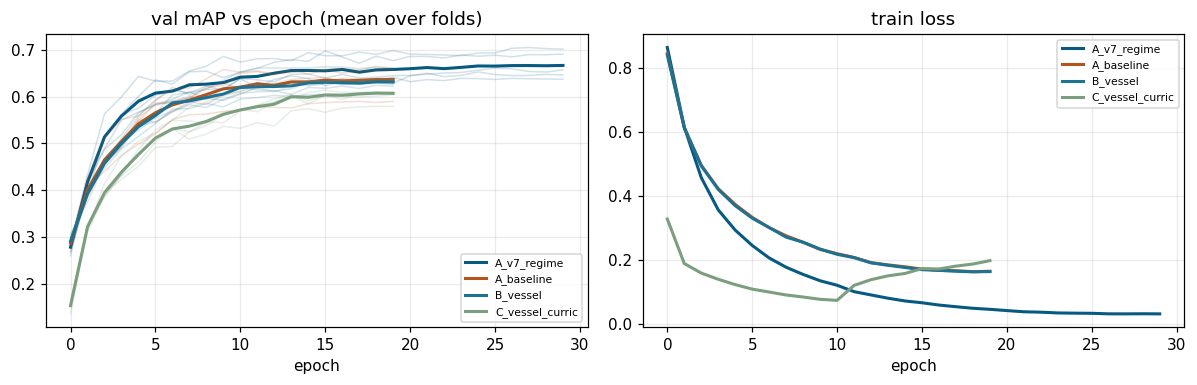

In [59]:
S1 = [rc.name for rc in STAGE1]
T1 = make_table(S1)
display(T1.round(4))

print("\nPaired bootstrap on out-of-fold mAP (same images, resampled; delta = row - reference)")
print("reference = A_baseline (v8 regime)")
display(compare_to("A_baseline", [n for n in S1 if n != "A_baseline"]).round(4))
if "A_v7_regime" in S1:
    print("\nWhat did change 2 (anti-overfitting regime) buy?  A_baseline (v8) vs A_v7_regime:")
    display(compare_to("A_v7_regime", ["A_baseline"]).round(4))


def load_hist(name):
    rc = RUN_REG[name]
    hs = [pd.read_csv(RUN_DIR / f"{name}_{rc.sig()}_f{k}_history.csv").assign(fold=k)
          for k in done_folds(name) if (RUN_DIR / f"{name}_{rc.sig()}_f{k}_history.csv").exists()]
    return pd.concat(hs) if hs else None

def plot_curves(names, ax_titles=("val mAP vs epoch (mean over folds)", "train loss")):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    cols = ["#065A82", "#B5541A", "#1C7293", "#7A9E7E", "#21295C", "#4A8DB7"]
    for n, c in zip(names, cols):
        h = load_hist(n)
        if h is None: continue
        for k, g in h.groupby("fold"):
            axes[0].plot(g["epoch"], g["val_mAP"], color=c, alpha=0.18, lw=1)
        axes[0].plot(h.groupby("epoch")["val_mAP"].mean(), color=c, lw=2, label=n)
        axes[1].plot(h.groupby("epoch")["train_loss"].mean(), color=c, lw=2, label=n)
    for a, t in zip(axes, ax_titles):
        a.set_title(t); a.set_xlabel("epoch"); a.grid(alpha=0.25); a.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(CFG.WORK_DIR / "figs/curves_stage1.png"); plt.show()

plot_curves(S1)

### Stage 3a — input resolution

`B_vessel` at 320 and 384 px (the 224 px row is `B_vessel` from stage 1).

In [60]:
STAGE3 = []
if CFG.RUN_RES_SWEEP:
    for s in CFG.RES_SWEEP:
        # keep the EFFECTIVE batch at 32 so only resolution changes; above 320 px split it 16 x 2 to stay inside a T4's memory
        bs, acc = (CFG.BATCH_SIZE, 1) if s <= 320 else (CFG.BATCH_SIZE // 2, 2)
        STAGE3.append(add(f"B_vessel_{s}px", use_vessel=True, input_size=int(s), batch_size=bs, accum_steps=acc))

t_stage = time.time()
for rc in STAGE3:
    run_recipe(rc)
print(f"\nresolution sweep finished in {(time.time() - t_stage) / 60:.1f} min")

if STAGE3:
    names = ["B_vessel"] + [rc.name for rc in STAGE3]
    display(make_table(names).round(4))
    print("\nResolution effect, paired bootstrap vs B_vessel at 224px:")
    display(compare_to("B_vessel", [rc.name for rc in STAGE3]).round(4))


=== B_vessel_320px | fold 0 | densenet121@320 | vessel=True curr=False loss=bce | 20 ep | train 2048 / val 512 ===


train:   0%|          | 0/64 [00:00<?, ?it/s]

  ep 00 | loss 0.8390 | val mAP 0.2934 (tail 0.1726) | AUC 0.7787 | best 0.2934@0 | 40s


train:   0%|          | 0/64 [00:00<?, ?it/s]

  ep 01 | loss 0.6059 | val mAP 0.3886 (tail 0.2459) | AUC 0.8631 | best 0.3886@1 | 27s


...

train:   0%|          | 0/128 [00:00<?, ?it/s]

  ep 19 | loss 0.1936 | val mAP 0.6061 (tail 0.3995) | AUC 0.9421 | best 0.6062@16 | 39s
[B_vessel_384px f4] done in 13.2 min  (best val mAP 0.6062 @ epoch 16)

resolution sweep finished in 112.4 min


,folds,OOF_mAP,OOF_mAP_foldstd,OOF_head,OOF_mid,OOF_tail,OOF_AUC,OOF_ECE_raw,OOF_ECE_cal,test_mAP,test_mAP_std,test_mAP_ens,test_tail_ok_ens,test_AUC_ens,test_F1_ens,test_tailF1_ens,test_ECE_raw,test_ECE_cal,test_ECE_cal_ens
recipe,,,,,,,,,,,,,,,,,,,
B_vessel,5,0.5996,0.0183,0.7797,0.6056,0.4127,0.9423,0.0393,0.0021,0.5523,0.0122,0.5766,0.4679,0.9485,0.5153,0.3366,0.0349,0.0041,0.0047
B_vessel_320px,5,0.6085,0.0164,0.7829,0.6183,0.4232,0.9447,0.0422,0.0017,0.5709,0.0063,0.5936,0.5302,0.9540,0.5051,0.2701,0.0379,0.0031,0.0034
B_vessel_384px,5,0.6010,0.0290,0.7818,0.6171,0.4021,0.9459,0.0554,0.0020,0.5713,0.0071,0.6045,0.5257,0.9547,0.4853,0.2206,0.0513,0.0035,0.0045



Resolution effect, paired bootstrap vs B_vessel at 224px:


,vs,folds,d_mAP,CI95,verdict,d_tail,CI95_tail
recipe,,,,,,,
B_vessel_320px,B_vessel,5,0.0089,"[-0.0081, +0.0230]",no clear difference,0.0105,"[-0.0382, +0.0430]"
B_vessel_384px,B_vessel,5,0.0014,"[-0.0168, +0.0217]",no clear difference,-0.0106,"[-0.0607, +0.0407]"


### Stage 3b — RETFound trial

Fold 0 only. Needs the gated RETFound weights (see §15c); skipped with instructions otherwise.

In [61]:
def _hf_token():
    tok = os.environ.get("HF_TOKEN")
    if tok:
        return tok
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        return None


def fetch_retfound():
    '''Return a local path to the RETFound MAE colour-fundus checkpoint, or None (the trial is
    then skipped and the rest of the notebook is unaffected).'''
    if CFG.RETFOUND_LOCAL and Path(CFG.RETFOUND_LOCAL).exists():
        return Path(CFG.RETFOUND_LOCAL)
    if Path("/kaggle/input").exists():
        hits = sorted(Path("/kaggle/input").rglob("RETFound*.pth"))
        if hits:
            return hits[0]
    try:
        from huggingface_hub import hf_hub_download
        return Path(hf_hub_download(repo_id=CFG.RETFOUND_REPO, filename=CFG.RETFOUND_FILE,
                                    token=_hf_token(), cache_dir=str(_TORCH_HOME / "hf")))
    except Exception as e:
        print("RETFound weights unavailable -> trial skipped.\n"
              f"  reason: {e.__class__.__name__}: {str(e)[:200]}\n"
              "  The weights are gated: (1) request access at "
              f"https://huggingface.co/{CFG.RETFOUND_REPO}, (2) create a read token, (3) add it as the\n"
              "  Kaggle secret HF_TOKEN (Add-ons > Secrets) and re-run this cell. Or download the .pth\n"
              "  yourself and set CFG.RETFOUND_LOCAL / attach it as a dataset. Internet must be ON.")
        return None


RETFOUND_PATH = fetch_retfound() if CFG.RUN_RETFOUND else None
RF_RECIPES = []
if RETFOUND_PATH is not None:
    print("RETFound checkpoint:", RETFOUND_PATH)
    rf = dict(backbone="retfound", input_size=224, epochs=CFG.RETFOUND_EPOCHS,
              lr_backbone=CFG.RETFOUND_LR_BACKBONE, lr_new=CFG.RETFOUND_LR_NEW,
              layer_decay=CFG.RETFOUND_LAYER_DECAY, warmup_epochs=2,
              batch_size=CFG.RETFOUND_BATCH, accum_steps=CFG.RETFOUND_ACCUM,
              drop_path=CFG.RETFOUND_DROP_PATH)
    RF_RECIPES = [add("A_retfound", use_vessel=False, **rf),      # backbone effect alone
                  add("B_retfound", use_vessel=True,  **rf)]      # backbone + vessel gates
    t_stage = time.time()
    for rc in RF_RECIPES:
        run_recipe(rc, folds=[k for k in CFG.RETFOUND_FOLDS if k in ACTIVE_FOLDS])
    print(f"\nRETFound trial finished in {(time.time() - t_stage) / 60:.1f} min")

    tf = [k for k in CFG.RETFOUND_FOLDS if k in ACTIVE_FOLDS]
    print(f"\nTrial = fold(s) {tf} only. DenseNet rows are restricted to the SAME fold(s) so the comparison is paired:")
    display(make_table(["A_baseline", "B_vessel", "A_retfound", "B_retfound"], folds=tf).round(4))
    print("Paired bootstrap on the trial fold(s) (few images and ~3 tail positives per class here:")
    print("read the sign and size, not the CI):")
    display(compare_to("B_vessel", ["A_retfound", "B_retfound"]).round(4))

RETFound_mae_natureCFP.pth: reconstructing file:   0%|          |  0.00B / 3.95GB            

RETFound_mae_natureCFP.pth: downloading bytes:           |  0.00B            

RETFound checkpoint: /kaggle/working/torch_cache/hf/models--YukunZhou--RETFound_mae_natureCFP/snapshots/556830f78214f0e8da35af965292ac5a3180ac47/RETFound_mae_natureCFP.pth
[RETFound] loaded 292/294 tensors from RETFound_mae_natureCFP.pth  (unexpected: ['norm.weight', 'norm.bias'], fc_norm initialised from encoder norm)

=== A_retfound | fold 0 | retfound@224 | vessel=False curr=False loss=bce | 12 ep | train 2048 / val 512 ===


train:   0%|          | 0/128 [00:00<?, ?it/s]

  ep 00 | loss 0.9277 | val mAP 0.1436 (tail 0.0200) | AUC 0.6416 | best 0.1436@0 | 94s


...

train:   0%|          | 0/128 [00:00<?, ?it/s]

  ep 11 | loss 0.3964 | val mAP 0.4860 (tail 0.3279) | AUC 0.9122 | best 0.4869@9 | 92s
[B_retfound f0] done in 18.9 min  (best val mAP 0.4869 @ epoch 9)

RETFound trial finished in 37.8 min

Trial = fold(s) [0] only. DenseNet rows are restricted to the SAME fold(s) so the comparison is paired:


,folds,OOF_mAP,OOF_mAP_foldstd,OOF_head,OOF_mid,OOF_tail,OOF_AUC,OOF_ECE_raw,OOF_ECE_cal,test_mAP,test_mAP_std,test_mAP_ens,test_tail_ok_ens,test_AUC_ens,test_F1_ens,test_tailF1_ens,test_ECE_raw,test_ECE_cal,test_ECE_cal_ens
recipe,,,,,,,,,,,,,,,,,,,
A_baseline,1,0.6409,0.0,0.7770,0.6436,0.5016,0.9330,0.0373,NaN,0.5628,0.0,0.5628,0.4677,0.9419,0.4603,0.2399,0.0344,0.0037,0.0037
B_vessel,1,0.6239,0.0,0.7758,0.6142,0.4829,0.9398,0.0347,NaN,0.5693,0.0,0.5693,0.4272,0.9387,0.4796,0.2829,0.0323,0.0031,0.0031
A_retfound,1,0.4833,0.0,0.6769,0.4455,0.3321,0.9078,0.1075,NaN,0.4409,0.0,0.4409,0.3372,0.8957,0.4010,0.1985,0.0991,0.0027,0.0027
B_retfound,1,0.4869,0.0,0.6905,0.4497,0.3250,0.9115,0.1067,NaN,0.4412,0.0,0.4412,0.3176,0.8976,0.4053,0.2385,0.0982,0.0029,0.0029


Paired bootstrap on the trial fold(s) (few images and ~3 tail positives per class here:
read the sign and size, not the CI):


,vs,folds,d_mAP,CI95,verdict,d_tail,CI95_tail
recipe,,,,,,,
A_retfound,B_vessel,1,-0.1406,"[-0.1883, -0.0824]",worse,-0.1507,"[-0.3074, -0.0053]"
B_retfound,B_vessel,1,-0.1371,"[-0.1905, -0.0815]",worse,-0.1578,"[-0.3140, -0.0141]"


### Stage 4 — ablating v7's G changes one at a time (§15d)

In [62]:
# v6's "E" recipe (vessel + ASL + mixup + SWA) is the base; each of v7's "G" changes is added ALONE.
E_BASE = dict(use_vessel=True, loss_type="asl", use_mixup=True, use_swa=True)

ABL = []
if CFG.RUN_ABLATION:
    ABL = [
        add("E0_v6_recipe",    **E_BASE),
        add("E1_asl_retuned",  **E_BASE, asl_gamma_neg=CFG.G_ASL_GAMMA_NEG, asl_clip=CFG.G_ASL_CLIP),
        add("E2_asl_warmup",   **E_BASE, asl_warmup_frac=CFG.G_ASL_WARMUP_FRAC),
        add("E3_mixup_milder", **E_BASE, mixup_alpha=CFG.G_MIXUP_ALPHA, mixup_prob=CFG.G_MIXUP_PROB),
        add("E4_oversample",   **E_BASE, use_oversample=CFG.G_USE_OVERSAMPLE),
        add("E5_gentler_lr",   **E_BASE, lr_backbone=CFG.G_LR_BACKBONE, lr_new=CFG.G_LR_NEW,
            warmup_epochs=CFG.G_WARMUP_EPOCHS),
    ]
    if CFG.RUN_LONG_VARIANTS:
        ABL += [
            add("E6_long_45ep", **E_BASE, epochs=CFG.G_EPOCHS),
            # all of v7's G changes at once (under v8's regime: LLRD, weight decay, stronger aug)
            add("G_all_v7", **E_BASE, asl_gamma_neg=CFG.G_ASL_GAMMA_NEG, asl_clip=CFG.G_ASL_CLIP,
                asl_warmup_frac=CFG.G_ASL_WARMUP_FRAC, mixup_alpha=CFG.G_MIXUP_ALPHA,
                mixup_prob=CFG.G_MIXUP_PROB, use_oversample=CFG.G_USE_OVERSAMPLE,
                lr_backbone=CFG.G_LR_BACKBONE, lr_new=CFG.G_LR_NEW,
                warmup_epochs=CFG.G_WARMUP_EPOCHS, epochs=CFG.G_EPOCHS),
        ]

t_stage = time.time()
for rc in ABL:
    run_recipe(rc, None if CFG.ABLATION_FOLDS is None else [k for k in CFG.ABLATION_FOLDS if k in ACTIVE_FOLDS])
print(f"\nablation finished in {(time.time() - t_stage) / 60:.1f} min")


=== E0_v6_recipe | fold 0 | densenet121@224 | vessel=True curr=False loss=asl | 20 ep | train 2048 / val 512 ===


train:   0%|          | 0/64 [00:00<?, ?it/s]

  ep 00 | loss 0.0397 | val mAP 0.2559 (tail 0.0460) | AUC 0.7752 | best 0.2559@0 | 15s


train:   0%|          | 0/64 [00:00<?, ?it/s]

  ep 01 | loss 0.0246 | val mAP 0.3815 (tail 0.1982) | AUC 0.8614 | best 0.3815@1 | 14s


...

train:   0%|          | 0/64 [00:00<?, ?it/s]

train:   0%|          | 0/64 [00:00<?, ?it/s]

train:   0%|          | 0/64 [00:00<?, ?it/s]

train:   0%|          | 0/64 [00:00<?, ?it/s]

  ep 19 | loss 0.0142 | val mAP 0.6101 (tail 0.4342) | AUC 0.9551 | best 0.6101@19 | 14s
  SWA val mAP 0.6234 vs best single epoch 0.6101
[E5_gentler_lr f2] done in 5.1 min  (best val mAP 0.6101 @ epoch 19, SWA)

ablation finished in 91.4 min


#### Stage 4 results

In [63]:
if ABL:
    names = ["B_vessel"] + [rc.name for rc in ABL]
    display(make_table(names).round(4))

    print("\nEach row vs E0 (the v6 recipe): did that ONE change from v7 help?")
    display(compare_to("E0_v6_recipe", [rc.name for rc in ABL if rc.name != "E0_v6_recipe"]).round(4))

    print("\nIs the whole ASL+mixup+SWA family better than plain vessel-guided BCE (B_vessel)?")
    display(compare_to("B_vessel", [rc.name for rc in ABL]).round(4))

    # does the sum of the parts explain v7's G?  (G_all vs the best single change)
    if "G_all_v7" in RUN_REG and done_folds("G_all_v7"):
        singles = [rc.name for rc in ABL if rc.name.startswith(("E1", "E2", "E3", "E4", "E5", "E6")) and done_folds(rc.name)]
        if singles:
            tbl = make_table(singles + ["G_all_v7"])
            best_single = tbl.loc[singles, "OOF_mAP"].idxmax()
            print(f"\nBest single change: {best_single}.  G_all_v7 vs {best_single}:")
            display(compare_to(best_single, ["G_all_v7"]).round(4))
else:
    print("CFG.RUN_ABLATION is False - skipped")

,folds,OOF_mAP,OOF_mAP_foldstd,OOF_head,OOF_mid,OOF_tail,OOF_AUC,OOF_ECE_raw,OOF_ECE_cal,test_mAP,test_mAP_std,test_mAP_ens,test_tail_ok_ens,test_AUC_ens,test_F1_ens,test_tailF1_ens,test_ECE_raw,test_ECE_cal,test_ECE_cal_ens
recipe,,,,,,,,,,,,,,,,,,,
B_vessel,5,0.5996,0.0183,0.7797,0.6056,0.4127,0.9423,0.0393,0.0021,0.5523,0.0122,0.5766,0.4679,0.9485,0.5153,0.3366,0.0349,0.0041,0.0047
E0_v6_recipe,3,0.5796,0.0217,0.7717,0.5989,0.3660,0.9411,0.1755,0.0015,0.5240,0.0065,0.5530,0.3736,0.9392,0.4776,0.2331,0.1710,0.0044,0.0045
E1_asl_retuned,3,0.5982,0.0195,0.7718,0.6147,0.4060,0.9473,0.1462,0.0029,0.5344,0.0053,0.5685,0.4134,0.9432,0.4827,0.2489,0.1425,0.0044,0.0052
E2_asl_warmup,3,0.5142,0.0043,0.7158,0.5175,0.3089,0.9255,0.1418,0.0017,0.4505,0.0077,0.4727,0.3179,0.9281,0.4258,0.1506,0.1372,0.0023,0.0024
E3_mixup_milder,3,0.6093,0.0211,0.7838,0.6100,0.4341,0.9484,0.1585,0.0023,0.5415,0.0079,0.5755,0.4224,0.9433,0.5051,0.2642,0.1545,0.0045,0.0041
E4_oversample,3,0.5905,0.0078,0.7414,0.5793,0.4522,0.9259,0.2097,0.0034,0.5221,0.0114,0.5628,0.4856,0.9118,0.4362,0.1443,0.2118,0.0032,0.0048
E5_gentler_lr,3,0.5802,0.0115,0.7714,0.5888,0.3795,0.9420,0.1879,0.0031,0.5240,0.0109,0.5492,0.3832,0.9420,0.4699,0.2359,0.1829,0.0043,0.0043



Each row vs E0 (the v6 recipe): did that ONE change from v7 help?


,vs,folds,d_mAP,CI95,verdict,d_tail,CI95_tail
recipe,,,,,,,
E1_asl_retuned,E0_v6_recipe,3,0.0186,"[+0.0006, +0.0288]",better,0.0400,"[-0.0125, +0.0698]"
E2_asl_warmup,E0_v6_recipe,3,-0.0654,"[-0.0965, -0.0413]",worse,-0.0571,"[-0.1465, +0.0056]"
E3_mixup_milder,E0_v6_recipe,3,0.0297,"[+0.0056, +0.0430]",better,0.0681,"[-0.0006, +0.1059]"
E4_oversample,E0_v6_recipe,3,0.0109,"[-0.0200, +0.0342]",no clear difference,0.0862,"[+0.0002, +0.1513]"
E5_gentler_lr,E0_v6_recipe,3,0.0006,"[-0.0169, +0.0143]",no clear difference,0.0135,"[-0.0371, +0.0482]"



Is the whole ASL+mixup+SWA family better than plain vessel-guided BCE (B_vessel)?


,vs,folds,d_mAP,CI95,verdict,d_tail,CI95_tail
recipe,,,,,,,
E0_v6_recipe,B_vessel,3,-0.0354,"[-0.0551, -0.0133]",worse,-0.0733,"[-0.1405, -0.0104]"
E1_asl_retuned,B_vessel,3,-0.0168,"[-0.0366, +0.0019]",no clear difference,-0.0333,"[-0.0897, +0.0128]"
E2_asl_warmup,B_vessel,3,-0.1008,"[-0.1290, -0.0772]",worse,-0.1304,"[-0.2050, -0.0703]"
E3_mixup_milder,B_vessel,3,-0.0057,"[-0.0271, +0.0129]",no clear difference,-0.0052,"[-0.0634, +0.0438]"
E4_oversample,B_vessel,3,-0.0245,"[-0.0564, +0.0008]",no clear difference,0.0129,"[-0.0762, +0.0860]"
E5_gentler_lr,B_vessel,3,-0.0348,"[-0.0565, -0.0161]",worse,-0.0599,"[-0.1197, -0.0072]"


### Summary — all recipes

,folds,OOF_mAP,OOF_mAP_foldstd,OOF_head,OOF_mid,OOF_tail,OOF_AUC,OOF_ECE_raw,OOF_ECE_cal,test_mAP,test_mAP_std,test_mAP_ens,test_tail_ok_ens,test_AUC_ens,test_F1_ens,test_tailF1_ens,test_ECE_raw,test_ECE_cal,test_ECE_cal_ens
recipe,,,,,,,,,,,,,,,,,,,
A_v7_regime,5,0.6340,0.0253,0.7926,0.6449,0.4631,0.9416,0.0138,0.0026,0.5740,0.0190,0.6217,0.5511,0.9541,0.5197,0.3517,0.0124,0.0052,0.0057
E3_mixup_milder,3,0.6093,0.0211,0.7838,0.6100,0.4341,0.9484,0.1585,0.0023,0.5415,0.0079,0.5755,0.4224,0.9433,0.5051,0.2642,0.1545,0.0045,0.0041
B_vessel_320px,5,0.6085,0.0164,0.7829,0.6183,0.4232,0.9447,0.0422,0.0017,0.5709,0.0063,0.5936,0.5302,0.9540,0.5051,0.2701,0.0379,0.0031,0.0034
A_baseline,5,0.6069,0.0263,0.7731,0.6189,0.4271,0.9408,0.0398,0.0024,0.5525,0.0069,0.5770,0.4940,0.9496,0.5185,0.3664,0.0355,0.0040,0.0042
B_vessel_384px,5,0.6010,0.0290,0.7818,0.6171,0.4021,0.9459,0.0554,0.0020,0.5713,0.0071,0.6045,0.5257,0.9547,0.4853,0.2206,0.0513,0.0035,0.0045
B_vessel,5,0.5996,0.0183,0.7797,0.6056,0.4127,0.9423,0.0393,0.0021,0.5523,0.0122,0.5766,0.4679,0.9485,0.5153,0.3366,0.0349,0.0041,0.0047
E1_asl_retuned,3,0.5982,0.0195,0.7718,0.6147,0.4060,0.9473,0.1462,0.0029,0.5344,0.0053,0.5685,0.4134,0.9432,0.4827,0.2489,0.1425,0.0044,0.0052
E4_oversample,3,0.5905,0.0078,0.7414,0.5793,0.4522,0.9259,0.2097,0.0034,0.5221,0.0114,0.5628,0.4856,0.9118,0.4362,0.1443,0.2118,0.0032,0.0048
E5_gentler_lr,3,0.5802,0.0115,0.7714,0.5888,0.3795,0.9420,0.1879,0.0031,0.5240,0.0109,0.5492,0.3832,0.9420,0.4699,0.2359,0.1829,0.0043,0.0043



Best 5-fold recipe by out-of-fold mAP: A_v7_regime  (OOF mAP 0.6340)
Versus the plain baseline:


,vs,folds,d_mAP,CI95,verdict,d_tail,CI95_tail
recipe,,,,,,,
A_v7_regime,A_baseline,5,0.0271,"[+0.0106, +0.0453]",better,0.0359,"[-0.0088, +0.0820]"


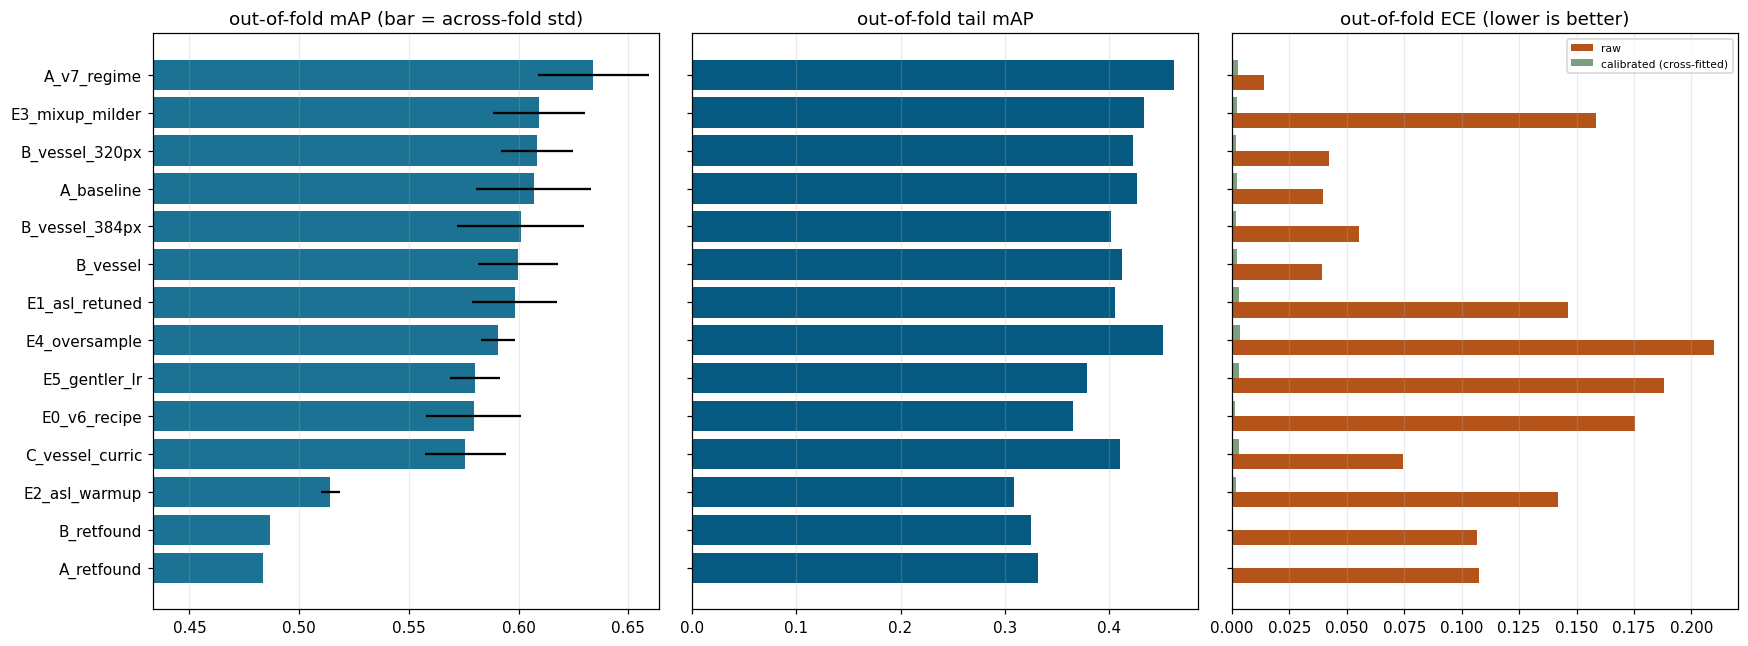

In [64]:
ALL_NAMES = [n for n in RUN_REG if len(done_folds(n)) > 0]
FINAL = make_table(ALL_NAMES)
FINAL.to_csv(CFG.WORK_DIR / "results/v8_all_recipes.csv")
display(FINAL.sort_values("OOF_mAP", ascending=False).round(4))

full = [n for n in ALL_NAMES if len(done_folds(n)) == len(ACTIVE_FOLDS) and n not in ("A_retfound", "B_retfound")]
if full:
    best = FINAL.loc[full, "OOF_mAP"].idxmax()
    print(f"\nBest 5-fold recipe by out-of-fold mAP: {best}  (OOF mAP {FINAL.loc[best, 'OOF_mAP']:.4f})")
    print("Versus the plain baseline:")
    if best != "A_baseline":
        display(compare_to("A_baseline", [best]).round(4))
    BEST_RECIPE = best

# ---- figure: OOF mAP (+- spread across folds) and calibration, all recipes -------------------
if len(FINAL):
    d = FINAL.sort_values("OOF_mAP")
    fig, axes = plt.subplots(1, 3, figsize=(16, max(3.6, 0.32 * len(d) + 1.5)))
    axes[0].barh(d.index, d["OOF_mAP"], xerr=d["OOF_mAP_foldstd"], color="#1C7293")
    axes[0].set_xlim(max(0, d["OOF_mAP"].min() - 0.05), d["OOF_mAP"].max() + 0.03)
    axes[0].set_title("out-of-fold mAP (bar = across-fold std)")
    axes[1].barh(d.index, d["OOF_tail"], color="#065A82"); axes[1].set_title("out-of-fold tail mAP")
    axes[1].set_yticklabels([])
    y = np.arange(len(d))
    axes[2].barh(y - 0.2, d["OOF_ECE_raw"], 0.4, label="raw", color="#B5541A")
    axes[2].barh(y + 0.2, d["OOF_ECE_cal"], 0.4, label="calibrated (cross-fitted)", color="#7A9E7E")
    axes[2].set_yticks(y); axes[2].set_yticklabels([]); axes[2].legend(fontsize=7)
    axes[2].set_title("out-of-fold ECE (lower is better)")
    for a in axes: a.grid(axis="x", alpha=0.25)
    plt.tight_layout(); plt.savefig(CFG.WORK_DIR / "figs/v8_overview.png"); plt.show()

### Metrics used in the reviewed papers (§15e)

The 15 reviewed papers report accuracy, F1 / macro-F1, AUC, sensitivity, Dice (segmentation only) and, once, ECE. This cell computes all of them for every finished 5-fold recipe, on the 640-image test split (5-model ensemble, OOF-fitted calibration and thresholds).

| Table | Content |
|---|---|
| 1 | All metrics × recipes (`acc_per_label`, `acc_exact`, F1 micro/macro/samples, AUC, sens/spec, ECE, normal-vs-abnormal screening, DR one-vs-rest) |
| 2 | 95 % bootstrap CIs for the headline metrics of the best recipe |
| 3 | Our numbers beside each paper's, with a like-for-like flag |
| 4 | Per-class sensitivity / specificity / F1 / AUC |

**Read Table 3 as context, not a ranking.** The papers use different datasets (APTOS, merged RFMiD 1.0+2.0), 4–10 classes and single-label accuracy; ours is 25-label multi-label on the official RFMiD split. Per-label accuracy in particular is inflated by the many negatives.

In [65]:
from sklearn.metrics import (confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score)

RISK_IDX = LABEL_COLS.index("Disease_Risk")      # normal-vs-abnormal screening label
DIAB_IDX = LABEL_COLS.index("DR")                # diabetic retinopathy (one-vs-rest)
OTHER_IDX = np.array([c for c in range(NUM_CLASSES) if c != RISK_IDX])


def _bin(yt, p, thr):
    '''Binary stats at threshold `thr`: accuracy, sensitivity (recall), specificity, precision, F1, AUC.'''
    yt = np.asarray(yt).astype(int)
    yb = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, yb, labels=[0, 1]).ravel()
    sens, spec = tp / max(tp + fn, 1), tn / max(tn + fp, 1)
    prec = tp / max(tp + fp, 1)
    return dict(acc=(tp + tn) / len(yt), sens=sens, spec=spec, prec=prec,
                f1=2 * prec * sens / max(prec + sens, 1e-12),
                auc=roc_auc_score(yt, p) if 0 < yt.sum() < len(yt) else np.nan)


def multilabel_metrics(yt, p, thr):
    '''Every metric the reviewed papers report, for a multi-label problem, at per-class thresholds `thr`.'''
    yt = np.asarray(yt).astype(int)
    yb = (p >= thr).astype(int)
    tp, fp = (yb & yt).sum(0), (yb & (1 - yt)).sum(0)
    fn, tn = ((1 - yb) & yt).sum(0), ((1 - yb) & (1 - yt)).sum(0)
    ok = yt.sum(0) > 0
    r = {
        "acc_per_label":  float((yb == yt).mean()),                 # = 1 - Hamming loss ("accuracy" in most papers)
        "acc_exact":      float((yb == yt).all(1).mean()),          # subset accuracy: every label right
        "F1_micro":       f1_score(yt, yb, average="micro",   zero_division=0),
        "F1_macro":       f1_score(yt[:, ok], yb[:, ok], average="macro", zero_division=0),
        "F1_weighted":    f1_score(yt, yb, average="weighted", zero_division=0),
        "F1_samples":     f1_score(yt, yb, average="samples",  zero_division=0),
        "precision_macro": precision_score(yt[:, ok], yb[:, ok], average="macro", zero_division=0),
        "sens_macro":     float(np.mean(tp[ok] / np.maximum(tp[ok] + fn[ok], 1))),   # sensitivity = recall
        "spec_macro":     float(np.mean(tn[ok] / np.maximum(tn[ok] + fp[ok], 1))),
        "AUC_macro":      float(np.nanmean(per_class_metrics(yt, p)[1])),
        "AUC_micro":      roc_auc_score(yt.ravel(), p.ravel()),
    }
    # single-label-style accuracy: is the top-ranked DISEASE among the true diseases? (images with >=1 disease)
    has = yt[:, OTHER_IDX].sum(1) > 0
    top = OTHER_IDX[p[has][:, OTHER_IDX].argmax(1)]
    r["top1_disease_hit"] = float(yt[has][np.arange(has.sum()), top].mean())
    return r


def _boot_ci(yt, p, thr, keys=("acc_per_label", "F1_micro", "F1_macro", "AUC_macro"), n=None, seed=0):
    n = n or CFG.N_BOOT
    rng, N = np.random.default_rng(seed), len(yt)
    vals = {k: [] for k in keys}
    for _ in range(n):
        ii = rng.integers(0, N, N)
        m = multilabel_metrics(yt[ii], p[ii], thr)
        for k in keys: vals[k].append(m[k])
    return {k: (float(np.nanpercentile(v, 2.5)), float(np.nanpercentile(v, 97.5))) for k, v in vals.items()}


def lit_metrics(name):
    '''Test-split metrics of the 5-model ensemble of `name`: probabilities calibrated by the OOF-fitted
    chain, per-class F1 thresholds fit on OOF predictions (the test split is used for nothing but scoring).'''
    o = load_oof(name)
    if o is None or len(o["folds"]) < 2:
        return None
    chain = fit_chain(o["z"], o["y"])
    thr = fit_thresholds(o["y"], apply_chain(chain, o["z"]))
    p = np.mean([apply_chain(chain, tz) for tz in o["test_z"].values()], 0)
    yt = Y["test"].astype(int)
    out = dict(name=name, folds=len(o["folds"]), thr=thr, p=p, yt=yt)
    out["multi"] = multilabel_metrics(yt, p, thr)
    out["ece"] = calibration_report(yt, p)
    out["screen"] = _bin(yt[:, RISK_IDX], p[:, RISK_IDX], thr[RISK_IDX])        # normal vs abnormal
    out["screen_05"] = _bin(yt[:, RISK_IDX], p[:, RISK_IDX], 0.5)
    out["dr"] = _bin(yt[:, DIAB_IDX], p[:, DIAB_IDX], thr[DIAB_IDX])            # diabetic retinopathy, one-vs-rest
    return out


LIT_NAMES = [n for n in RUN_REG if len(done_folds(n)) == len(ACTIVE_FOLDS)
             and not n.endswith("retfound") and n not in ("A_v7_regime",)]
LIT = {n: lit_metrics(n) for n in LIT_NAMES}
LIT = {n: v for n, v in LIT.items() if v is not None}

# ---- Table 1: every metric, every recipe (test split, 5-model ensemble) --------------------------------
rows = {}
for n, v in LIT.items():
    rows[n] = {**{k: x for k, x in v["multi"].items()},
               "mAP": classification_report_ml(v["yt"], v["p"])[0]["mAP"],
               "ECE": v["ece"]["ECE"], "Brier": v["ece"]["Brier"],
               "screen_acc": v["screen"]["acc"], "screen_sens": v["screen"]["sens"],
               "screen_spec": v["screen"]["spec"], "screen_AUC": v["screen"]["auc"],
               "DR_acc": v["dr"]["acc"], "DR_sens": v["dr"]["sens"], "DR_spec": v["dr"]["spec"],
               "DR_AUC": v["dr"]["auc"], "DR_F1": v["dr"]["f1"]}
LITTAB = pd.DataFrame(rows).T
LITTAB.to_csv(CFG.WORK_DIR / "results/v8_literature_metrics.csv")
print("Test split (640 images), 5-model ensemble, OOF-fitted calibration + thresholds")
display(LITTAB.round(4).T)

# ---- Table 2: 95% bootstrap CIs for the headline metrics of the best recipe ------------------------------
BEST_LIT = (max(LIT, key=lambda n: LITTAB.loc[n, "mAP"]) if LIT else None)
if BEST_LIT:
    v = LIT[BEST_LIT]
    ci = _boot_ci(v["yt"], v["p"], v["thr"])
    print(f"\nBest recipe by test mAP: {BEST_LIT}  - 95% bootstrap CI over the 640 test images")
    display(pd.DataFrame({k: {"value": v["multi"][k], "lo": a, "hi": b} for k, (a, b) in ci.items()}).T.round(4))

# ---- Table 3: our numbers next to what each reviewed paper reports (same metric, NOT same task) ----------
if BEST_LIT:
    m, s, d, e = LIT[BEST_LIT]["multi"], LIT[BEST_LIT]["screen"], LIT[BEST_LIT]["dr"], LIT[BEST_LIT]["ece"]
    P = lambda x: round(100 * x, 2)
    paper = [
        # ref, what the paper reports, their value, dataset/task, ours (same metric), how ours is defined, comparable?
        ("[6] CLARE-Net",  "Accuracy",   "75.38 %",  "RFMiD, 8 classes, single-label", f"{P(m['acc_exact'])} % (exact match) / {P(m['top1_disease_hit'])} % (top-1 hit)", "multi-label 25 classes", "no - different label space"),
        ("[6] CLARE-Net",  "Macro-F1",   "0.7428",   "RFMiD, 8 classes",               f"{m['F1_macro']:.4f}", "macro over 25 classes, OOF thresholds", "no - 25 classes incl. 8 rare"),
        ("[6] CLARE-Net",  "ECE",        "0.0649",   "RFMiD, 8 classes",               f"{e['ECE']:.4f}", "equal-mass bins, pooled over 25 sigmoid outputs", "no - different binning/outputs"),
        ("[8] DenseNet-121 study", "Accuracy", "88.48 %", "RFMiD 1.0+2.0, 10 classes", f"{P(m['acc_per_label'])} % (per-label)", "per-label accuracy, 25 classes", "no - per-label acc is inflated by negatives"),
        ("[8] DenseNet-121 study", "Macro-F1", "0.6974", "RFMiD 1.0+2.0, 10 classes", f"{m['F1_macro']:.4f}", "macro, 25 classes", "no - different classes"),
        ("[9] EfficientNetB0+CBAM", "F1 (tier 2)", "97 %", "RFMiD, 46 labels", f"{P(m['F1_micro'])} % (micro) / {P(m['F1_samples'])} % (samples)", "25 classes, official test split", "no - their split/label handling unclear"),
        ("[7] DenseNet + Grad-CAM", "Accuracy (binary DR)", "89.09 %", "APTOS 2019", f"{P(d['acc'])} % (DR one-vs-rest)", "RFMiD 'DR' label", "no - different dataset"),
        ("[1] ResNet50+U-Net", "Accuracy / AUC (DR)", "85.17 % / 0.946", "APTOS 2019", f"{P(d['acc'])} % / {d['auc']:.3f}", "RFMiD 'DR' one-vs-rest", "no - different dataset"),
        ("[9] tier-1 screening", "Normal vs abnormal", "n/a (see paper)", "RFMiD", f"acc {P(s['acc'])} %, sens {P(s['sens'])} %, spec {P(s['spec'])} %, AUC {s['auc']:.3f}", "Disease_Risk label", "closest like-for-like"),
        ("[3]/[4]/[11] segmenters", "Dice/F1, Sens, AUC (DRIVE)", "F1 0.7988 / 0.8276; Sens 84.65 %; AUC 98.84 %", "DRIVE vessels", "not applicable", "our segmenter is frozen HRM-UNet [3]; no vessel GT on RFMiD", "-"),
    ]
    PAPERTAB = pd.DataFrame(paper, columns=["ref", "paper metric", "paper value", "paper data / task",
                                            "ours (same metric)", "how ours is defined", "like-for-like?"])
    PAPERTAB.to_csv(CFG.WORK_DIR / "results/v8_vs_papers.csv", index=False)
    print(f"\nOur numbers ({BEST_LIT}) next to the reviewed papers. None share our task, so read these as context, not a ranking.")
    display(PAPERTAB)

# ---- Table 4: per-class sensitivity / specificity / F1 / AUC (the clinical view) --------------------------
if BEST_LIT:
    v = LIT[BEST_LIT]; yt, p, thr = v["yt"], v["p"], v["thr"]
    pc = []
    for c in range(NUM_CLASSES):
        b = _bin(yt[:, c], p[:, c], thr[c]) if 0 < yt[:, c].sum() < len(yt) else {}
        grp = "head" if c in HEAD_IDX else "tail" if c in TAIL_IDX else "mid"
        pc.append({"class": LABEL_COLS[c], "group": grp, "test_pos": int(yt[:, c].sum()), "thr": thr[c], **b})
    PCTAB = pd.DataFrame(pc).set_index("class")
    PCTAB.to_csv(CFG.WORK_DIR / "results/v8_per_class_sens_spec.csv")
    print(f"\nPer-class test metrics ({BEST_LIT}); sensitivity = recall")
    display(PCTAB.round(3))

Test split (640 images), 5-model ensemble, OOF-fitted calibration + thresholds


,A_baseline,B_vessel,C_vessel_curric,B_vessel_320px,B_vessel_384px
acc_per_label,0.9674,0.9700,0.9678,0.9709,0.9690
acc_exact,0.4938,0.5156,0.4484,0.5234,0.5094
F1_micro,0.7734,0.7878,0.7762,0.7972,0.7842
F1_macro,0.5185,0.5153,0.4942,0.5051,0.4853
F1_weighted,0.7719,0.7780,0.7669,0.7903,0.7832
F1_samples,0.6145,0.6210,0.6294,0.6392,0.6240
precision_macro,0.5861,0.6016,0.5682,0.5926,0.5550
sens_macro,0.5002,0.4920,0.4748,0.4760,0.4714
spec_macro,0.9773,0.9805,0.9747,0.9781,0.9789
AUC_macro,0.9496,0.9483,0.9219,0.9540,0.9547



Best recipe by test mAP: B_vessel_384px  - 95% bootstrap CI over the 640 test images


,value,lo,hi
acc_per_label,0.9690,0.9660,0.9718
F1_micro,0.7842,0.7646,0.8024
F1_macro,0.4853,0.4268,0.5286
AUC_macro,0.9547,0.9397,0.9668



Our numbers (B_vessel_384px) next to the reviewed papers. None share our task, so read these as context, not a ranking.


,ref,paper metric,paper value,paper data / task,ours (same metric),how ours is defined,like-for-like?
0,[6] CLARE-Net,Accuracy,75.38 %,"RFMiD, 8 classes, single-label",50.94 % (exact match) / 77.46 % (top-1 hit),multi-label 25 classes,no - different label space
1,[6] CLARE-Net,Macro-F1,0.7428,"RFMiD, 8 classes",0.4853,"macro over 25 classes, OOF thresholds",no - 25 classes incl. 8 rare
2,[6] CLARE-Net,ECE,0.0649,"RFMiD, 8 classes",0.0045,"equal-mass bins, pooled over 25 sigmoid outputs",no - different binning/outputs
3,[8] DenseNet-121 study,Accuracy,88.48 %,"RFMiD 1.0+2.0, 10 classes",96.9 % (per-label),"per-label accuracy, 25 classes",no - per-label acc is inflated by negatives
4,[8] DenseNet-121 study,Macro-F1,0.6974,"RFMiD 1.0+2.0, 10 classes",0.4853,"macro, 25 classes",no - different classes
5,[9] EfficientNetB0+CBAM,F1 (tier 2),97 %,"RFMiD, 46 labels",78.42 % (micro) / 62.4 % (samples),"25 classes, official test split",no - their split/label handling unclear
6,[7] DenseNet + Grad-CAM,Accuracy (binary DR),89.09 %,APTOS 2019,93.91 % (DR one-vs-rest),RFMiD 'DR' label,no - different dataset
7,[1] ResNet50+U-Net,Accuracy / AUC (DR),85.17 % / 0.946,APTOS 2019,93.91 % / 0.982,RFMiD 'DR' one-vs-rest,no - different dataset
8,[9] tier-1 screening,Normal vs abnormal,n/a (see paper),RFMiD,"acc 91.88 %, sens 93.48 %, spec 85.82 %, AUC 0...",Disease_Risk label,closest like-for-like
9,[3]/[4]/[11] segmenters,"Dice/F1, Sens, AUC (DRIVE)",F1 0.7988 / 0.8276; Sens 84.65 %; AUC 98.84 %,DRIVE vessels,not applicable,our segmenter is frozen HRM-UNet [3]; no vesse...,-



Per-class test metrics (B_vessel_384px); sensitivity = recall


,group,test_pos,thr,acc,sens,spec,prec,f1,auc
class,,,,,,,,,
Disease_Risk,head,506,0.50,0.919,0.935,0.858,0.961,0.948,0.977
DR,head,124,0.46,0.939,0.798,0.973,0.876,0.835,0.982
ARMD,head,31,0.28,0.964,0.710,0.977,0.611,0.657,0.972
MH,head,104,0.44,0.938,0.875,0.950,0.771,0.820,0.969
DN,head,46,0.26,0.917,0.326,0.963,0.405,0.361,0.888
MYA,head,32,0.56,0.983,0.750,0.995,0.889,0.814,0.995
BRVO,mid,23,0.26,0.975,0.739,0.984,0.630,0.680,0.947
TSLN,head,53,0.28,0.931,0.717,0.951,0.567,0.633,0.967
ERM,tail,5,0.04,0.972,0.600,0.975,0.158,0.250,0.922


---
## 16. Per-class results and interpretability

Refs [12] and [13] of the literature review report aggregates only, so whether their imbalance handling helped the tail is unverifiable. This table makes it verifiable: out-of-fold AP per class, with ~4× the positives per tail class that v7's single test split offered.

In [66]:
# ---- per-class view on the pooled OUT-OF-FOLD predictions (2,560 images) -------------------------
def oof_ap(name):
    o = load_oof(name)
    ap, auc = per_class_metrics(o["y"], _sig(o["z"]))
    return ap, auc, o

cmp_names = [n for n in ["A_baseline", "B_vessel", "C_vessel_curric"] if len(done_folds(n)) == len(ACTIVE_FOLDS)]
if "BEST_RECIPE" in globals() and BEST_RECIPE not in cmp_names:
    cmp_names.append(BEST_RECIPE)

grp = np.array(["mid"] * NUM_CLASSES, dtype=object)
grp[HEAD_IDX] = "head"; grp[TAIL_IDX] = "tail"
cols = {"label": LABEL_COLS, "group": grp, "pool_pos": Y["pool"].sum(0).astype(int)}
aps = {}
for n in cmp_names:
    aps[n], _, _o = oof_ap(n)
    cols[f"AP_{n}"] = aps[n].round(4)
base = "A_baseline" if "A_baseline" in aps else cmp_names[0]
for n in cmp_names:
    if n != base:
        cols[f"dAP_{n}"] = (aps[n] - aps[base]).round(4)
PER_CLASS = pd.DataFrame(cols).sort_values("pool_pos", ascending=False).reset_index(drop=True)
PER_CLASS.to_csv(CFG.WORK_DIR / "results/per_class_oof.csv", index=False)

_tail = PER_CLASS[PER_CLASS["group"] == "tail"]
print(f"tail classes: {len(_tail)}; median pooled positives per tail class: {_tail['pool_pos'].median():.0f} "
      f"(v7's single test split had a median of 4)")
for n in cmp_names:
    if n != base:
        print(f"  {n}: improved {int((_tail[f'dAP_{n}'] > 0).sum())}/{len(_tail)} tail classes, "
              f"{int((PER_CLASS[f'dAP_{n}'] > 0).sum())}/{len(PER_CLASS)} classes overall (vs {base})")
display(PER_CLASS)

tail classes: 8; median pooled positives per tail class: 20 (v7's single test split had a median of 4)
  B_vessel: improved 2/8 tail classes, 11/25 classes overall (vs A_baseline)
  C_vessel_curric: improved 2/8 tail classes, 4/25 classes overall (vs A_baseline)
  A_v7_regime: improved 5/8 tail classes, 19/25 classes overall (vs A_baseline)


,label,group,pool_pos,AP_A_baseline,AP_B_vessel,AP_C_vessel_curric,AP_A_v7_regime,dAP_B_vessel,dAP_C_vessel_curric,dAP_A_v7_regime
0,Disease_Risk,head,2025,0.9882,0.9890,0.9815,0.9872,0.0008,-0.0067,-0.0011
1,DR,head,508,0.9083,0.9089,0.8619,0.9222,0.0006,-0.0464,0.0139
2,MH,head,419,0.8655,0.8742,0.8605,0.8748,0.0087,-0.0050,0.0093
3,ODC,head,354,0.7220,0.7314,0.6490,0.7574,0.0094,-0.0730,0.0354
4,TSLN,head,251,0.7420,0.7448,0.7176,0.7509,0.0029,-0.0244,0.0089
5,DN,head,184,0.4115,0.3980,0.3274,0.4205,-0.0135,-0.0842,0.0090
6,ARMD,head,138,0.6887,0.7142,0.6718,0.7526,0.0255,-0.0169,0.0639
7,MYA,head,135,0.8587,0.8772,0.8477,0.8749,0.0185,-0.0109,0.0162
8,BRVO,mid,96,0.7767,0.7653,0.6775,0.8083,-0.0113,-0.0992,0.0316
9,ODP,mid,91,0.3671,0.3886,0.3175,0.4071,0.0215,-0.0496,0.0400


#### Vessel-guidance interpretability (B_vessel, fold-0 model)

Expect higher CAM–vessel agreement for vascular classes (DR, BRVO, CRVO) than non-vascular ones (MH, ODC…) and non-trivial `gamma` values *if* the prior is being used as intended. v7 found the opposite on both counts — this re-checks it with a better-regularised model.

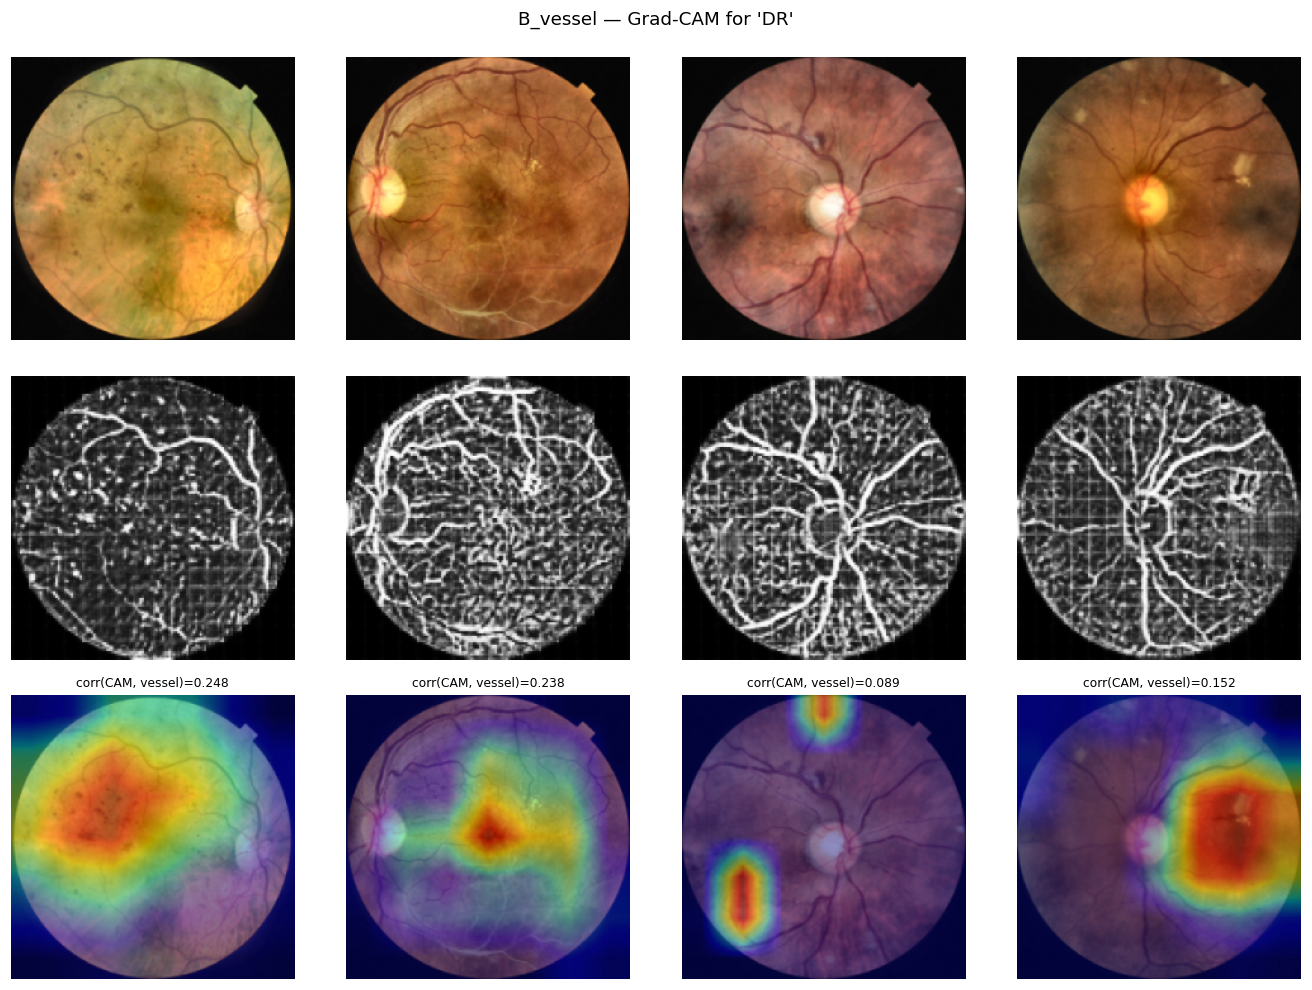

mean CAM-vessel correlation: 0.1817


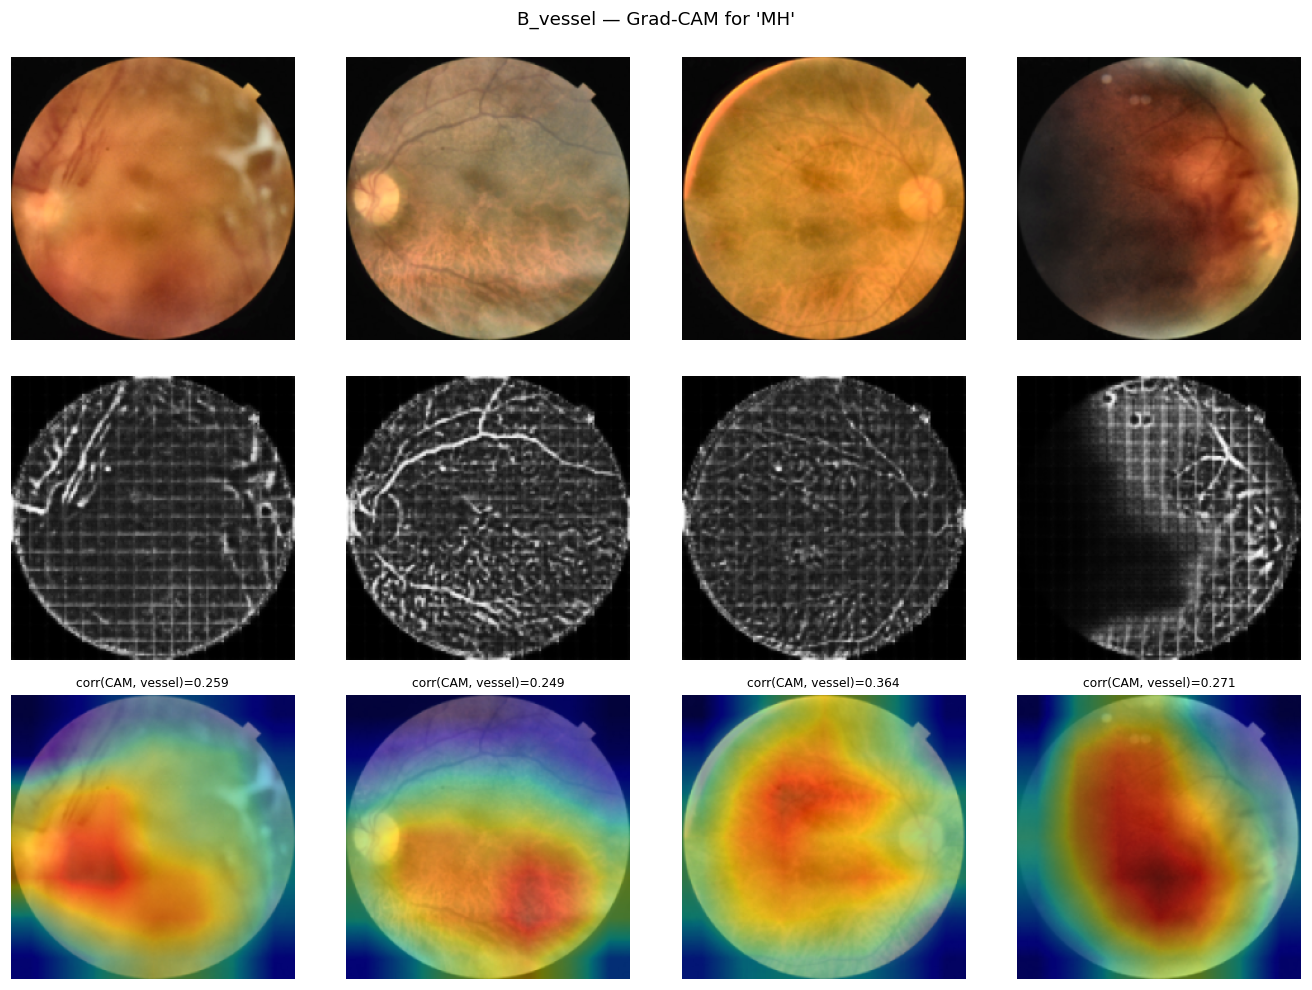

mean CAM-vessel correlation: 0.2856

Mean CAM-vessel correlation by class:
  DR     (vascular    ): 0.1817
  MH     (non-vascular): 0.2856

Learned fusion strength (gamma) per stage:
  stage 1: gamma = -0.1033
  stage 2: gamma = -0.2215
  stage 3: gamma = -0.2700
gamma > 0: the network chose to amplify vessel-aligned features at that scale; ~0: it ignored the prior.
Expectation if the prior is used as intended: CAM-vessel correlation HIGHER for vascular than non-vascular classes.

vessel confidence on the test set: mean=-0.996  std=0.002
map itself (sigmoid of a 1x1 MLP of avg-pooled vessels), so corr(attention, vessel) is a property of
the weights, not of the image. The curriculum's 'vessel misalignment' term (15% of sample difficulty)
therefore ranks samples by noise. A meaningful replacement is corr(Grad-CAM, vessel) per sample.


In [67]:
def load_trained(name, fold=0):
    '''Rebuild a DenseNet recipe's fold model from its saved checkpoint (kept for fold 0 only).'''
    rc = RUN_REG[name]
    assert rc.backbone == "densenet121", "Grad-CAM / vessel-correlation tooling is DenseNet-only"
    set_input_size(rc.input_size)
    m = VGDenseNet(NUM_CLASSES, use_vessel=rc.use_vessel, pretrained=False,
                   dropout=rc.head_dropout, drop_rate=rc.dense_drop)
    m.load_state_dict(torch.load(CFG.WORK_DIR / "ckpt" / f"{name}_f{fold}.pt", map_location="cpu"))
    return m.to(DEVICE).to(memory_format=torch.channels_last).eval()

best_vm = load_trained("B_vessel", 0)
vascular     = [c for c in ["DR", "BRVO", "CRVO", "HR"]   if c in LABEL_COLS]
non_vascular = [c for c in ["MH", "DN", "ODC", "ARMD"]    if c in LABEL_COLS]

corrs = {}
for c in (vascular[:1] + non_vascular[:1]):
    r = show_gradcam(best_vm, "test", class_name=c, n=4, tag="B_vessel")
    if r is not None:
        corrs[c] = r

print("\nMean CAM-vessel correlation by class:")
for k, v in corrs.items():
    print(f"  {k:6s} ({'vascular' if k in vascular else 'non-vascular':12s}): {v:.4f}")
print("\nLearned fusion strength (gamma) per stage:")
for s, g in best_vm.gates.items():
    print(f"  stage {s}: gamma = {g.gamma.item():+.4f}")
print("gamma > 0: the network chose to amplify vessel-aligned features at that scale; ~0: it ignored the prior.")
print("Expectation if the prior is used as intended: CAM-vessel correlation HIGHER for vascular than non-vascular classes.")

# ---- the 'vessel confidence' signal: a known-degenerate diagnostic -----------------------------
conf = compute_vessel_confidence(best_vm, make_loader("test", None, 64))
print(f"\nvessel confidence on the test set: mean={conf.mean():.3f}  std={conf.std():.3f}")
if conf.std() < 0.05:
    print("WARNING: this is ~constant. By construction the gate attention is a per-pixel function of the vessel\n"
          "map itself (sigmoid of a 1x1 MLP of avg-pooled vessels), so corr(attention, vessel) is a property of\n"
          "the weights, not of the image. The curriculum's 'vessel misalignment' term (15% of sample difficulty)\n"
          "therefore ranks samples by noise. A meaningful replacement is corr(Grad-CAM, vessel) per sample.")

#### Uncertainty triage (MC-dropout)

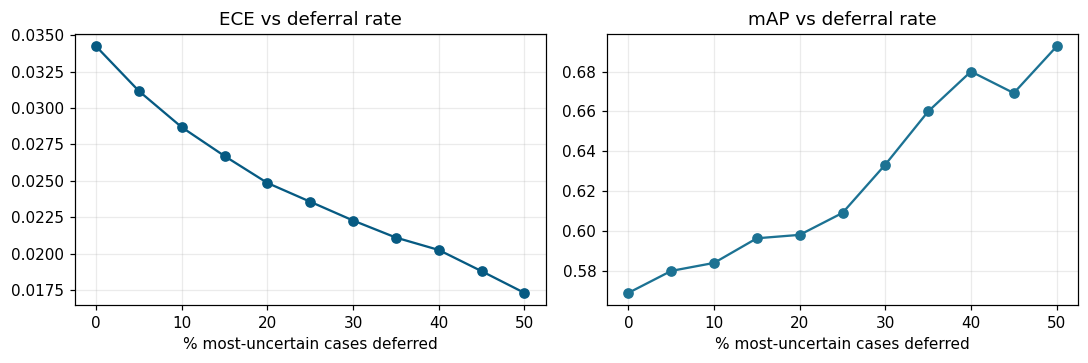

mAP at 0% / 20% / 50% deferral: 0.5689 / 0.5980 / 0.6926
A rising mAP / falling ECE trend means MC-dropout spread is informative for triage (the mechanism the reviewed literature cites but does not implement).


In [68]:
# ---- uncertainty triage: MC-dropout spread vs correctness (B_vessel, fold-0 model, official test) ----
test_loader = make_loader("test", None, 64)
mc_mean, mc_std, mc_t = predict_mc(best_vm, test_loader, CFG.MC_SAMPLES)

order = np.argsort(-mc_std.mean(1))          # most uncertain images first
frac = np.linspace(0.0, 0.5, 11)
ece_curve, map_curve = [], []
for f in frac:
    keep = order[int(f * len(order)):]           # defer the most uncertain f fraction
    ece_curve.append(ece_binary(mc_mean[keep], mc_t[keep]))
    map_curve.append(classification_report_ml(mc_t[keep], mc_mean[keep])[0]["mAP"])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(frac * 100, ece_curve, "o-", c="#065A82"); ax[0].set_title("ECE vs deferral rate")
ax[1].plot(frac * 100, map_curve, "o-", c="#1C7293"); ax[1].set_title("mAP vs deferral rate")
for a in ax:
    a.set_xlabel("% most-uncertain cases deferred"); a.grid(alpha=0.25)
plt.tight_layout(); plt.savefig(CFG.WORK_DIR / "figs/deferral.png"); plt.show()
print(f"mAP at 0% / 20% / 50% deferral: {map_curve[0]:.4f} / {map_curve[4]:.4f} / {map_curve[10]:.4f}")
print("A rising mAP / falling ECE trend means MC-dropout spread is informative for triage "
      "(the mechanism the reviewed literature cites but does not implement).")

---
## 17. Export

In [69]:
summary = {
    "version": "v8",
    "dataset": {"pool": len(DF["pool"]), "test": len(DF["test"]), "num_classes": NUM_CLASSES,
                "head": len(HEAD_IDX), "mid": len(MID_IDX), "tail": len(TAIL_IDX),
                "n_folds": CFG.N_FOLDS},
    "config": {k: str(v) for k, v in vars(CFG).items() if not k.startswith("_")},
    "recipes": {n: asdict(RUN_REG[n]) for n in RUN_REG},
    "results": json.loads(FINAL.to_json(orient="index")),
}
with open(CFG.WORK_DIR / "results/summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)

with open(CFG.WORK_DIR / "results/v8_all_recipes.md", "w") as f:
    try:
        f.write(FINAL.round(4).to_markdown())          # needs `tabulate`
    except ImportError:
        f.write(FINAL.round(4).to_string())

print("results:")
for p in sorted((CFG.WORK_DIR / "results").glob("*")): print("  ", p.name)
print("figures:")
for p in sorted((CFG.WORK_DIR / "figs").glob("*")):    print("  ", p.name)

results:
   folds.csv
   per_class_oof.csv
   summary.json
   v8_all_recipes.csv
   v8_all_recipes.md
   v8_literature_metrics.csv
   v8_per_class_sens_spec.csv
   v8_vs_papers.csv
figures:
   curves_stage1.png
   deferral.png
   gradcam_B_vessel_DR.png
   gradcam_B_vessel_MH.png
   label_distribution.png
   v8_overview.png
   vessel_check.png


In [70]:
import zipfile
from pathlib import Path
from IPython.display import FileLink

OUTPUT_DIR = Path("/kaggle/working")
ZIP_NAME = "kaggle_output.zip"

# Folders (relative to /kaggle/working) to leave OUT of the zip - edit as needed.
# torch_cache is just the downloaded pretrained-weight cache, not a result.
EXCLUDE = {"torch_cache", ".virtual_documents", "ckpt"}   # v8: checkpoints are rebuilt by re-running; keep the zip small

zip_path = OUTPUT_DIR / ZIP_NAME
if zip_path.exists():
    zip_path.unlink()

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in OUTPUT_DIR.rglob("*"):
        if not p.is_file() or p == zip_path:
            continue
        rel = p.relative_to(OUTPUT_DIR)
        if any(part in EXCLUDE for part in rel.parts):
            continue
        # work/cache holds ~2 GB of images; keep only the small vessel maps (reusable via CFG.REUSE_VESSEL_DIR)
        if "cache" in rel.parts and "_ves_" not in rel.name:
            continue
        zf.write(p, rel)

print(f"created {zip_path}  ({zip_path.stat().st_size / 1e6:.1f} MB)")
FileLink(ZIP_NAME)   # click the link that appears below this cell to download

created /kaggle/working/kaggle_output.zip  (175.0 MB)


/kaggle/working/kaggle_output.zip

---
## Extending this

- **Session limits** — everything expensive is cached under `CFG.WORK_DIR` (`cache/`, `runs/`); attach the previous session's output as a dataset and copy it back to resume.
- **Out of VRAM** — lower `Recipe.batch_size` (and raise `accum_steps` to keep the effective batch), or use a smaller `RES_SWEEP`.
- **More folds / repeated CV** — `CFG.N_FOLDS = 10`, or change `CFG.CV_SEED` and re-run for repeated CV (the result cache is keyed on both).
- **Un-CLAHE'd input for RETFound** — add a raw-colour image cache and a recipe flag; the pipeline is otherwise unchanged.
- **A meaningful vessel-confidence signal** — replace `corr(attention, vessel)` (a property of the weights, see §16) with `corr(Grad-CAM, vessel)` per sample before using it in the curriculum.
- **ODIR-5K generalisation** — reuse `preprocess`, `segment_vessels`, `build_cache`, map its 8 categories onto the RFMiD label space, evaluate frozen.
- **Full Dirichlet calibration** — `VectorScaler` is the diagonal case; swap in `nn.Linear(C, C)` with an off-diagonal L2 penalty in the L-BFGS closure.

---
## Appendix — v6/v7 research notes (kept for the record)

*Sections 15a and 15b below are unchanged from v7. Their expectations were written before any run; v7's results (G worse than E) are the reason §15d exists.*

---
## 15a. What actually improves this pipeline (research + rationale)

Before adding anything, the question was: given curriculum learning has now failed three
separate implementations on this exact task, what does the literature say actually works for
a **small (1920 image), severely long-tailed, multi-label** classification problem? Three
changes came out of that search, plus one that was deliberately **not** added despite being
the most obvious "free win."

**1. Asymmetric Loss (ASL) instead of pos_weight'd BCE.** In a 25-class sigmoid head with
~2 positives/image, ~23 negatives per image are overwhelmingly "easy," and their gradient
still dominates training even with a per-class `pos_weight` correction - `pos_weight` rescales
the loss, it doesn't stop easy negatives from swamping the gradient the way focal-style
down-weighting does. ASL (Ridnik et al. 2021, arXiv:2009.14119) decouples the focusing
exponent for positives vs. negatives and hard-clips very easy negatives out of the loss
entirely. It's specifically evidenced for this exact setting, not just multi-label in
general: CheXFusion's long-tailed chest X-ray classifier and the "Robust Asymmetric Loss"
paper (arXiv:2308.05542, arXiv:2308.03968) both use it for multi-label long-tailed *medical*
imaging specifically, which is a closer match to RFMiD than the original ASL paper's
MS-COCO/Open Images benchmarks.

**2. Mixup.** Blending image+vessel-map pairs (and computing the loss against both label
sets, weighted by the blend ratio - Section 12's `train_one_epoch`) is well-evidenced for
long-tailed classification specifically because it lets rare classes borrow information from
whichever image they were blended with, rather than only ever training on their own scarce
examples in isolation. The literature caveat (MONICA benchmark, arXiv:2410.02010) is that
"mixup does not always help" on its own - it works best combined with a class-imbalance-aware
loss, which is exactly the combination used in condition E (ASL + mixup together, not mixup
alone).

**3. Stochastic Weight Averaging (SWA).** With only 1920 training images and heavy
augmentation, validation mAP fluctuates a lot epoch to epoch (visible in every history CSV
so far) - picking a single "best" checkpoint risks picking a lucky epoch rather than a
genuinely better model. SWA averages weights over the last `SWA_START_FRAC` of training,
which is a standard fix for exactly this kind of noisy small-dataset convergence. It's kept
by validation comparison (Section 12): the run only switches to SWA weights if they actually
beat the best single-checkpoint epoch, so it can't make a run worse than not having it.

**4. Test-Time Augmentation was deliberately NOT added.** TTA (averaging predictions over
augmented test-time views) looks like a free accuracy win, but a controlled study specifically
on medical image classification (arXiv:2604.09697, "I Can't Believe TTA Is Not Better")
found it **hurt accuracy in 11 of 12 model-dataset combinations**, and got *worse* the more
augmented views were used - the opposite of what you'd expect from more test-time compute. The
mechanism identified is a BatchNorm statistics mismatch: the network's BatchNorm layers have
internalised the statistics of *unaugmented* training data, and augmented test inputs violate
those statistics in a way averaging doesn't fix. Given that finding, and that our own model
uses BatchNorm throughout (DenseNet-121), adding TTA here would be adopting a technique with
documented, mechanism-explained harm on the closest available evidence, purely because it
sounds like it should help. It's left out of condition E for that reason - not an oversight.

**Where this lands: condition E** (Section 15) is vessel guidance (B's recipe, not C's -
curriculum has no positive track record on this task) plus ASL + mixup + SWA, with the same
chained calibration applied afterward as F. This isolates the three additions from both the
curriculum question and the calibration question, so if E beats B, credit goes to §15a's
changes specifically, not to anything already validated in earlier sections.

---
## 15b. v7: closing the gap to the literature (research + rationale)

**The ask.** The literature review (15 reviewed papers) reports macro-F1 up to 0.6974-0.7428
and ECE as low as 0.0649 on RFMiD-family datasets. This section is v7's response: retune the
existing E/F recipe and add targeted strategies, **without changing the architecture**
(vessel-prior fusion, curriculum machinery, and chained calibration are all untouched).

**Honest framing first, because the comparison is not apples-to-apples.** The two closest
benchmarks - CLARE-Net (macro-F1 0.7428, ECE 0.0649, 8-class RFMiD) and the DenseNet-121 paper
(macro-F1 0.6974, 10-class merged RFMiD) - both evaluate on 8-10 classes. This pipeline
evaluates on 25 (after dropping unlearnable classes below `CFG.MIN_TRAIN_POS`). Macro-averaged
metrics get mechanically harder as class count grows, because more low-prevalence tail classes
enter the average and each one is estimated from only 5-8 test positives. **On calibration, the
pipeline is already ahead, not behind**: chained calibration already reaches ECE 0.0045-0.0049
(condition D/F), well below CLARE-Net's 0.0649 - so v7's tuning targets macro-F1, not ECE.

**What was actually retuned, and why (all isolated to a new condition, G):**

1. **ASL hyperparameters, retuned down.** `ASL_GAMMA_NEG` 4.0 -> **3.0**, `ASL_CLIP` 0.05 ->
   **0.08**. Condition E's raw ECE (0.148, ~10x every BCE condition) shows ASL's negative-
   focusing term was tuned too aggressively for RFMiD's scale of imbalance (`gamma_neg=4` comes
   from MS-COCO/Open-Images, both far larger and more extreme than RFMiD's 1920 images).
   Softening it should reduce the raw overconfidence at the source, rather than relying on
   calibration to clean it up after the fact.
2. **ASL warm-up (new).** The first `G_ASL_WARMUP_FRAC` (15%) of epochs train with plain BCE;
   only then does the loss switch to ASL. ASL's focusing term is defined by "how easy is this
   prediction already" - on a freshly initialised head, every prediction is arbitrary, so
   ASL's focusing has nothing meaningful to act on yet and can lock in bad early confidence.
3. **Milder mixup.** `MIXUP_ALPHA` 0.2 -> **0.15**, `MIXUP_PROB` 0.5 -> **0.4**. With some tail
   classes carrying single-digit positive counts, aggressive blending dilutes their already-
   scarce signal more than it regularises.
4. **Rarity-weighted oversampling (new).** A-F give every training image exactly one
   appearance per epoch and only reweight its *loss* contribution by class rarity. G instead
   resamples training images **with replacement** each epoch, proportional to the same
   class-rarity weight the curriculum already computes - so rare-positive images are
   physically seen more often per epoch, not just counted for more when they happen to appear.
   This changes batch *composition*, which loss reweighting alone never does, and directly
   targets recall on the classes macro-F1 penalises most.
5. **Gentler learning rates + longer warm-up.** `LR_BACKBONE` 1e-4 -> **8e-5**, `LR_NEW`
   1e-3 -> **7e-4**, `WARMUP_EPOCHS` 2 -> **3** - ASL's harder gradient shape benefits from a
   less aggressive early learning rate, consistent with the same overconfidence diagnosis above.
6. **Longer training.** `EPOCHS` 30 -> **45** for G only. SWA only starts averaging in the
   final quarter of training (`SWA_START_FRAC`); a 30-epoch budget gives it just 7-8 epochs to
   average over, a 45-epoch budget gives it ~11.
7. **Finer per-class threshold grid (applies to A-H).** `fit_thresholds()`'s search grid went
   from 19 points (step 0.05) to 49 points (step ~0.02) - several tail classes have so few
   validation positives that the coarser grid could only land within +-0.025 of the true
   F1-maximising cutoff. This is a pure evaluation-resolution fix, not a training change, so it
   is applied retroactively to every condition on re-run rather than only to G.

**What this does *not* do:** it does not touch the vessel-fusion architecture, the curriculum
machinery, or the calibration pipeline, and it does not alter A-F's code path or CFG defaults -
G is purely additive (see `fit()`'s new keyword arguments, all defaulting to A-F's original
values). A/B/C/D/E/F are expected to reproduce their existing numbers on re-run; only G/H are new.

**Expectation setting for the panel.** These changes target the largest identified lever
(ASL's overconfidence, and physically under-sampled tail images) with sound literature-backed
reasoning, but have **not yet been run** - v7 is delivered as code, the same way v3-v6 were.
Given the 25-vs-8-10-class gap above, matching CLARE-Net's macro-F1 exactly would require
either narrowing the evaluated class set to match it (defeats the point of this project's
long-tail framing) or a materially larger training set than RFMiD's 1920 images provides;
the realistic goal for G/H is a meaningful, defensible step up from F's macro-F1 (~0.48-0.50)
toward the literature range, not an exact match.